# Nhịp giao dịch và thời điểm sự kiện

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Audit Trx Monthly Coverage

Nguồn: `src/scripts/audit_trx_monthly_coverage.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/audit_trx_monthly_coverage.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Independently reconcile monthly chart against raw TRX parquet."""
from pathlib import Path
import json
import duckdb
import pandas as pd

out=Path('outputs/trx_monthly_audit'); out.mkdir(exist_ok=True)
c=duckdb.connect()
p="read_parquet('data/MBD-mini/detail/trx/**/*.parquet',hive_partitioning=true)"
m=c.execute(f"SELECT date_trunc('month',event_time) AS month,count(*) AS events,count(distinct client_id) AS active_clients FROM {p} GROUP BY 1 ORDER BY 1").df()
daily=c.execute(f"SELECT cast(event_time AS DATE) AS date,count(*) AS events FROM {p} GROUP BY 1 ORDER BY 1").df()
fold=c.execute(f"SELECT date_trunc('month',event_time) AS month,fold,count(*) AS events,count(distinct client_id) AS active_clients FROM {p} GROUP BY 1,2 ORDER BY 1,2").df()
c.close()
old=pd.read_csv('docs/report/tables/trx/trx_monthly_coverage.csv',parse_dates=['month'])
check=m.merge(old[['month','events','active_clients']],on='month',suffixes=('_raw','_report'),validate='one_to_one',how='outer',indicator=True)
assert check['_merge'].eq('both').all()
for col in ['events','active_clients']: assert check[f'{col}_raw'].eq(check[f'{col}_report']).all(),col
assert m.events.sum()==38764930
m['days']=m.month.dt.days_in_month
m['events_per_active']=m.events/m.active_clients
m['events_per_day']=m.events/m.days
m['events_per_active_calendar_day']=m.events/m.active_clients/m.days
for col in ['events','active_clients','events_per_active','events_per_day']:
    m[col+'_change_pct']=m[col].pct_change()*100
m.to_csv(out/'monthly_verified.csv',index=False)
check.to_csv(out/'reconciliation.csv',index=False)
fold.to_csv(out/'monthly_by_fold.csv',index=False)
daily.to_csv(out/'daily.csv',index=False)
calendar=pd.date_range(daily.date.min(),daily.date.max())
summary={'matched_months':len(m),'raw_rows':int(m.events.sum()),'zero_days_in_observed_span':len(calendar.difference(pd.DatetimeIndex(daily.date))), 'first_date':str(daily.date.min()), 'last_date':str(daily.date.max()),'note':'December 2020 is partial. Calendar-day rates are only meaningful for full months. Counts include original duplicate rows, matching the chart definition.'}
(out/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print(json.dumps(summary,indent=2))
print(m.loc[m.month.between('2021-12-01','2022-03-01')].to_string(index=False))

{
  "matched_months": 25,
  "raw_rows": 38764930,
  "zero_days_in_observed_span": 0,
  "first_date": "2020-12-31 00:00:00",
  "last_date": "2022-12-31 00:00:00",
  "note": "December 2020 is partial. Calendar-day rates are only meaningful for full months. Counts include original duplicate rows, matching the chart definition."
}
     month  events  active_clients  days  events_per_active  events_per_day  events_per_active_calendar_day  events_change_pct  active_clients_change_pct  events_per_active_change_pct  events_per_day_change_pct
2021-12-01 1771125           75887    31          23.338978    57133.064516                        0.752870           6.770303                   1.251518                      5.450570                   3.326099
2022-01-01 1423917           75307    31          18.908163    45932.806452                        0.609941         -19.603811                  -0.764294                    -18.984615                 -19.603811
2022-02-01 1423356           75241    

In [4]:
show_generated_results(__eda_started_ns, 'src/scripts/audit_trx_monthly_coverage.py')

### Kết quả: `src/scripts/audit_trx_monthly_coverage.py`

**outputs/trx_monthly_audit/daily.csv** — 5 dòng đầu

,date,events
0,2020-12-31,2547
1,2021-01-01,49526
2,2021-01-02,50337
3,2021-01-03,50352
4,2021-01-04,48002


**outputs/trx_monthly_audit/monthly_by_fold.csv** — 5 dòng đầu

,month,fold,events,active_clients
0,2020-12-01,0,501,451
1,2020-12-01,1,516,470
2,2020-12-01,2,541,485
3,2020-12-01,3,479,431
4,2020-12-01,4,510,449


**outputs/trx_monthly_audit/monthly_verified.csv** — 5 dòng đầu

,month,events,active_clients,days,events_per_active,events_per_day,events_per_active_calendar_day,events_change_pct,active_clients_change_pct,events_per_active_change_pct,events_per_day_change_pct
0,2020-12-01,2547,2286,31,1.114173,82.161290,0.035941,NaN,NaN,NaN,NaN
1,2021-01-01,1453778,69206,31,21.006531,46896.064516,0.677630,56978.052611,2927.384077,1785.391849,56978.052611
2,2021-02-01,1447642,69225,28,20.912127,51701.500000,0.746862,-0.422073,0.027454,-0.449404,10.246991
3,2021-03-01,1632087,70643,31,23.103308,52647.967742,0.745268,12.741064,2.048393,10.478040,1.830639
4,2021-04-01,1582437,71048,30,22.272787,52747.900000,0.742426,-3.042117,0.573305,-3.594813,0.189812


**outputs/trx_monthly_audit/reconciliation.csv** — 5 dòng đầu

,month,events_raw,active_clients_raw,events_report,active_clients_report,_merge
0,2020-12-01,2547,2286,2547,2286,both
1,2021-01-01,1453778,69206,1453778,69206,both
2,2021-02-01,1447642,69225,1447642,69225,both
3,2021-03-01,1632087,70643,1632087,70643,both
4,2021-04-01,1582437,71048,1582437,71048,both


File kết quả khác: `outputs/trx_monthly_audit/summary.json`

## Extend Eda Event Timing

Nguồn: `src/scripts/extend_eda_event_timing.py`. Chạy các ô của phần này theo thứ tự.

In [5]:
__file__ = str(ROOT / 'src/scripts/extend_eda_event_timing.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [6]:
"""Raw interevent gaps, Moscow calendars and dialog threshold-session sensitivity."""
import json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from complete_eda_figures_moscow import ROOT, OUT, BASE, publish, INDEX


def main():
    c=duckdb.connect();c.execute("SET memory_limit='3GB'");c.execute('SET threads=2')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp_event_timing'")
    ids=np.sort(pd.read_parquet(BASE/'labels_any.parquet').client_id.unique())
    summaries=[];calendars=[]
    for source in ['trx','geo','dialog']:
        print('Timing raw',source,flush=True)
        path=(ROOT/f'data/MBD-mini/detail/{source}/**/*.parquet').as_posix()
        dest=OUT/f'{source}_raw_interarrival.parquet'
        if not dest.exists():
            c.execute(f"""COPY (WITH gaps AS (
              SELECT client_id,epoch(event_time-lag(event_time) OVER(PARTITION BY client_id ORDER BY event_time))/3600.0 gap_hours
              FROM read_parquet('{path}'))
              SELECT client_id,count(*) events,count(gap_hours) gaps,avg(gap_hours) mean_gap_hours,
                median(gap_hours) median_gap_hours,stddev_pop(gap_hours) sd_gap_hours,max(gap_hours) max_gap_hours,
                count(*) FILTER(WHERE gap_hours=0) zero_gaps,
                CASE WHEN count(gap_hours)>=2 AND avg(gap_hours)>0 THEN stddev_pop(gap_hours)/avg(gap_hours) END cv
              FROM gaps GROUP BY client_id) TO '{dest.as_posix()}' (FORMAT PARQUET)""")
        q=pd.read_parquet(dest)
        assert (q.gaps==q.events-1).all()
        assert int(q.events.sum())=={'trx':38764930,'geo':66295724,'dialog':217205}[source]
        for col in ['mean_gap_hours','median_gap_hours','max_gap_hours','cv']:
            v=q[col].dropna()
            summaries.append(dict(source=source,metric=col,defined_customers=len(v),undefined_customers=len(ids)-len(v),
                median=float(v.median()),p90=float(v.quantile(.9)),p99=float(v.quantile(.99)),
                zero_gaps=int(q.zero_gaps.sum()),events=int(q.events.sum()),pairs=int(q.gaps.sum())))
        cal=c.execute(f"""SELECT cast(extract('isodow' FROM event_time+INTERVAL '3 hours') AS INTEGER) AS weekday,
            cast(extract('hour' FROM event_time+INTERVAL '3 hours') AS INTEGER) AS hour,count(*) events
            FROM read_parquet('{path}') GROUP BY 1,2""").df()
        cal['source']=source;calendars.append(cal)
    summary=pd.DataFrame(summaries);calendar=pd.concat(calendars,ignore_index=True)
    fig,axes=plt.subplots(1,3,figsize=(15,4.5))
    for ax,source in zip(axes,['trx','geo','dialog']):
        q=pd.read_parquet(OUT/f'{source}_raw_interarrival.parquet')
        v=q.cv.dropna();ax.hist(v,bins=60);ax.set_title(source);ax.set_xlabel('CV gap, trọng số bằng nhau mỗi khách');ax.set_ylabel('Số khách')
    publish('raw_interarrival_cv_all_sources',fig,summary,'Khoảng cách giữa mọi sự kiện liên tiếp và độ đều đặn',
        'Sắp timestamp trong cùng khách, nối qua ranh giới tháng. Gap giờ theo thời điểm UTC, không thay đổi khi chuyển Moscow. '
        'CV=SD tổng thể/mean, cần ≥2 gap và mean>0. Bảng cá thể của từng nguồn lưu Parquet; khách không nguồn/không đủ gap tính undefined.',
        'Đo độ biến động khoảng cách sự kiện, không đồng nhất với nhịp theo lịch hoặc phiên thực.',
        '; '.join(f'{r.source}: median CV={r.median:.3g}, n={r.defined_customers:,}, undefined={r.undefined_customers:,}' for r in summary[summary.metric=='cv'].itertuples()),
        'Thời gian nguồn bị cắt ở hai biên; khoảng nghỉ đầu/cuối chưa thấy không nằm trong gaps. Timestamp trùng có gap0, không tự đặt thứ tự trong timestamp. '
        'Không gọi CV cao là bot hoặc dữ liệu lỗi.')
    fig,axes=plt.subplots(1,3,figsize=(16,4.5))
    for ax,source in zip(axes,['trx','geo','dialog']):
        q=calendar[calendar.source==source].pivot(index='weekday',columns='hour',values='events').reindex(index=range(1,8),columns=range(24),fill_value=0)
        z=q.to_numpy()/q.to_numpy().sum()*100
        im=ax.imshow(z,aspect='auto',cmap='Blues');ax.set_title(source);ax.set_xlabel('Giờ Moscow');ax.set_yticks(range(7),['T2','T3','T4','T5','T6','T7','CN']);fig.colorbar(im,ax=ax,label='% sự kiện nguồn')
    publish('moscow_hour_weekday_all_sources',fig,calendar,'Giờ × thứ của ba nguồn theo Moscow',
        'Quét toàn bộ raw, cộng 3 giờ một lần từ giả định UTC để lấy lịch Moscow. Mỗi ô là % tổng sự kiện của nguồn. '
        'Đây là tỷ trọng sự kiện, không chuẩn hóa số lần xuất hiện của từng thứ trong khoảng nguồn.',
        'So mẫu lịch công bố giữa các nguồn, với thang màu riêng và tỷ trọng trong nguồn.',
        'Tổng sự kiện của mỗi heatmap khớp raw; ba nguồn có thời gian bắt đầu khác nhau nên không so trực tiếp số lượng tuyệt đối.',
        'Ngày có nhiễu ẩn danh và timezone ETL chưa xác minh; không suy lịch vận hành hoặc nghỉ lễ. '
        'Khách nhiều sự kiện có trọng số lớn; cần đọc cùng hình cân bằng khách.')
    raw=(ROOT/'data/MBD-mini/detail/dialog/**/*.parquet').as_posix()
    session=[]
    for threshold in [30,60]:
        q=c.execute(f"""WITH gaps AS (SELECT client_id,event_time,
          epoch(event_time-lag(event_time) OVER(PARTITION BY client_id ORDER BY event_time))/60.0 gap_min
          FROM read_parquet('{raw}')), grouped AS (
          SELECT *,sum(CASE WHEN gap_min IS NULL OR gap_min>{threshold} THEN 1 ELSE 0 END)
          OVER(PARTITION BY client_id ORDER BY event_time) sid FROM gaps),
          sessions AS (SELECT client_id,sid,count(*) AS rows,epoch(max(event_time)-min(event_time))/60.0 span_min
          FROM grouped GROUP BY 1,2)
          SELECT client_id,count(*) AS sessions,sum(rows) AS rows,avg(rows) mean_rows,median(span_min) median_span_min,
          max(span_min) max_span_min FROM sessions GROUP BY 1""").df()
        assert q.rows.sum()==217205
        q['threshold_minutes']=threshold;session.append(q)
    session=pd.concat(session,ignore_index=True)
    full=pd.MultiIndex.from_product([ids,[30,60]],names=['client_id','threshold_minutes']).to_frame(index=False)
    full=full.merge(session,on=['client_id','threshold_minutes'],how='left',validate='one_to_one')
    full['sessions']=full.sessions.fillna(0);full.to_parquet(OUT/'dialog_threshold_session_customers.parquet',index=False)
    s=full.groupby('threshold_minutes').agg(customers=('client_id','size'),sessions=('sessions','sum'),median_sessions=('sessions','median'),defined_span_customers=('median_span_min','count'),median_span_min=('median_span_min','median')).reset_index()
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    for threshold,q in full.groupby('threshold_minutes'):
        axes[0].hist(q.sessions,bins=np.arange(0,31),histtype='step',label=f'{threshold} phút')
        axes[1].hist(q.median_span_min.dropna(),bins=40,histtype='step',label=f'{threshold} phút')
    axes[0].set_xlabel('Số cụm sự kiện / toàn bộ khách');axes[1].set_xlabel('Trung vị độ trải timestamp cụm, phút')
    for ax in axes:ax.legend();ax.set_ylabel('Số khách')
    publish('dialog_threshold_session_sensitivity',fig,s,'Dialog: độ nhạy gom cụm sự kiện 30 / 60 phút',
        'Bắt đầu cụm mới nếu gap>30 hoặc >60 phút; cụm đầu luôn mới. Cụm nối các sự kiện trong cùng khách; '
        'span=max timestamp−min timestamp. Tất cả khách có trong bảng, không dialog có count0 nhưng span undefined. '
        'Histogram count phóng 0–30, khách vượt 30 vẫn giữ trong CSV/Parquet và tổng hợp.',
        'Kiểm tra việc chọn ngưỡng có đổi mạnh số cụm hay không; không xác nhận phiên hoặc thời lượng hội thoại thực.',
        '; '.join(f'{r.threshold_minutes} phút: {int(r.sessions):,} cụm, median số cụm/toàn khách={r.median_sessions:.1f}' for r in s.itertuples()),
        'Một dòng có span0 không nghĩa cuộc gọi 0 phút. Ngày nhiễu có thể phá khoảng cách thực giữa các lượt. '
        'Không có conversation/session ID để kiểm chứng; chỉ là cụm theo quy ước.')
    c.close()
    old=pd.read_csv(OUT/'figure_index.csv');idx=pd.concat([old,pd.DataFrame(INDEX)]).drop_duplicates('figure',keep='last');idx.to_csv(OUT/'figure_index.csv',index=False)
    status=json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'));status['done']+=['raw_interevent_gaps_cv_all_sources','moscow_hour_weekday_all_sources','dialog_threshold_session_sensitivity'];status['figures']=len(idx)
    (OUT/'execution_status.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')


if __name__=='__main__':main()

Timing raw trx


Timing raw geo


Timing raw dialog


Saved raw_interarrival_cv_all_sources


Saved moscow_hour_weekday_all_sources


Saved dialog_threshold_session_sensitivity


### Kết quả: `src/scripts/extend_eda_event_timing.py`

**outputs/eda_figures_moscow/dialog_threshold_session_sensitivity.png**

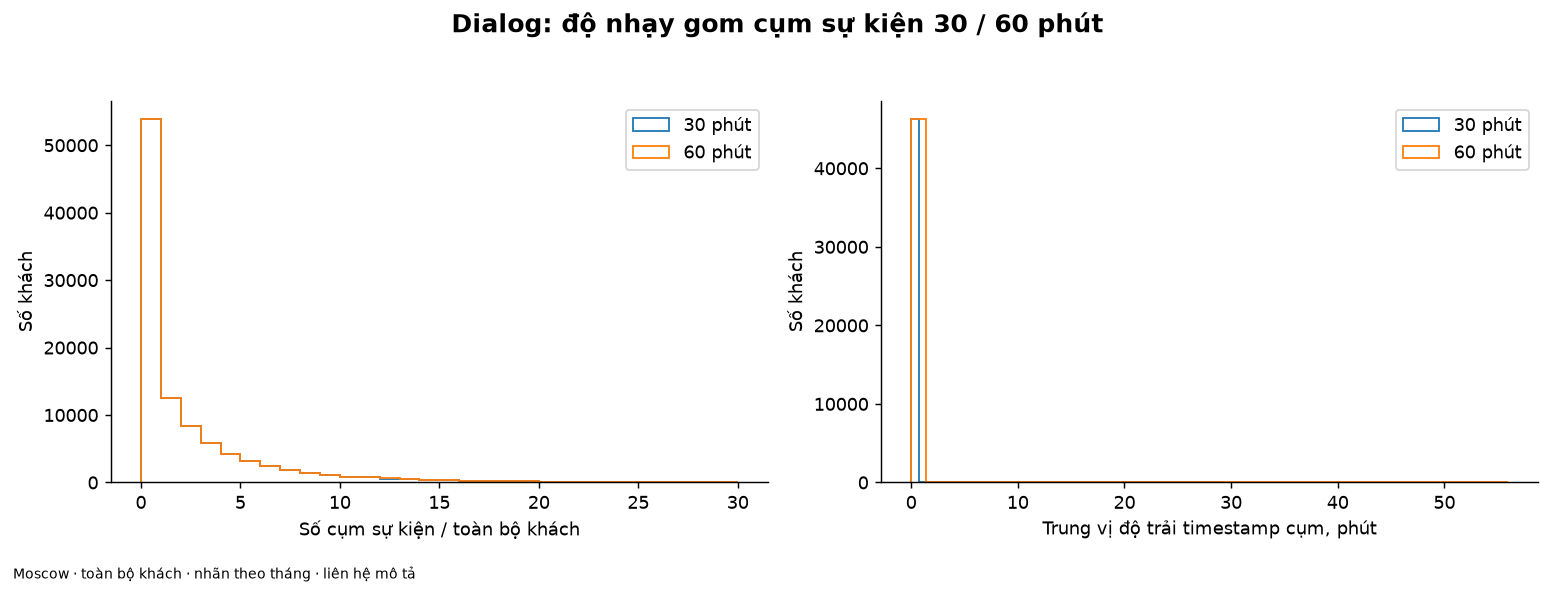

**outputs/eda_figures_moscow/moscow_hour_weekday_all_sources.png**

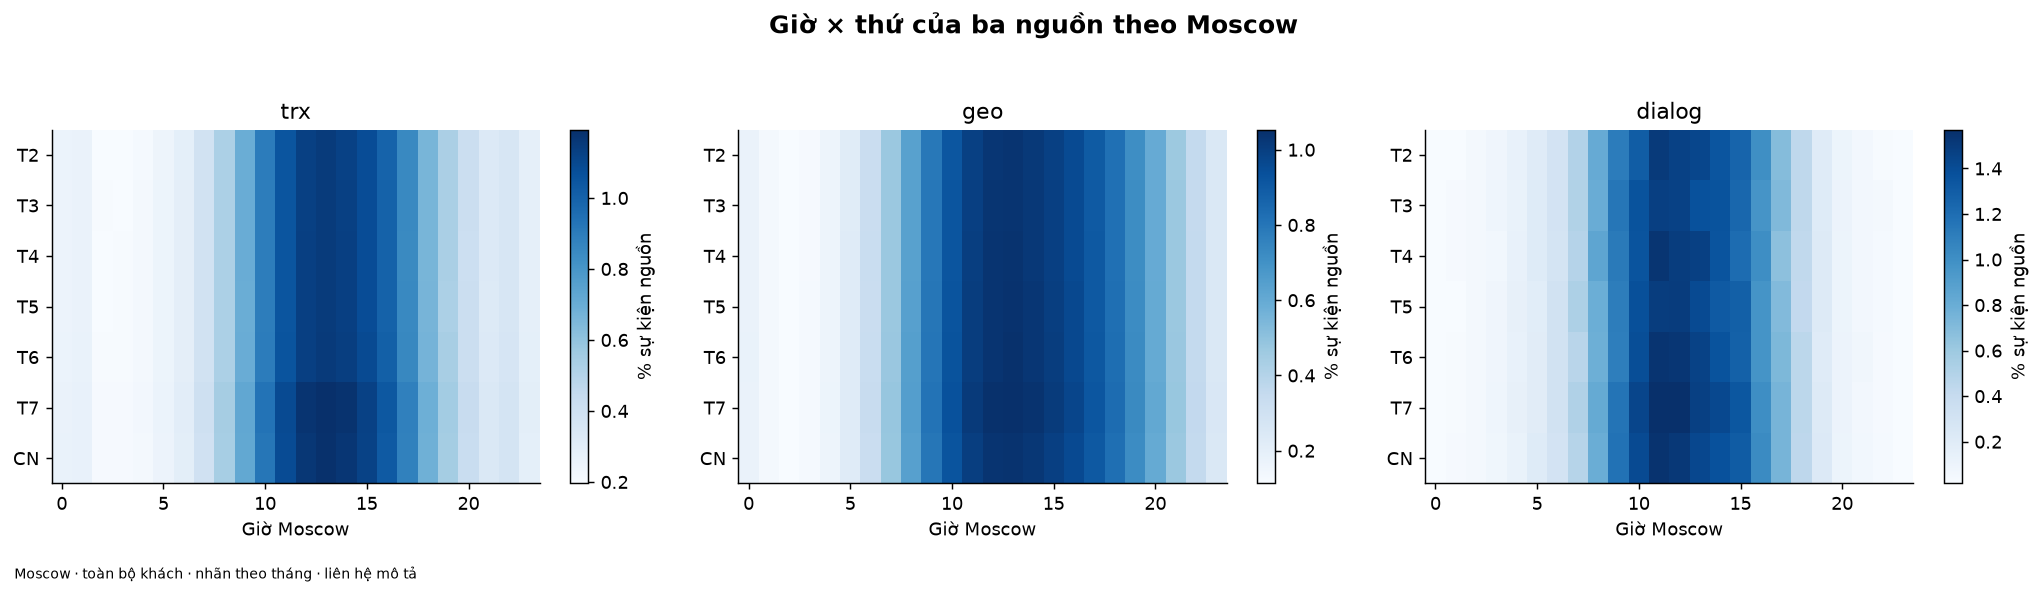

**outputs/eda_figures_moscow/raw_interarrival_cv_all_sources.png**

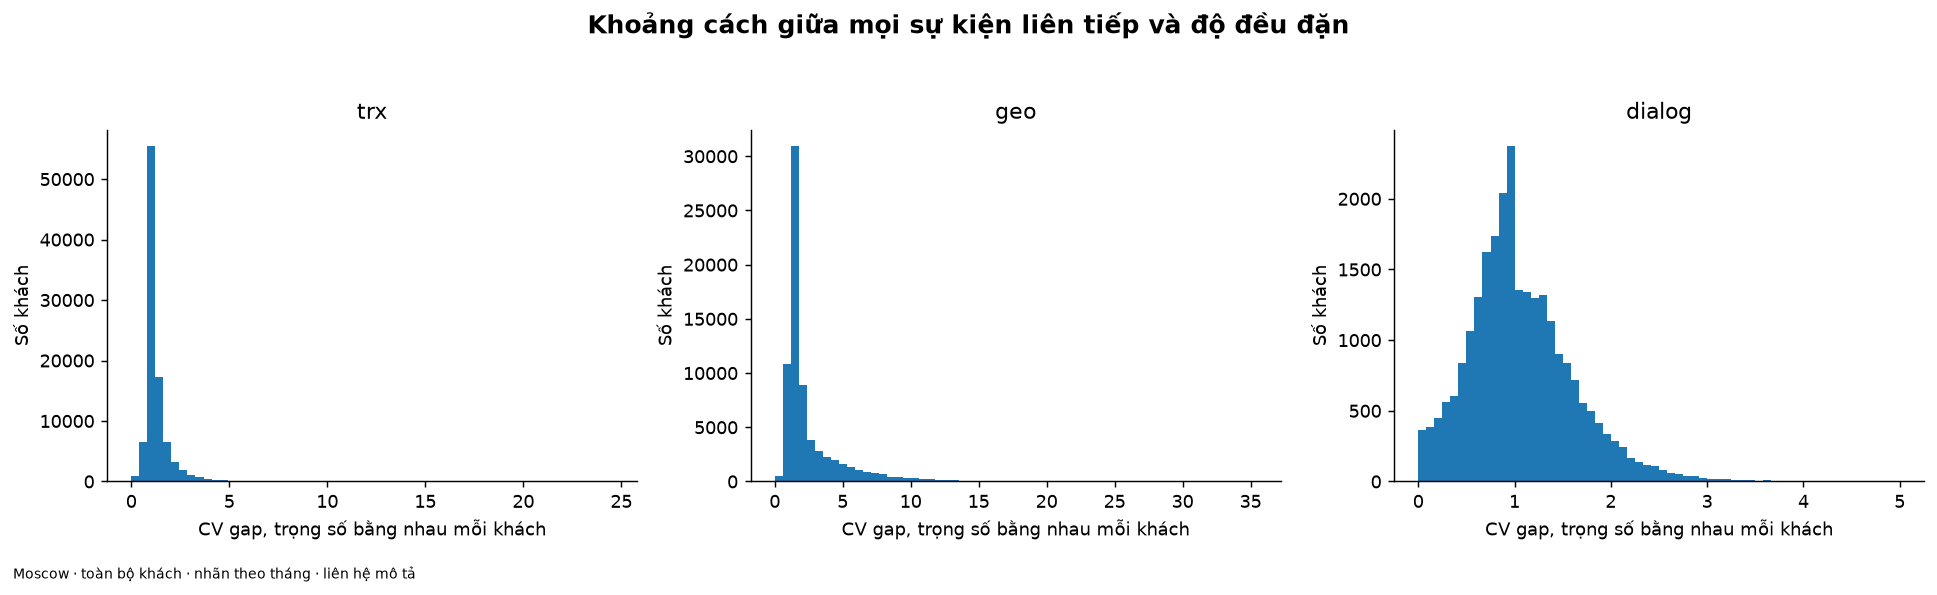

**outputs/eda_figures_moscow/dialog_threshold_session_sensitivity.csv** — 5 dòng đầu

,threshold_minutes,customers,sessions,median_sessions,defined_span_customers,median_span_min
0,30,100224,216434.0,0.0,46320,0.0
1,60,100224,215704.0,0.0,46320,0.0


**outputs/eda_figures_moscow/figure_index.csv** — 5 dòng đầu

,figure,title,data,explanation
0,all_history_recency_by_purchase_month,Recency toàn lịch sử trước đầu tháng mua,all_history_recency_by_purchase_month.csv,all_history_recency_by_purchase_month.md
1,baseline_amount11,amount11: thay đổi so với nền của chính khách,baseline_amount11.csv,baseline_amount11.md
2,baseline_dialog,dialog: thay đổi so với nền của chính khách,baseline_dialog.csv,baseline_dialog.md
3,baseline_dialog_active_days,dialog_active_days: thay đổi so với nền của ch...,baseline_dialog_active_days.csv,baseline_dialog_active_days.md
4,baseline_dialog_reactivation_30d,dialog_reactivation_30d: thay đổi so với nền c...,baseline_dialog_reactivation_30d.csv,baseline_dialog_reactivation_30d.md


**outputs/eda_figures_moscow/moscow_hour_weekday_all_sources.csv** — 5 dòng đầu

,weekday,hour,events,source
0,6,13,462282,trx
1,7,16,400106,trx
2,3,16,387192,trx
3,4,18,257247,trx
4,4,16,386869,trx


**outputs/eda_figures_moscow/raw_interarrival_cv_all_sources.csv** — 5 dòng đầu

,source,metric,defined_customers,undefined_customers,median,p90,p99,zero_gaps,events,pairs
0,trx,mean_gap_hours,96649,3575,80.940667,673.088341,4308.866554,1,38764930,38666209
1,trx,median_gap_hours,96649,3575,47.371907,400.635335,4151.885460,1,38764930,38666209
2,trx,max_gap_hours,96649,3575,621.193053,3703.041871,9651.696767,1,38764930,38666209
3,trx,cv,95002,5222,1.107361,1.951975,4.311310,1,38764930,38666209
4,geo,mean_gap_hours,71684,28540,15.068350,105.161047,839.764462,0,66295724,66223151


File kết quả khác: `outputs/eda_figures_moscow/dialog_threshold_session_customers.parquet`, `outputs/eda_figures_moscow/dialog_threshold_session_sensitivity.md`, `outputs/eda_figures_moscow/execution_status.json`, `outputs/eda_figures_moscow/moscow_hour_weekday_all_sources.md`, `outputs/eda_figures_moscow/raw_interarrival_cv_all_sources.md`

In [7]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_event_timing.py')

## Extend Eda Daily Moscow

Nguồn: `src/scripts/extend_eda_daily_moscow.py`. Chạy các ô của phần này theo thứ tự.

In [8]:
__file__ = str(ROOT / 'src/scripts/extend_eda_daily_moscow.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [9]:
"""Daily activity, exact elapsed-time reactivation and cross-source synchrony."""
from pathlib import Path
import json
import calendar
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from complete_eda_figures_moscow import ROOT, OUT, BASE, publish, INDEX, event_studies


def extract():
    c = duckdb.connect()
    c.execute("SET memory_limit='3GB'")
    c.execute('SET threads=2')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp_daily'")
    tables = {}
    for source in ['trx', 'geo', 'dialog']:
        dest = OUT / f'{source}_daily.parquet'
        if not dest.exists():
            print('Raw daily:', source, flush=True)
            path = (ROOT / f'data/MBD-mini/detail/{source}/**/*.parquet').as_posix()
            c.execute(f"""COPY (
                WITH daily AS (SELECT client_id, cast(event_time + INTERVAL '3 hours' AS DATE) AS "day",
                  count(*) events, min(event_time) first_utc, max(event_time) last_utc
                  FROM read_parquet('{path}') GROUP BY 1,2),
                gaps AS (SELECT *,lag(last_utc) OVER(PARTITION BY client_id ORDER BY "day") prev_utc FROM daily)
                SELECT *, epoch(first_utc-prev_utc)/86400.0 gap_days FROM gaps
                ) TO '{dest.as_posix()}' (FORMAT PARQUET)""")
        tables[source] = c.execute(f"SELECT * FROM read_parquet('{dest.as_posix()}')").df()
    c.close()
    return tables

In [10]:
def main():
    tables = extract()
    labels = pd.read_parquet(BASE / 'labels_any.parquet')
    ids = np.sort(labels.client_id.unique())
    panel = pd.read_parquet(BASE / 'all_customer_months.parquet')
    months = pd.date_range(panel.month.min(), panel.month.max(), freq='MS')
    y = labels.pivot(index='client_id', columns='month', values='y').reindex(index=ids, columns=months).to_numpy(dtype=float, copy=True)
    inventory = pd.read_csv(BASE / 'source_inventory.csv').set_index('source')
    arrays = {}
    quality = []
    states = []
    daily_sets = {}
    for source, d in tables.items():
        d['day'] = pd.to_datetime(d.day)
        d['month'] = d.day.dt.to_period('M').dt.to_timestamp()
        expected = int(inventory.loc[source, 'raw_rows'])
        assert int(d.events.sum()) == expected
        assert set(d.client_id).issubset(set(ids))
        assert not d.duplicated(['client_id', 'day']).any()
        first = pd.Timestamp(inventory.loc[source, 'first_month'])
        last = pd.Timestamp(inventory.loc[source, 'last_month'])
        partial = bool(inventory.loc[source, 'first_month_partial'])
        full = (months >= first) & (months <= last)
        if partial: full &= months != first
        days = d.groupby(['client_id', 'month']).size().unstack().reindex(index=ids, columns=months).fillna(0).to_numpy(dtype=float, copy=True)
        days[:, ~full] = np.nan
        arrays[f'{source}_active_days'] = days
        quality.append(dict(source=source, raw_events=expected, daily_events=int(d.events.sum()), customers=d.client_id.nunique()))
        for threshold in [30, 60, 90]:
            r = d[d.gap_days >= threshold].groupby(['client_id', 'month']).size().unstack().reindex(index=ids, columns=months).fillna(0).to_numpy(dtype=float, copy=True)
            r[:, ~full] = np.nan
            arrays[f'{source}_reactivation_{threshold}d'] = r
        # Separate first-observed from subsequent activity, with complete population reconciliation.
        first_month = d.groupby('client_id').month.min().reindex(ids)
        for j, m in enumerate(months):
            if not full[j]:
                states.append(dict(source=source, month=str(m.date()), state='Chưa đủ tháng nguồn', customers=len(ids)))
                continue
            active = days[:, j] > 0
            initial = (first_month == m).to_numpy()
            reactive = arrays[f'{source}_reactivation_30d'][:, j] > 0
            masks = {'Lần đầu thấy': active & initial, 'Tái xuất hiện ≥30d': active & ~initial & reactive,
                     'Có log khác': active & ~initial & ~reactive, 'Không log tháng này': ~active}
            assert np.vstack(list(masks.values())).sum(axis=0).min() == 1
            for name, mask in masks.items(): states.append(dict(source=source, month=str(m.date()), state=name, customers=int(mask.sum())))
        daily_sets[source] = d[['client_id', 'day', 'month']]
    # Event studies reuse the same exhaustive 12-anchor implementation.
    event_studies(ids, months, arrays, y)
    state = pd.DataFrame(states)
    assert state.groupby(['source', 'month']).customers.sum().eq(len(ids)).all()
    fig, axes = plt.subplots(3, 1, figsize=(14, 10))
    for ax, source in zip(axes, tables):
        z = state[state.source == source].pivot(index='month', columns='state', values='customers').fillna(0)
        (z/len(ids)*100).plot.bar(stacked=True, ax=ax, width=.9)
        ax.set_title(source); ax.set_ylabel('% toàn bộ khách'); ax.legend(fontsize=7, ncol=3)
    publish('reactivation_population_states', fig, state, 'Tái xuất hiện sau im lặng và lần đầu được quan sát',
        'Gap dùng thời điểm UTC thực giữa sự kiện đầu ngày và sự kiện cuối ngày trước đó của cùng khách; '
        'ngưỡng chính ≥30 ngày. Một khách mới được thấy trong tháng được ưu tiên nhóm lần đầu, sau đó tái xuất hiện, log khác, không log. '
        'Tháng đầu nguồn không trọn và ngoài nguồn giữ riêng. Các ngưỡng 60/90 có bộ hình event riêng.',
        'Tách lần đầu được quan sát khỏi hoạt động quay lại sau khoảng nghỉ đủ dài.',
        'Mỗi nguồn–tháng phân nhóm đủ 100.224 khách; các bảng event giữ đủ 12 tháng nhãn và cả hai phía thời gian.',
        'Khoảng im lặng là không thấy log; không chứng minh rời ngân hàng hoặc tracking liên tục. Ngày nguồn có thể đã được ẩn danh.')
    # Exact rotation-mean null: E(overlap) = |A| |B| / days-in-month.
    # This is identical to averaging every cyclic shift, eliminating Monte Carlo noise.
    pair_rows = []
    for sa, sb in [('trx', 'geo'), ('trx', 'dialog'), ('geo', 'dialog')]:
        a, b = daily_sets[sa], daily_sets[sb]
        na = a.groupby(['client_id', 'month']).size().rename('days_a')
        nb = b.groupby(['client_id', 'month']).size().rename('days_b')
        overlap = a.merge(b, on=['client_id', 'day', 'month']).groupby(['client_id', 'month']).size().rename('overlap')
        z = pd.concat([na, nb, overlap], axis=1).fillna(0).reset_index()
        z['expected'] = z.days_a*z.days_b/z.month.dt.days_in_month
        z['excess'] = z.overlap-z.expected
        z['union'] = z.days_a+z.days_b-z.overlap
        for m in months:
            valid = True
            for s in [sa, sb]:
                first = pd.Timestamp(inventory.loc[s, 'first_month']); last = pd.Timestamp(inventory.loc[s, 'last_month'])
                valid &= first <= m <= last and not (bool(inventory.loc[s, 'first_month_partial']) and first == m)
            q = z[z.month == m]
            pair_rows.append(dict(pair=f'{sa} × {sb}', month=str(m.date()), observed_customers=len(ids) if valid else 0,
                unavailable=0 if valid else len(ids), both_active=int(((q.days_a>0)&(q.days_b>0)).sum()) if valid else 0,
                overlap_days=float(q.overlap.sum()/len(ids)) if valid else np.nan,
                expected_days=float(q.expected.sum()/len(ids)) if valid else np.nan,
                excess_days=float(q.excess.sum()/len(ids)) if valid else np.nan,
                jaccard_pooled=float(q.overlap.sum()/q.union.sum()) if valid and q.union.sum() else np.nan))
    sync = pd.DataFrame(pair_rows)
    fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
    for ax, (pair, q) in zip(axes, sync.groupby('pair')):
        ax.plot(pd.to_datetime(q.month), q.overlap_days, 'o-', label='Đồng hoạt động quan sát')
        ax.plot(pd.to_datetime(q.month), q.expected_days, '--', label='Kỳ vọng dịch vòng chính xác')
        ax.set_title(pair); ax.set_ylabel('Ngày / toàn bộ khách'); ax.legend(fontsize=8); ax.grid(alpha=.2)
    publish('cross_source_daily_synchrony', fig, sync, 'Đồng hoạt động cùng ngày giữa các nguồn',
        'Ngày Moscow; đếm giao ngày từng cặp nguồn trong từng khách–tháng, gồm khách zero. '
        'Kỳ vọng trung bình của TOÀN BỘ phép dịch vòng ngày trong tháng là days_a × days_b / số ngày tháng; '
        'dùng công thức chính xác thay 199 lượt ngẫu nhiên. Đây là kỳ vọng đối chứng, chưa phải kiểm định hay CI. '
        'Tháng không đủ một trong hai nguồn giữ unavailable.',
        'So số ngày đồng hoạt động với mức kỳ vọng từ lượng ngày hoạt động của chính từng khách.',
        'Khoảng cách giữa đường quan sát và kỳ vọng biểu thị đồng bộ vượt mức kỳ vọng dịch vòng. '
        'CSV có excess, Jaccard gộp và n cả hai nguồn; không suy nhân quả hoặc thứ tự trong ngày.',
        'Đối chứng dịch vòng không bảo toàn lịch thứ hoặc xu hướng trong tháng. Nhiễu ngày liên bảng chưa xác minh. '
        'Chưa phân tầng TRX, chưa có CI và chưa tính đồng thời cả ba nguồn.')
    pd.DataFrame(quality).to_csv(OUT / 'daily_validation.csv', index=False)
    old = pd.read_csv(OUT / 'figure_index.csv')
    pd.concat([old, pd.DataFrame(INDEX)]).drop_duplicates('figure', keep='last').to_csv(OUT/'figure_index.csv', index=False)
    status = json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'))
    status['done'] += ['raw_daily_activity', 'active_days_event_studies', 'reactivation_30_60_90', 'pairwise_exact_rotation_mean_synchrony']
    status['pending'] = [s for s in status['pending'] if s not in ['daily_reactivation_30_60_90']]
    status['synchrony_method_change'] = 'Exact expectation across all cyclic shifts replaces 199 Monte Carlo shifts; no p-value claimed'
    status['figures'] = len(pd.read_csv(OUT/'figure_index.csv'))
    (OUT/'execution_status.json').write_text(json.dumps(status, ensure_ascii=False, indent=2), encoding='utf-8')

In [11]:
if __name__ == '__main__': main()

Saved event_trx_active_days


Saved event_trx_active_days_by_anchor


Saved baseline_trx_active_days


Saved event_trx_reactivation_30d


Saved event_trx_reactivation_30d_by_anchor


Saved baseline_trx_reactivation_30d


... (28 outputs left out)

Saved event_dialog_reactivation_90d_by_anchor


Saved baseline_dialog_reactivation_90d


Saved reactivation_population_states


Saved cross_source_daily_synchrony


### Kết quả: `src/scripts/extend_eda_daily_moscow.py`

**outputs/eda_figures_moscow/baseline_dialog_active_days.png**

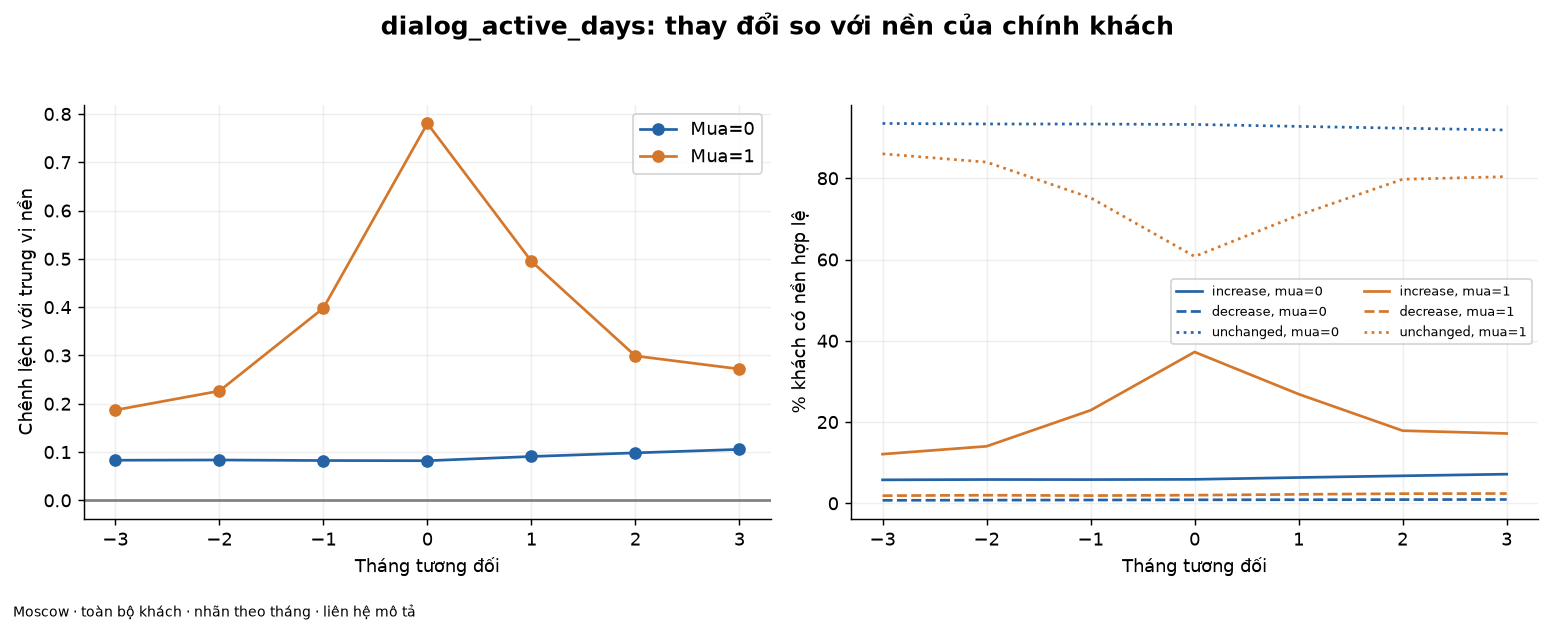

**outputs/eda_figures_moscow/baseline_dialog_reactivation_30d.png**

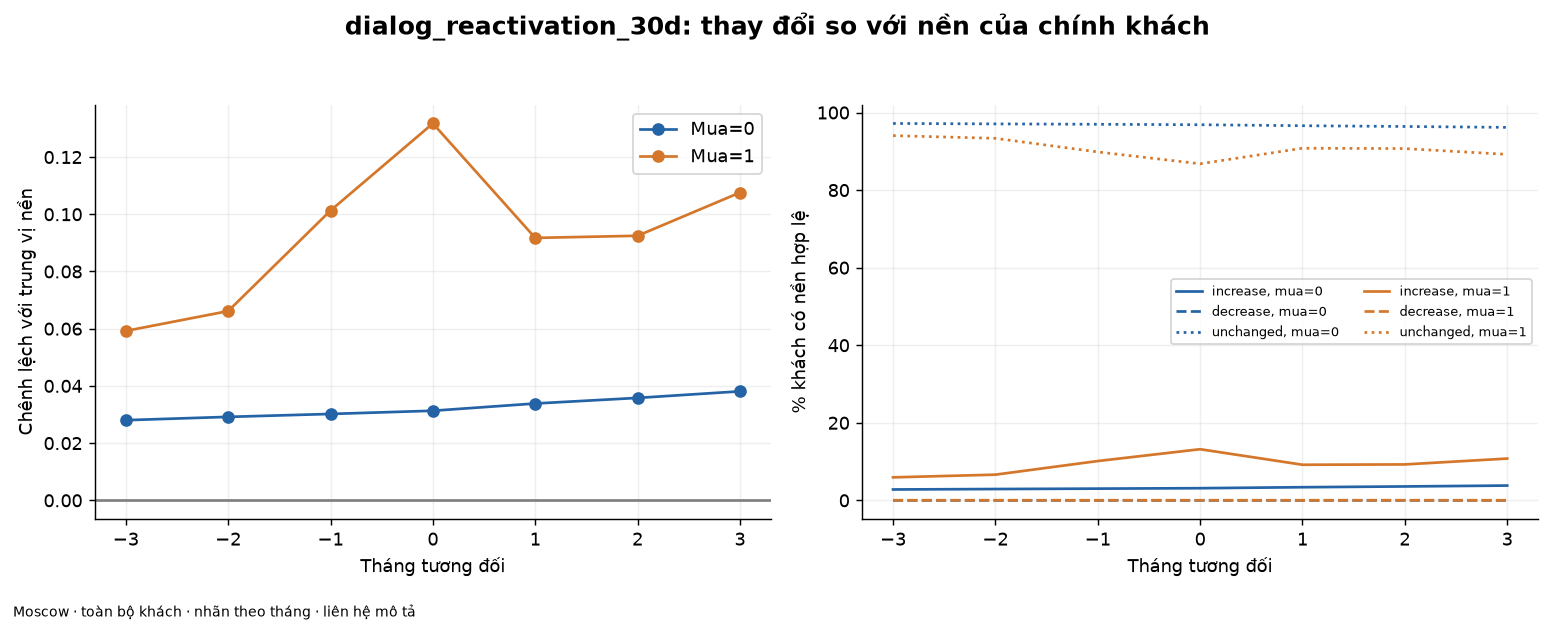

**outputs/eda_figures_moscow/baseline_dialog_reactivation_60d.png**

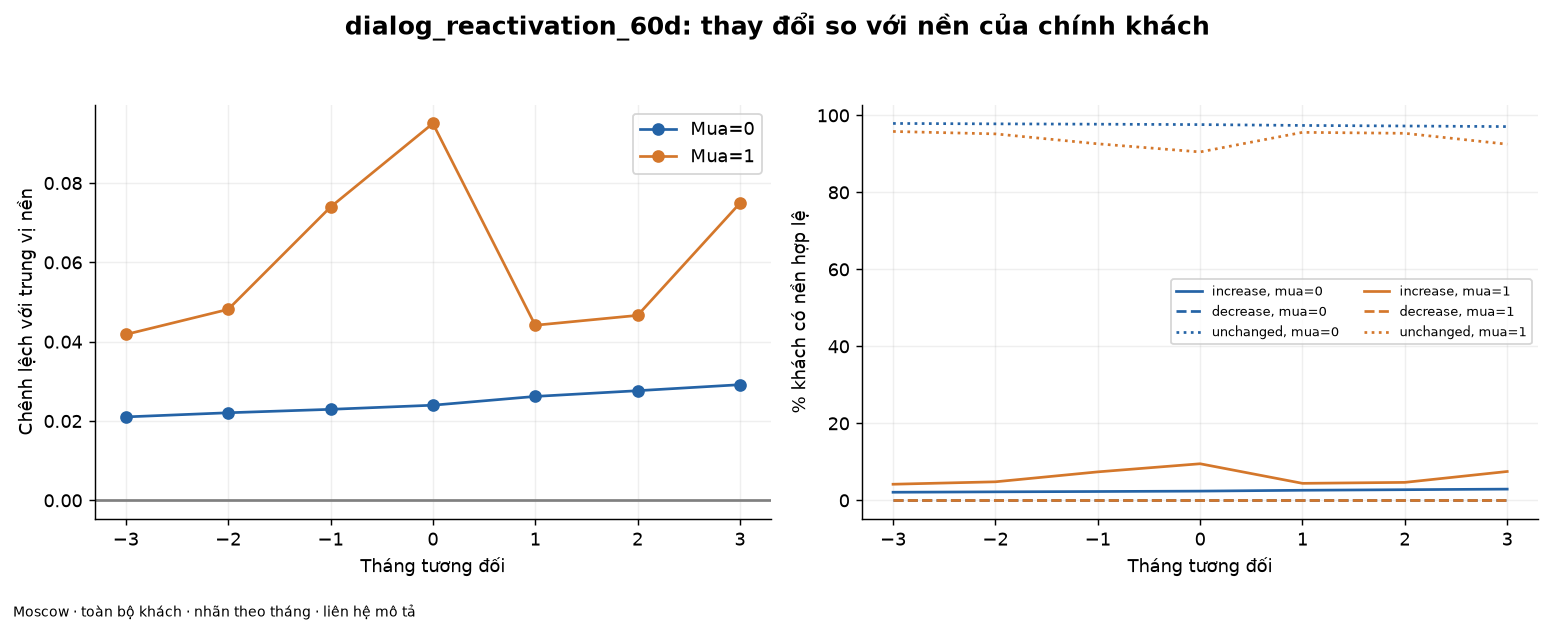

**outputs/eda_figures_moscow/baseline_dialog_reactivation_90d.png**

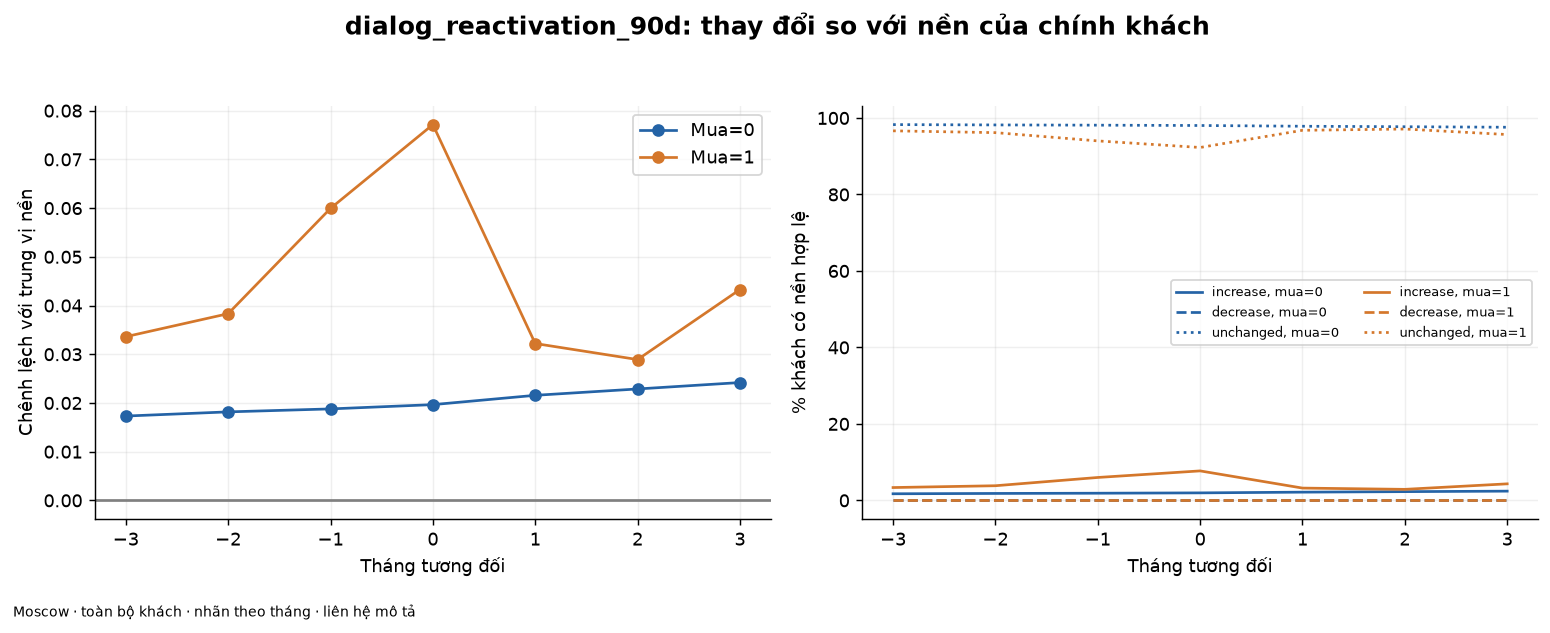

**outputs/eda_figures_moscow/baseline_geo_active_days.png**

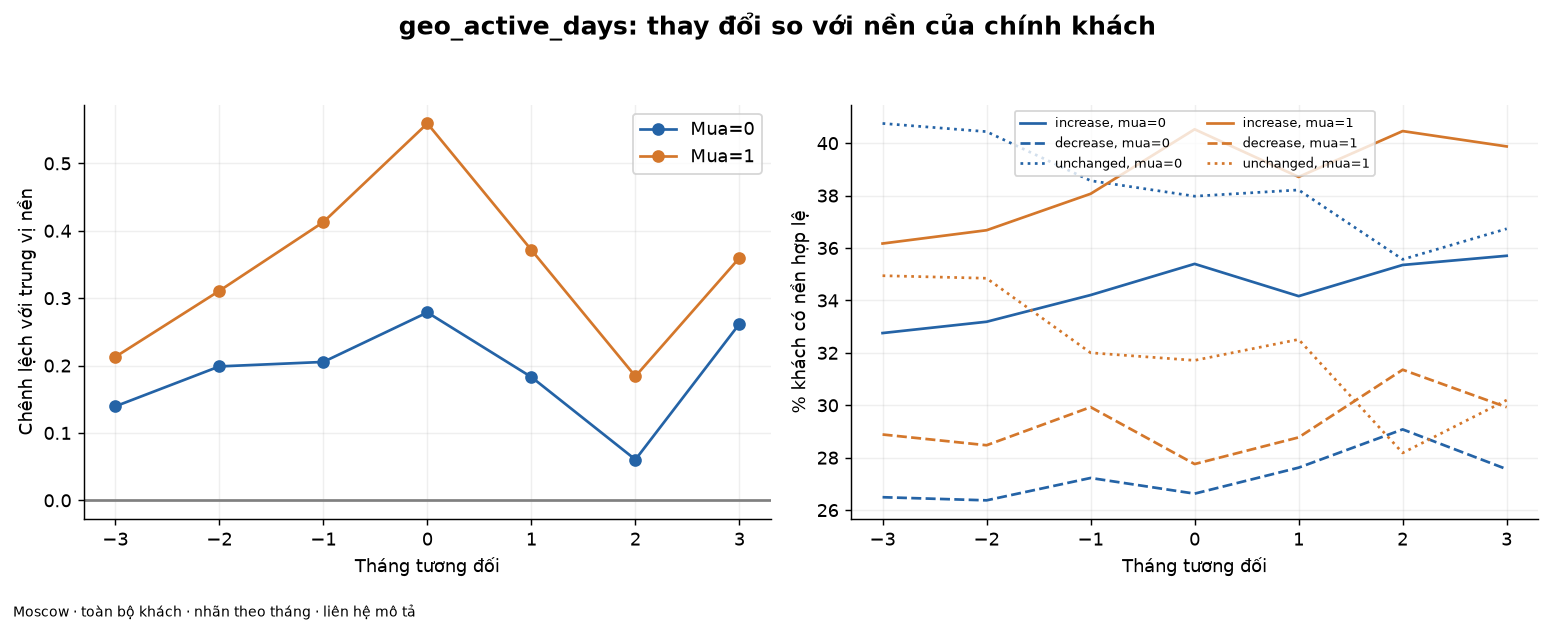

**outputs/eda_figures_moscow/baseline_geo_reactivation_30d.png**

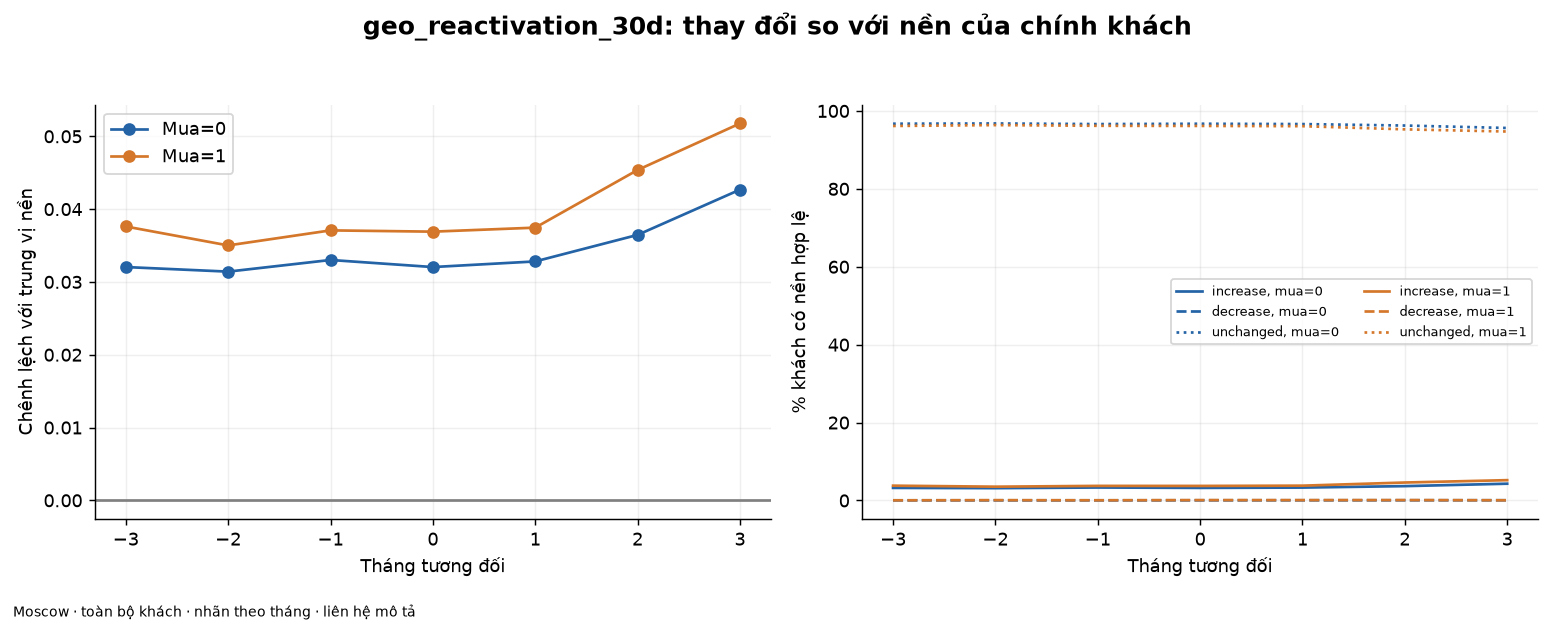

**outputs/eda_figures_moscow/baseline_geo_reactivation_60d.png**

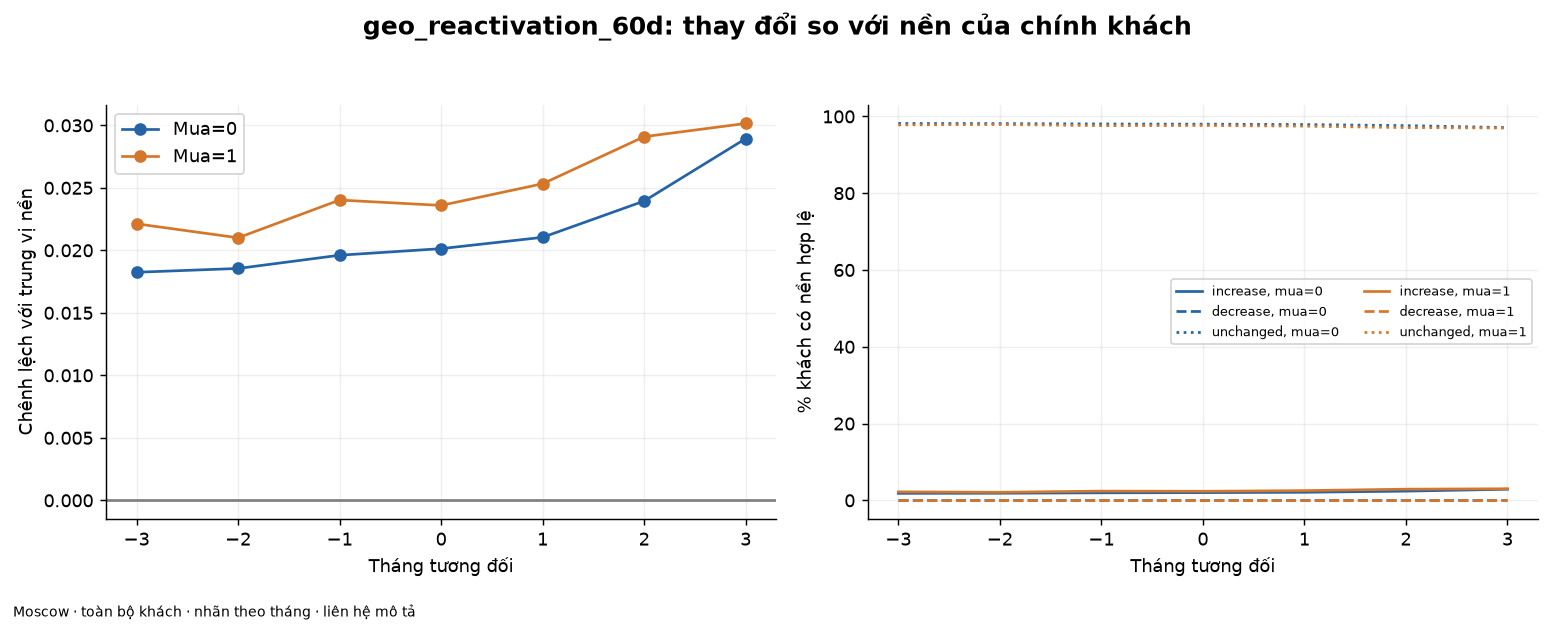

**outputs/eda_figures_moscow/baseline_geo_reactivation_90d.png**

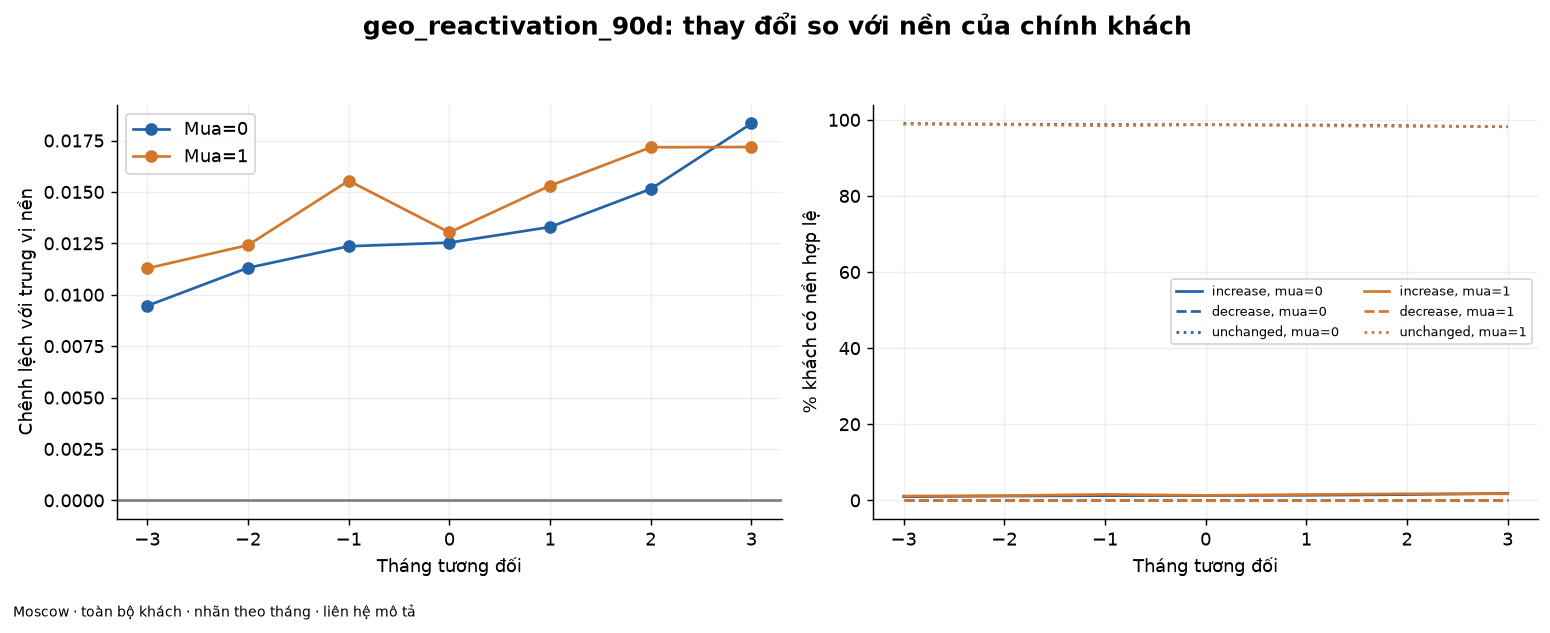

**outputs/eda_figures_moscow/baseline_trx_active_days.png**

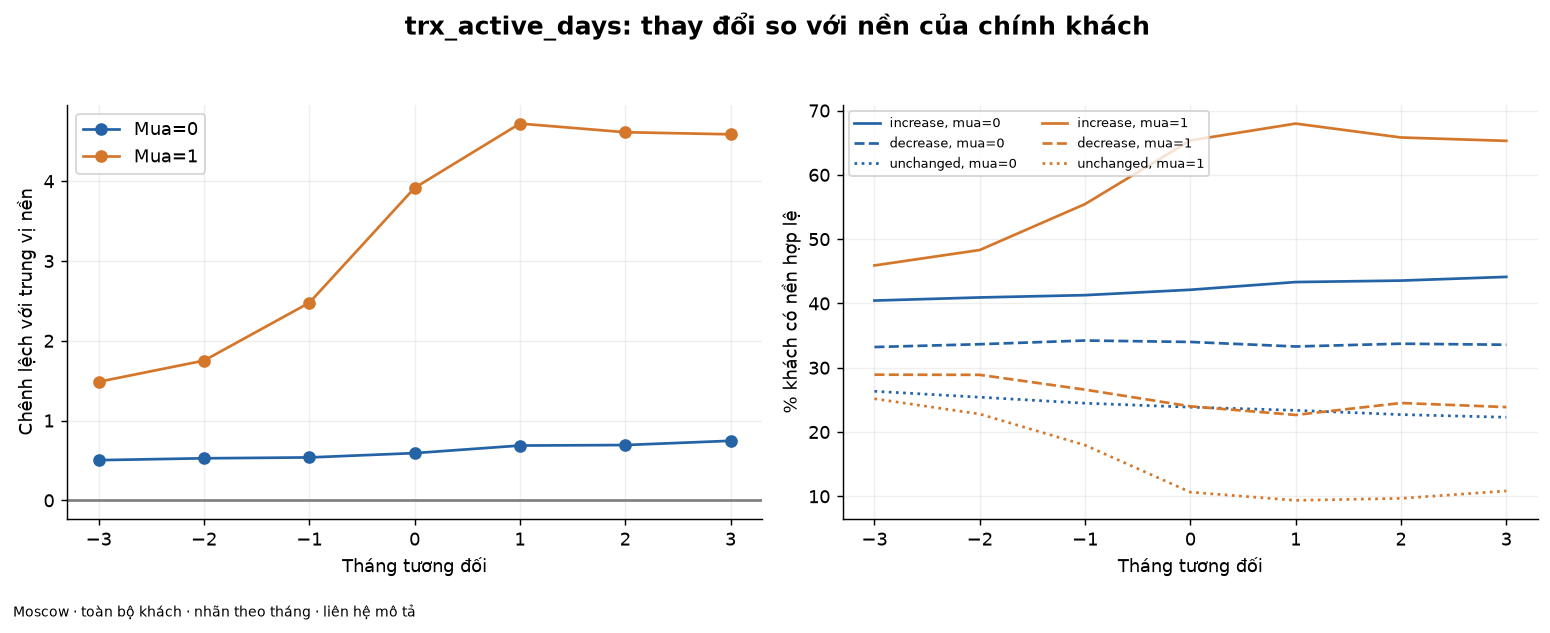

**outputs/eda_figures_moscow/baseline_trx_reactivation_30d.png**

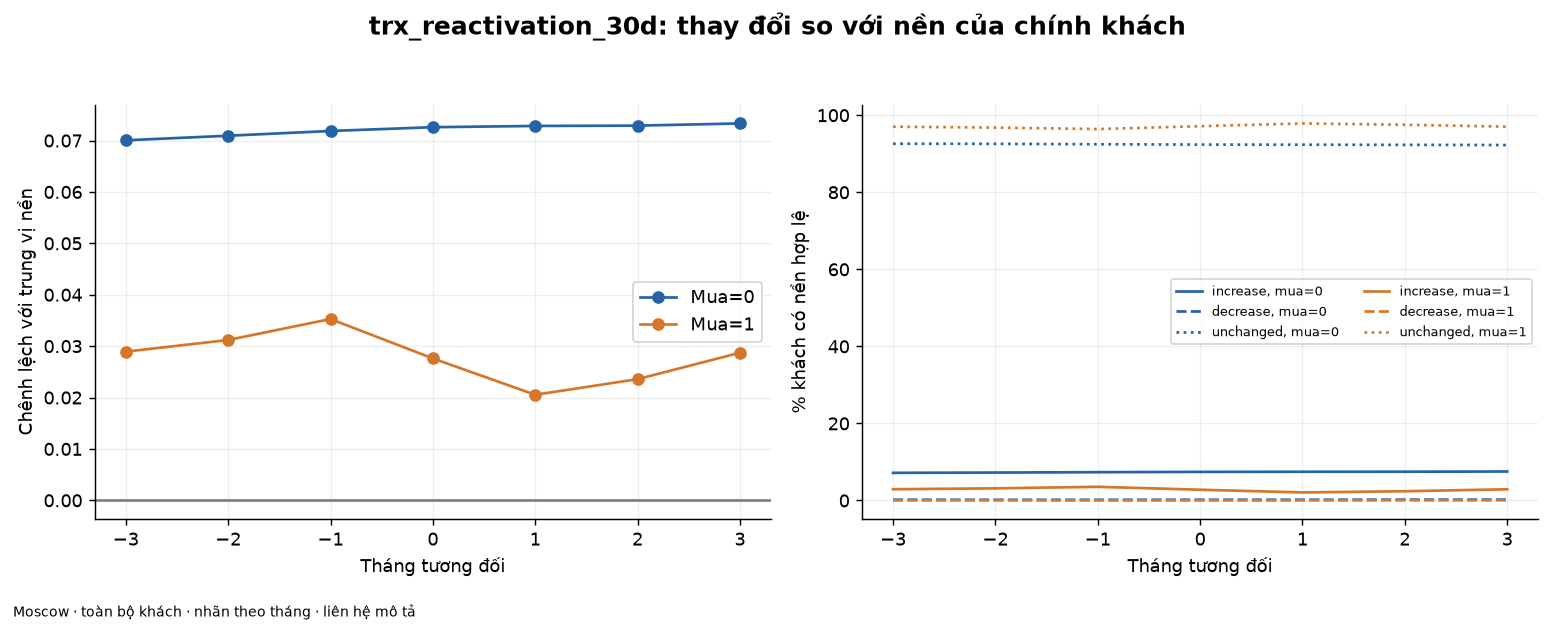

**outputs/eda_figures_moscow/baseline_trx_reactivation_60d.png**

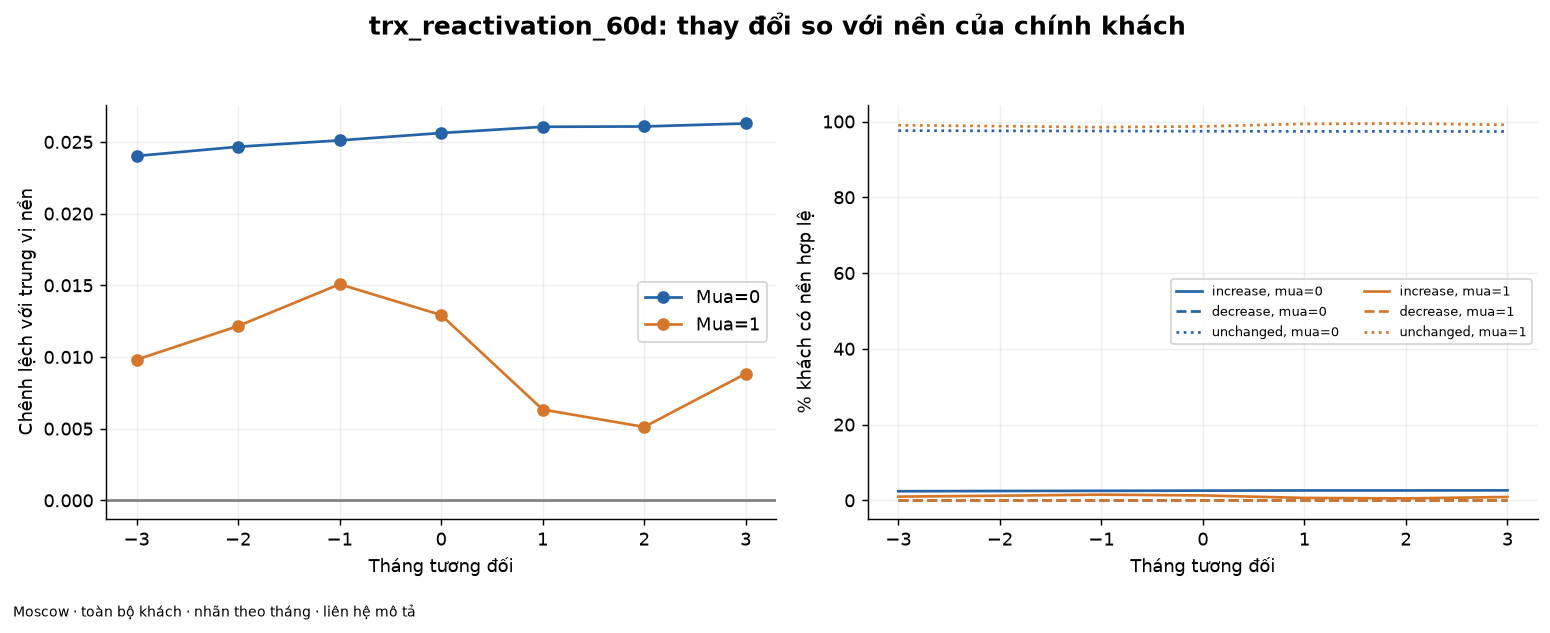

**outputs/eda_figures_moscow/baseline_trx_reactivation_90d.png**

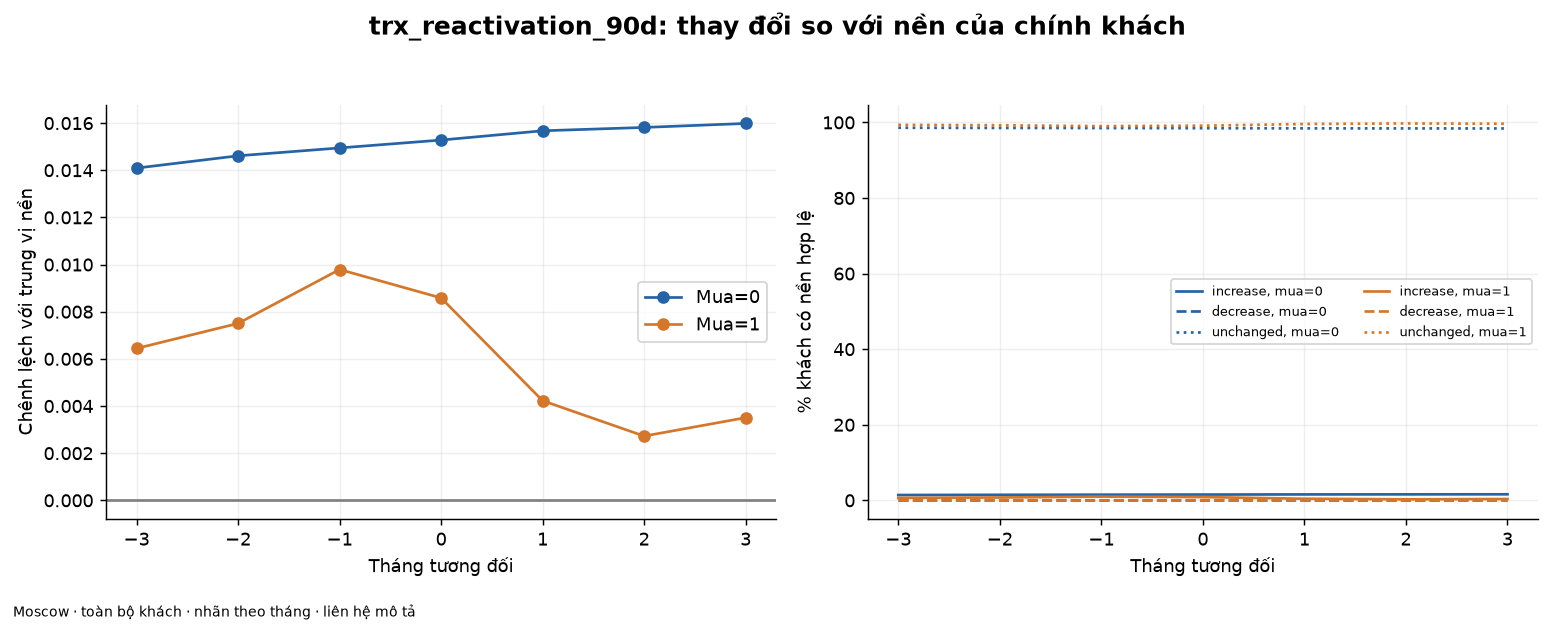

**outputs/eda_figures_moscow/cross_source_daily_synchrony.png**

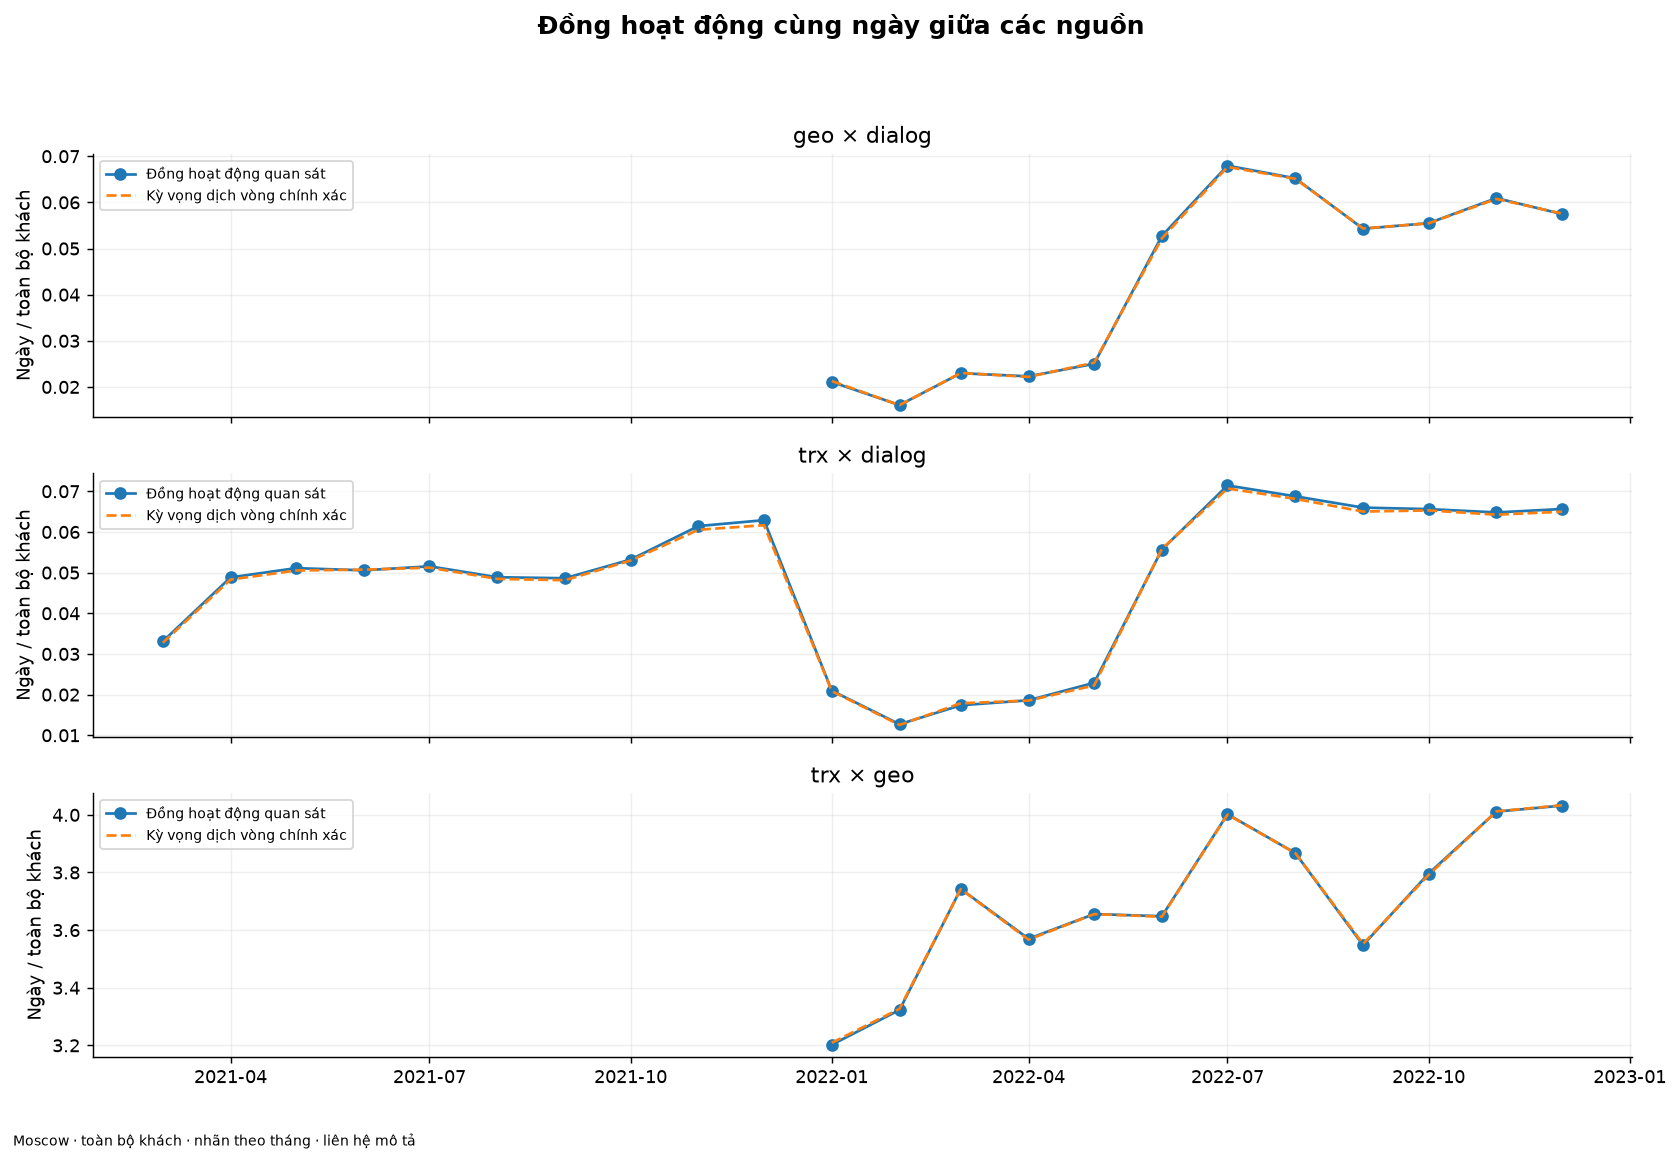

**outputs/eda_figures_moscow/event_dialog_active_days.png**

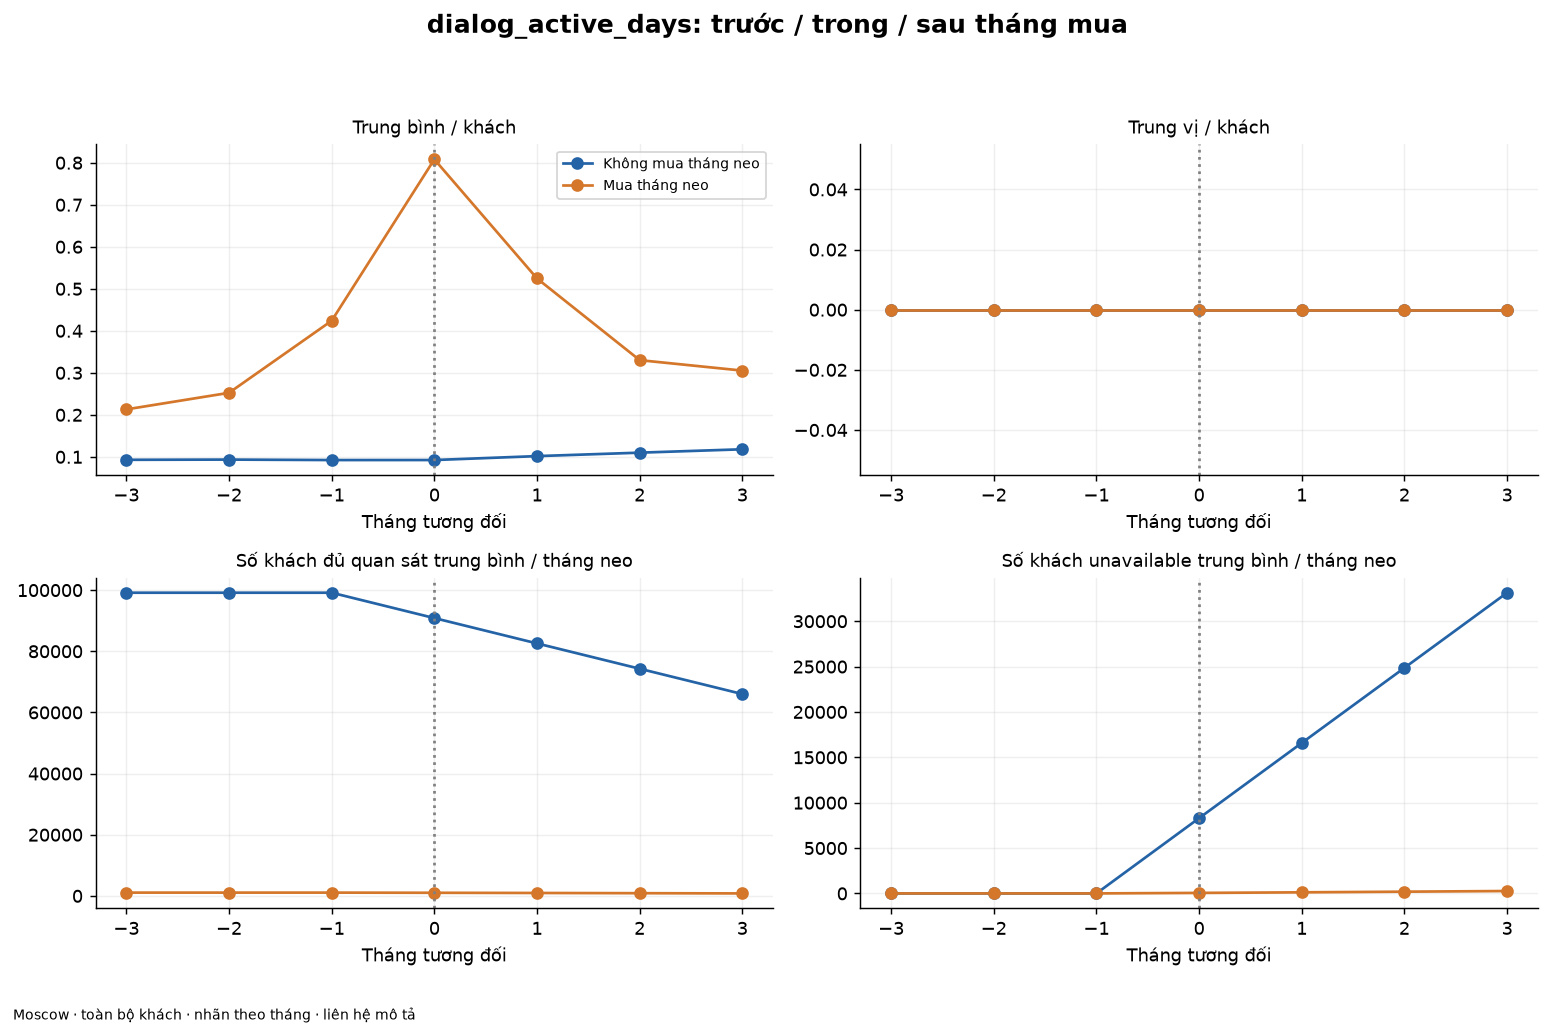

**outputs/eda_figures_moscow/event_dialog_active_days_by_anchor.png**

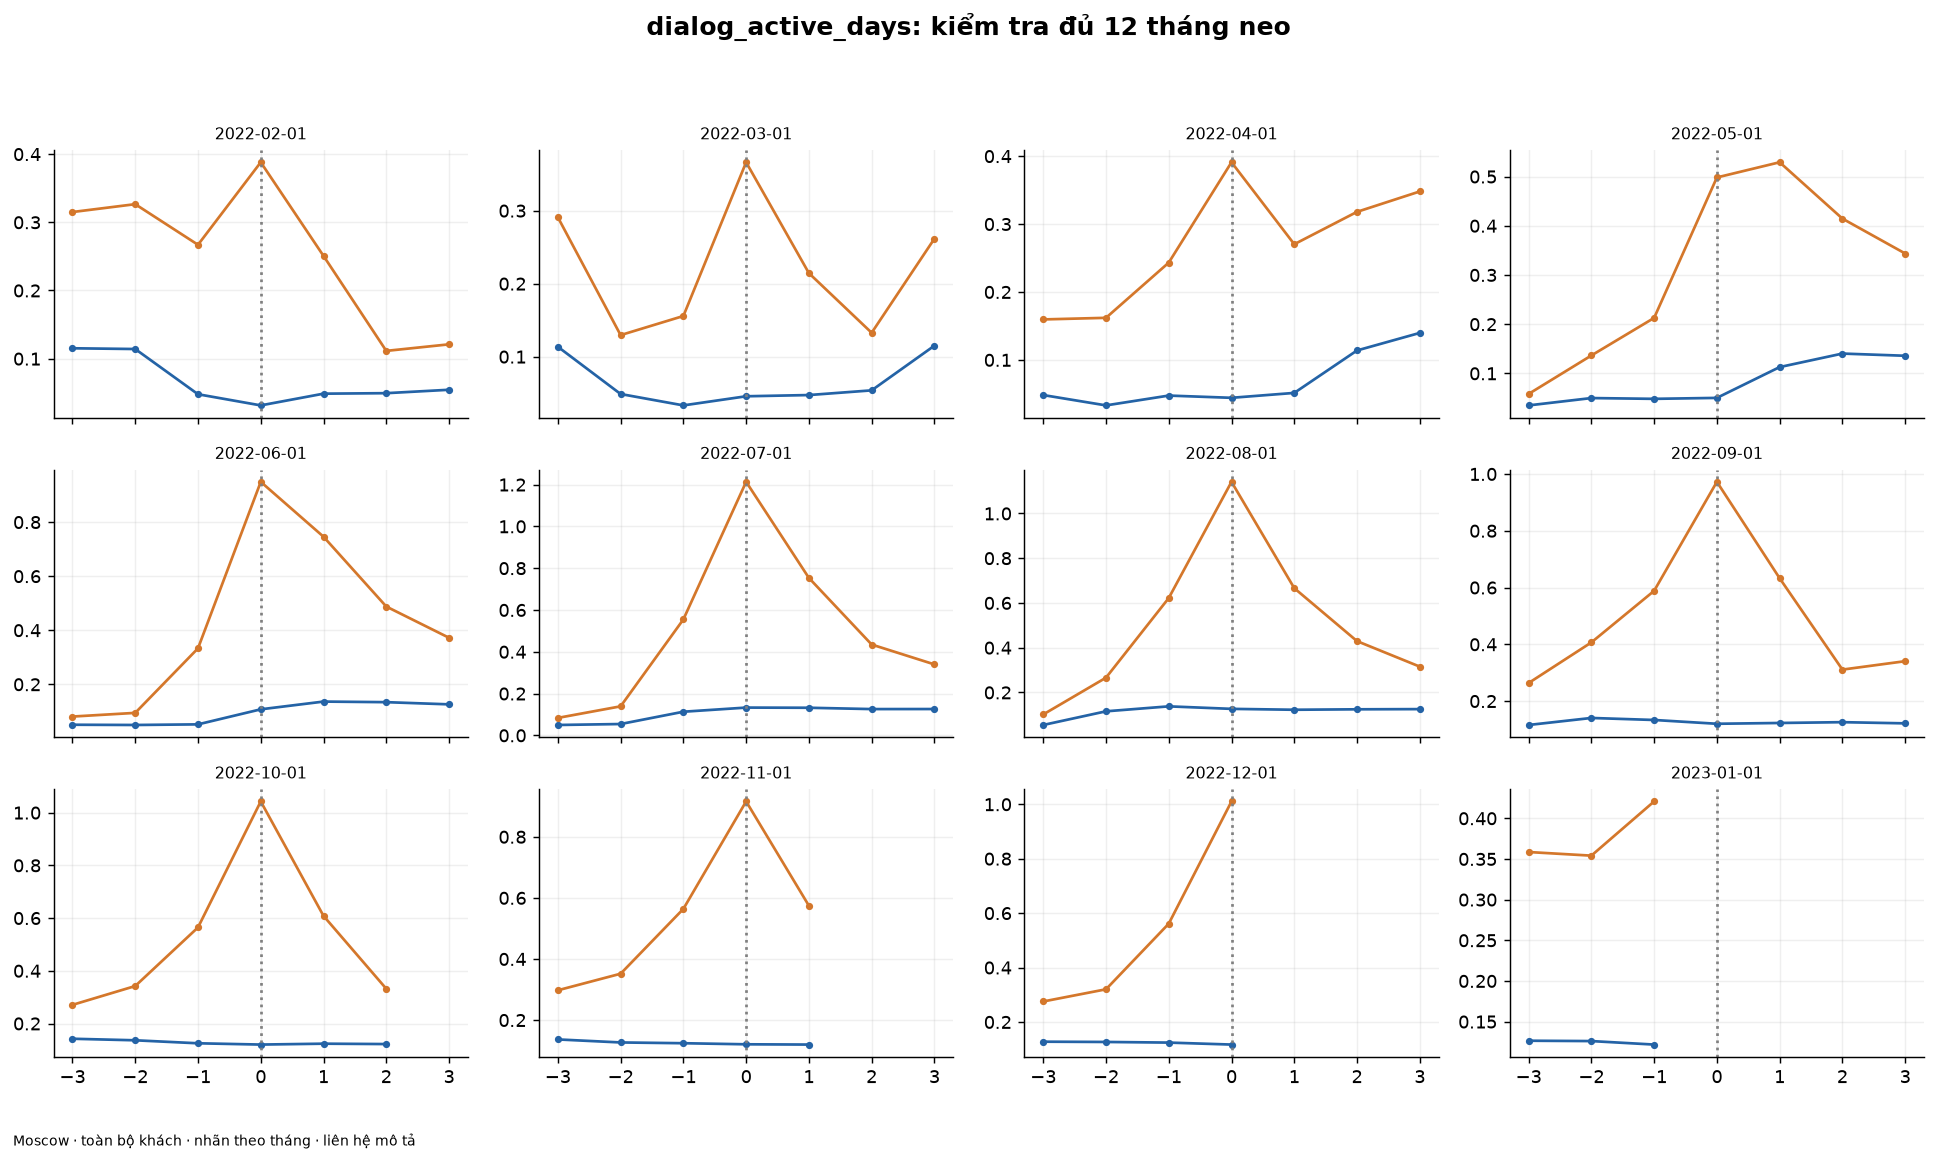

**outputs/eda_figures_moscow/event_dialog_reactivation_30d.png**

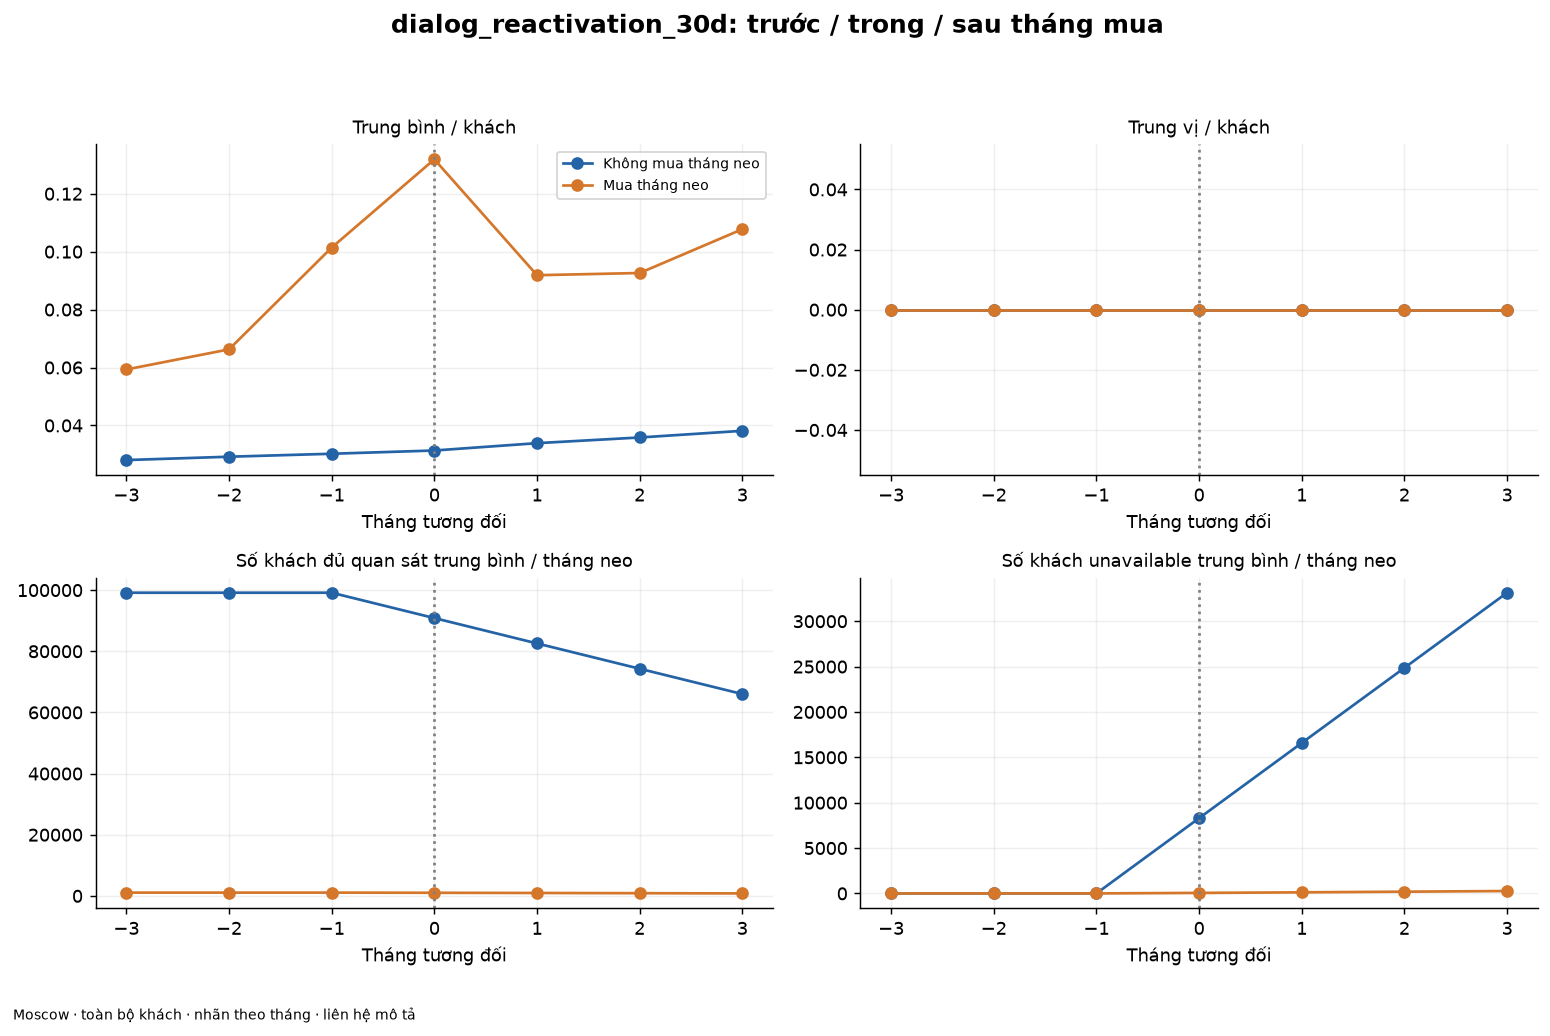

**outputs/eda_figures_moscow/event_dialog_reactivation_30d_by_anchor.png**

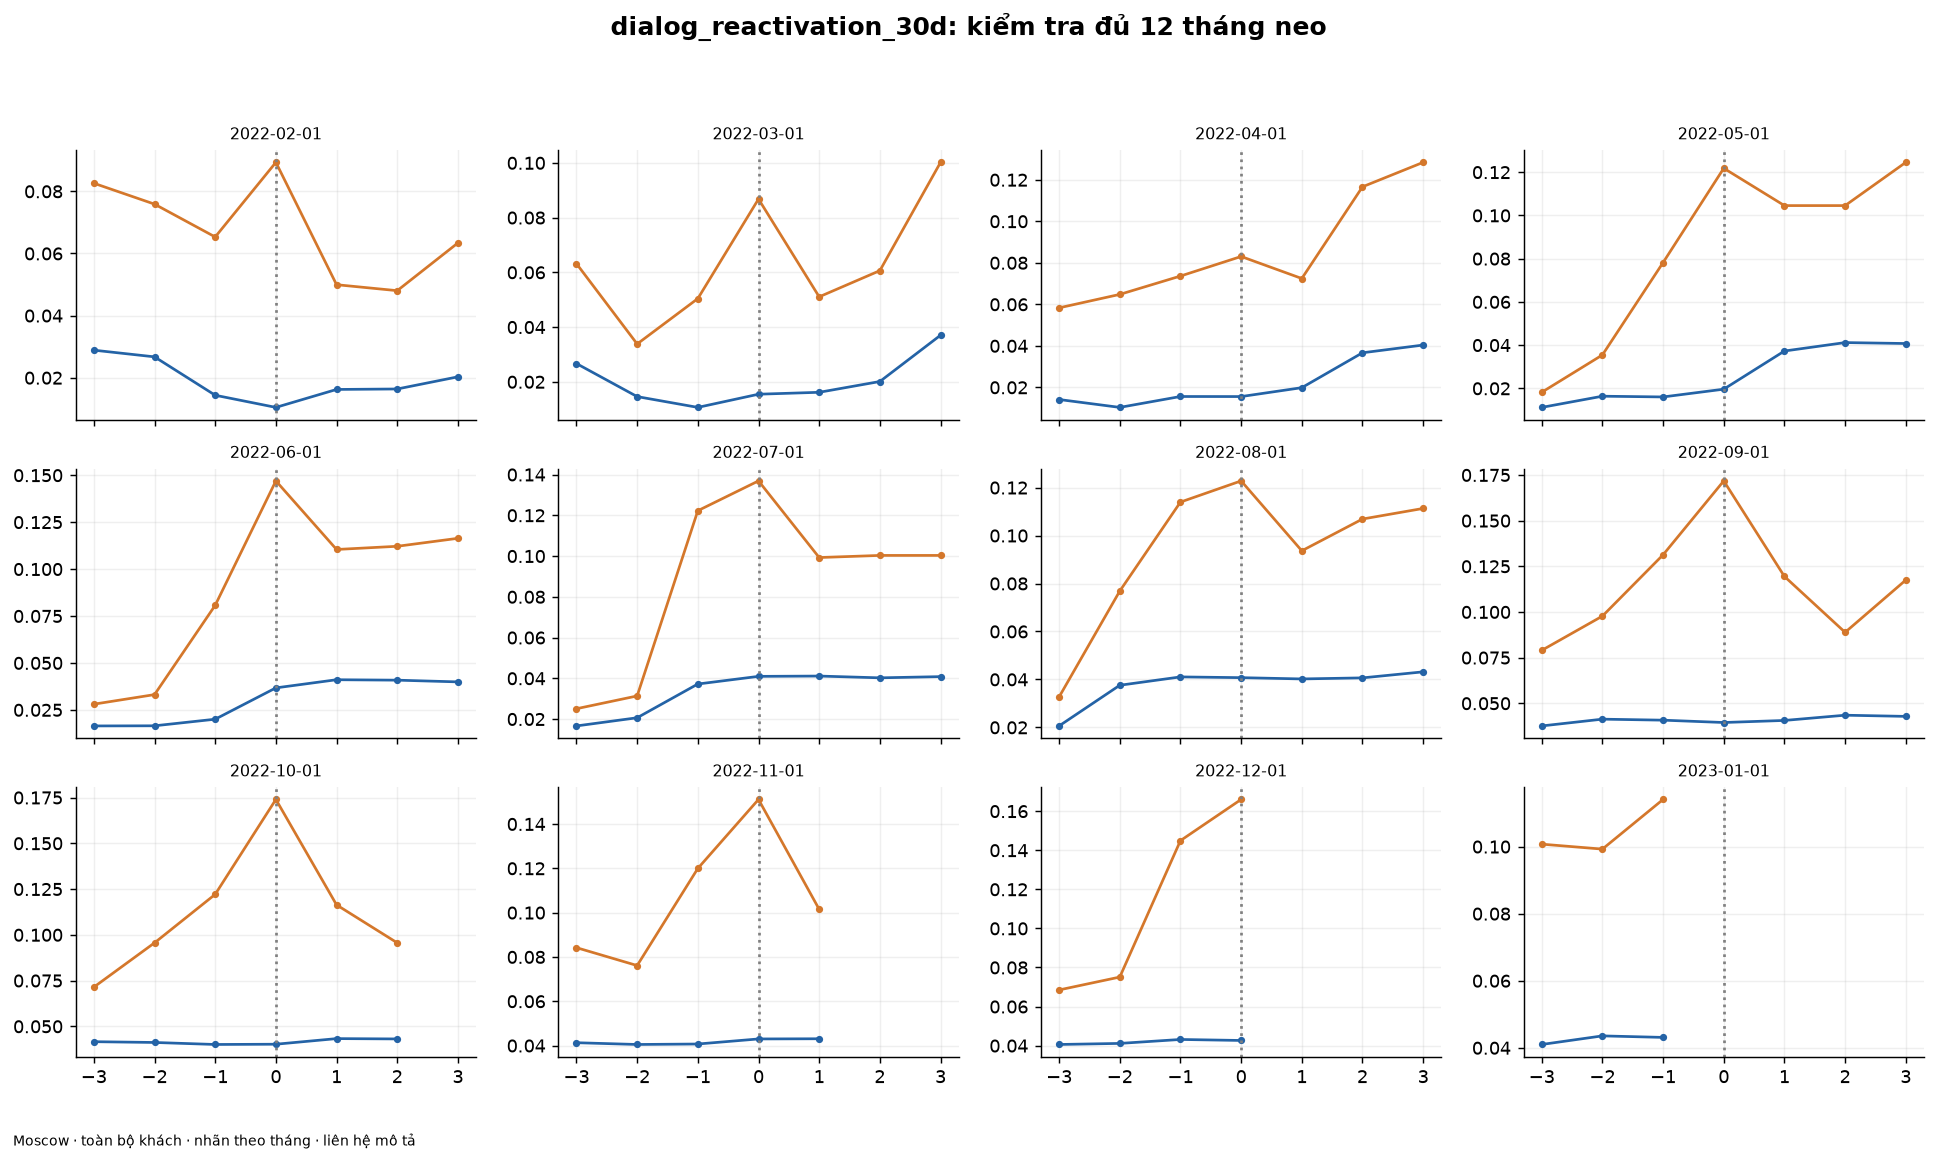

**outputs/eda_figures_moscow/event_dialog_reactivation_60d.png**

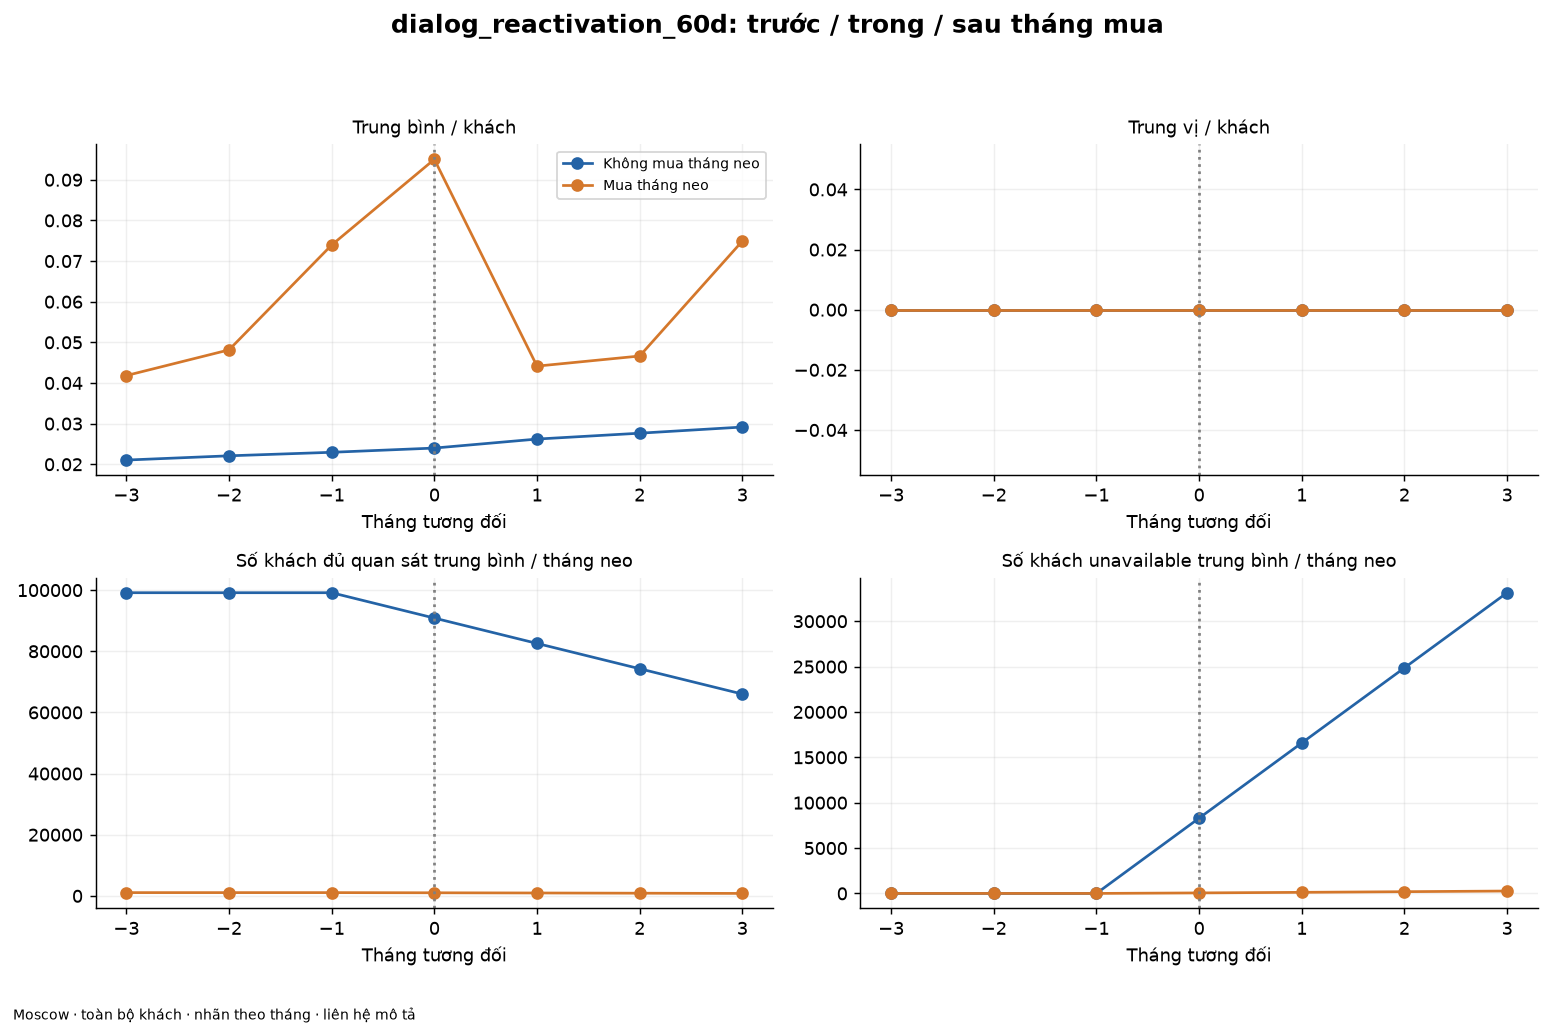

**outputs/eda_figures_moscow/event_dialog_reactivation_60d_by_anchor.png**

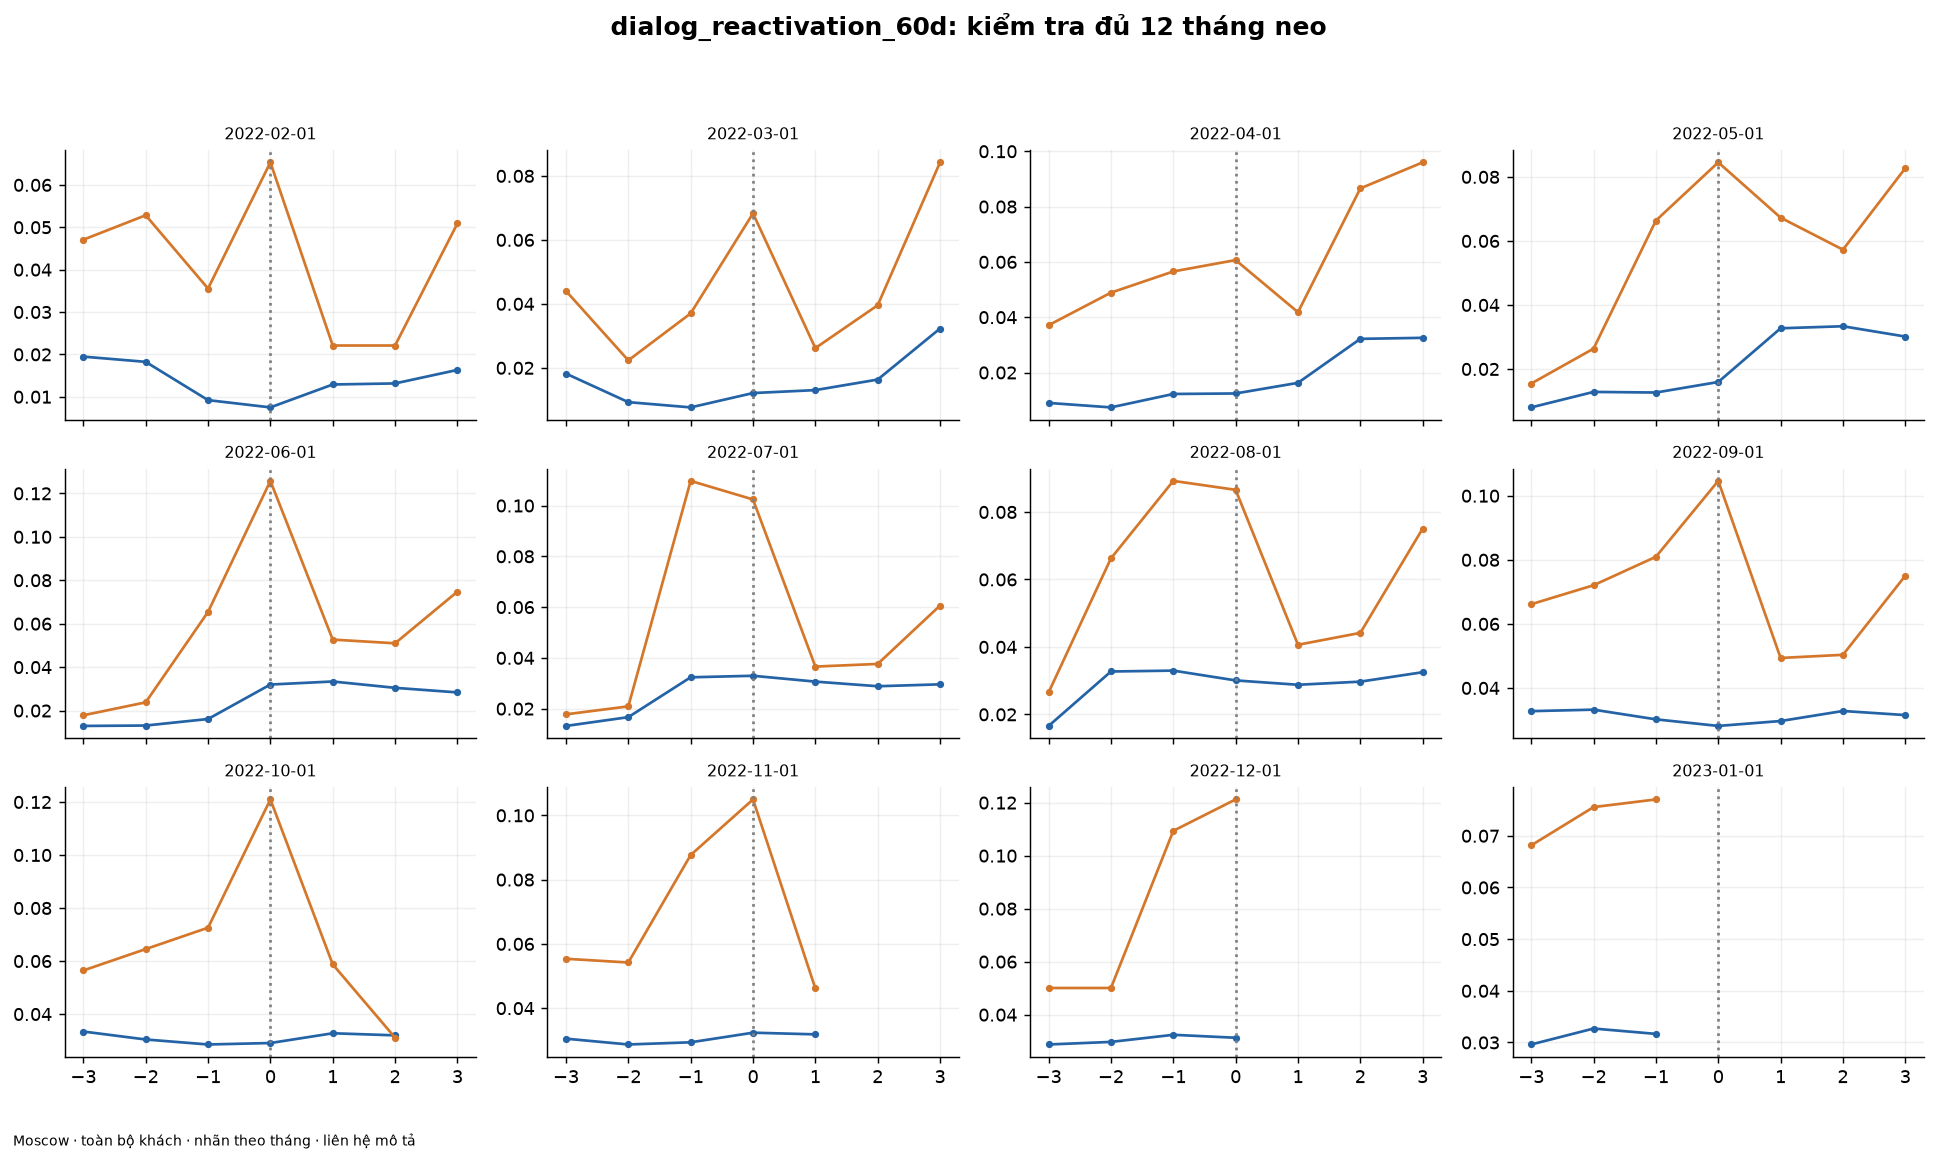

**outputs/eda_figures_moscow/event_dialog_reactivation_90d.png**

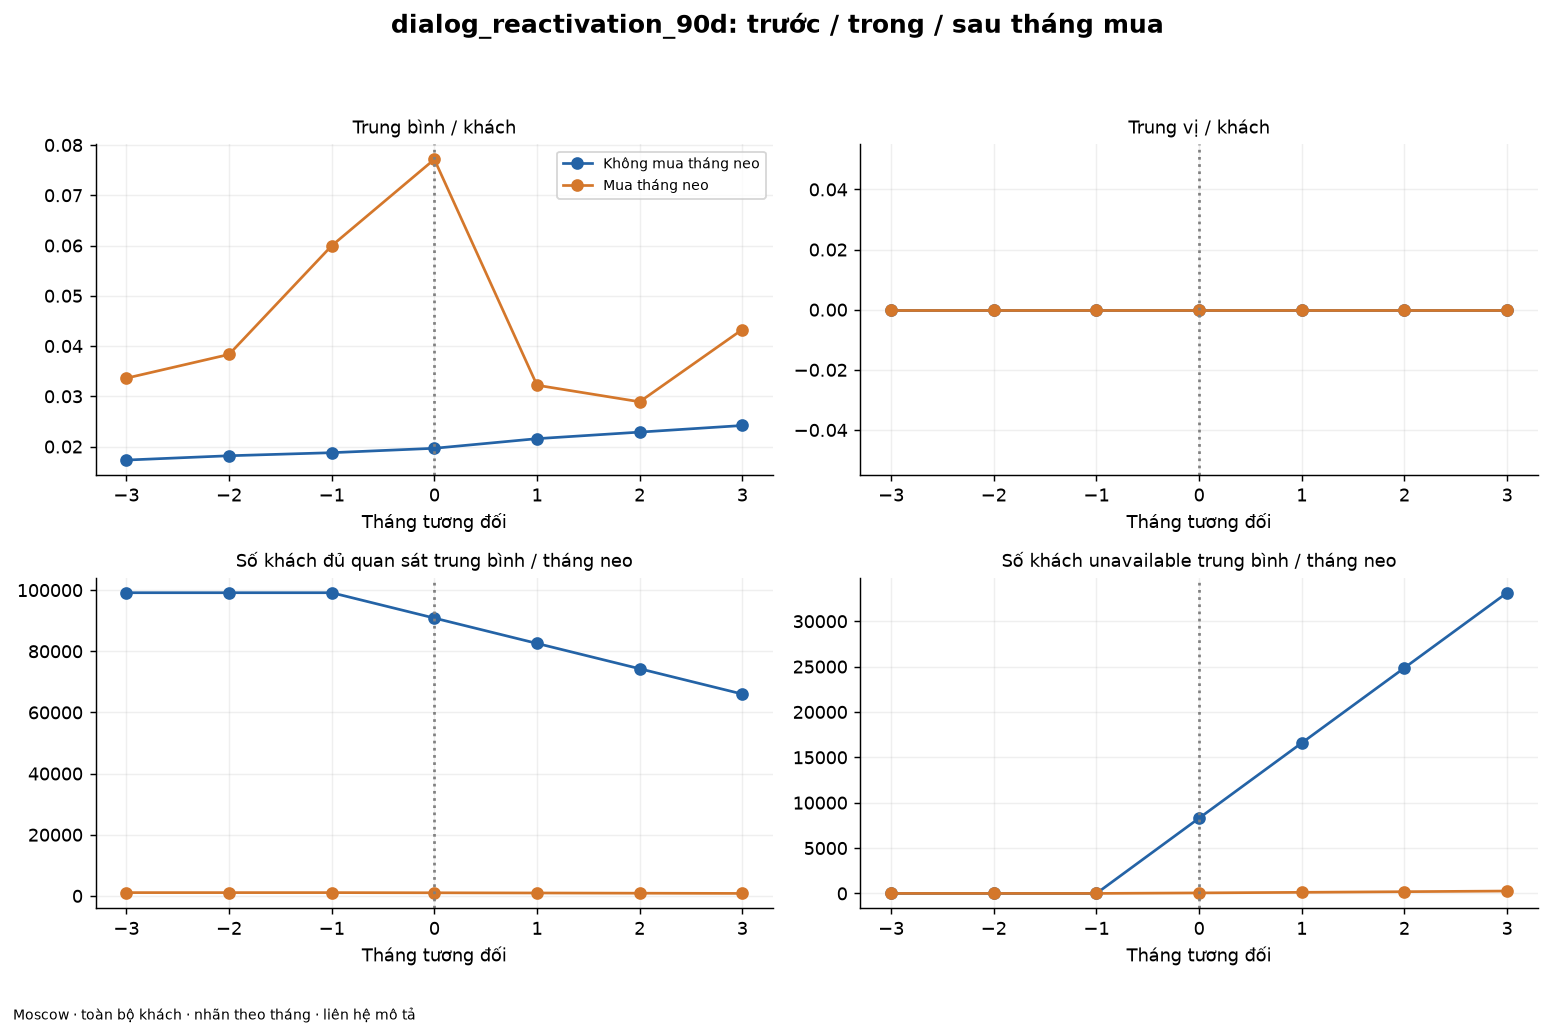

**outputs/eda_figures_moscow/event_dialog_reactivation_90d_by_anchor.png**

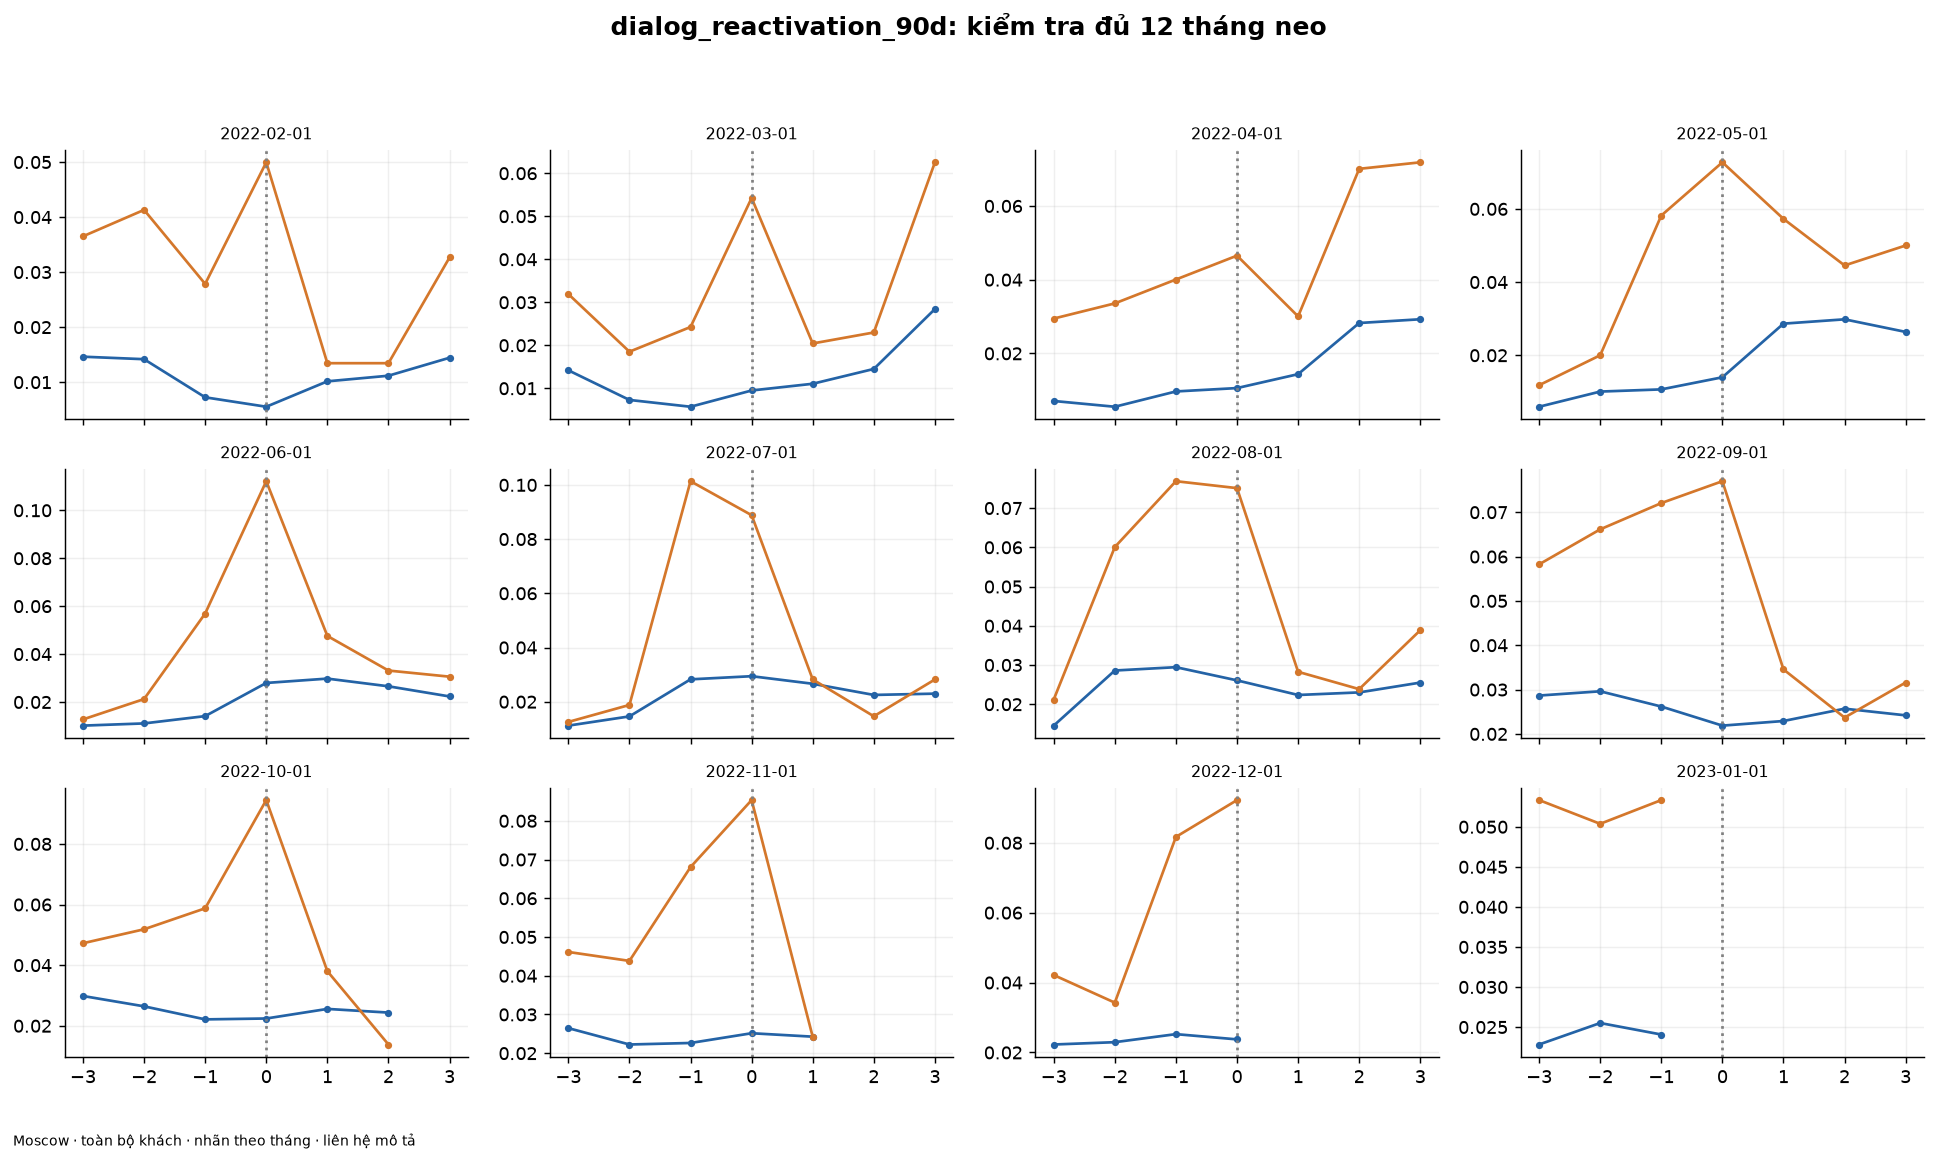

**outputs/eda_figures_moscow/event_geo_active_days.png**

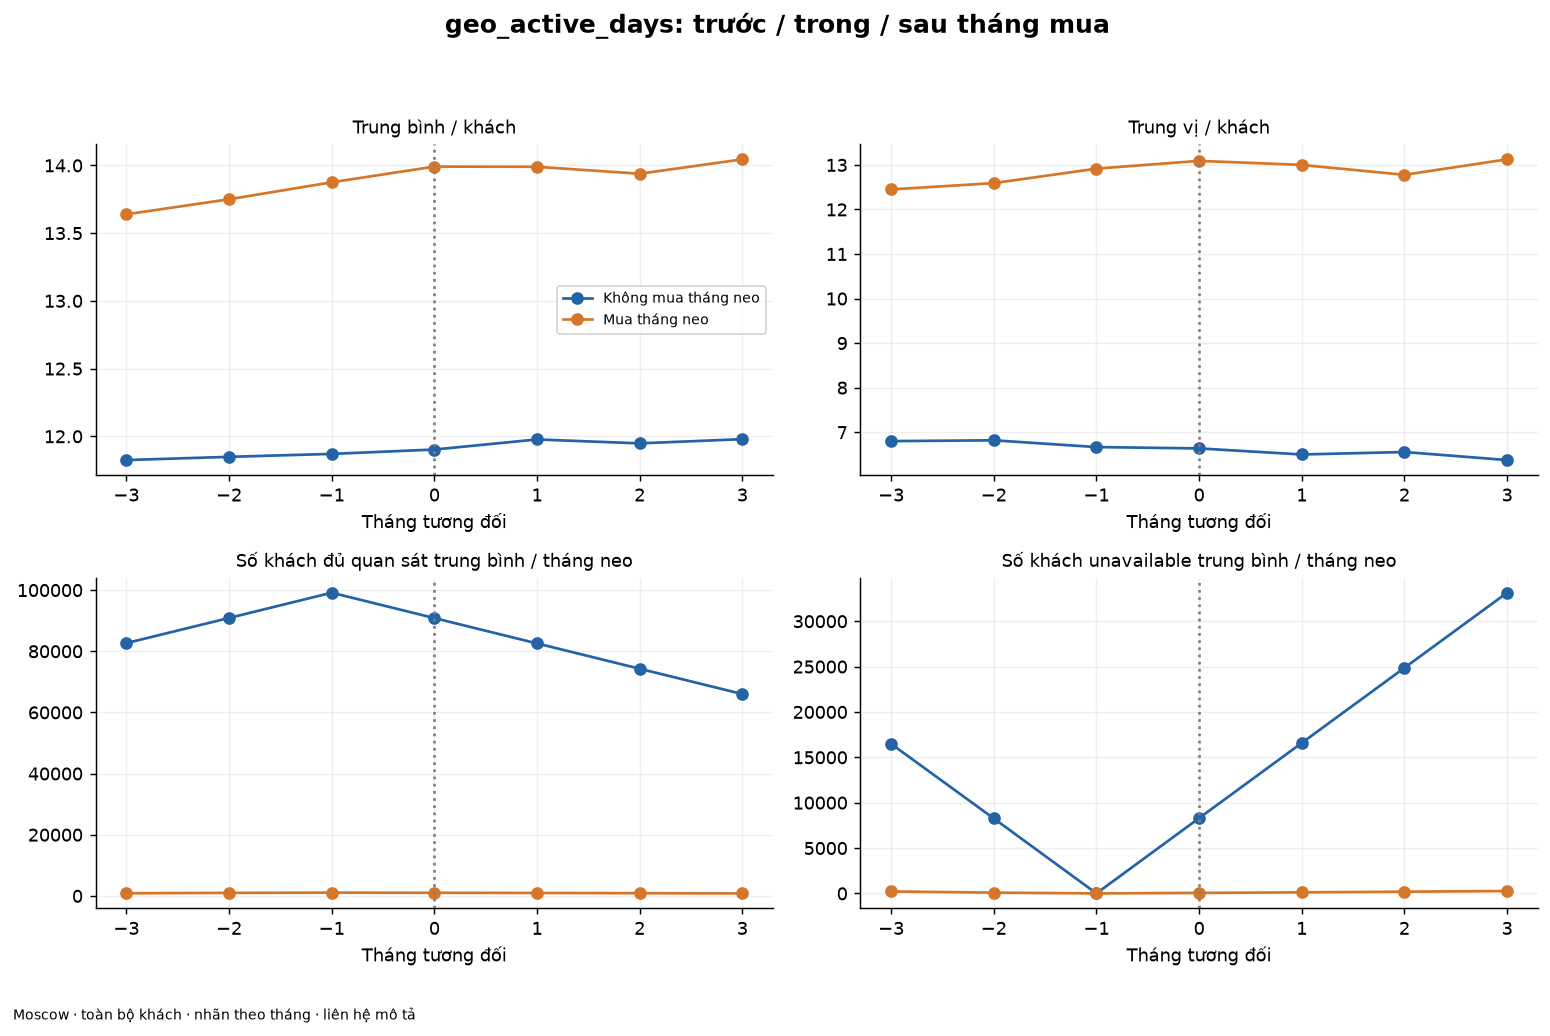

**outputs/eda_figures_moscow/event_geo_active_days_by_anchor.png**

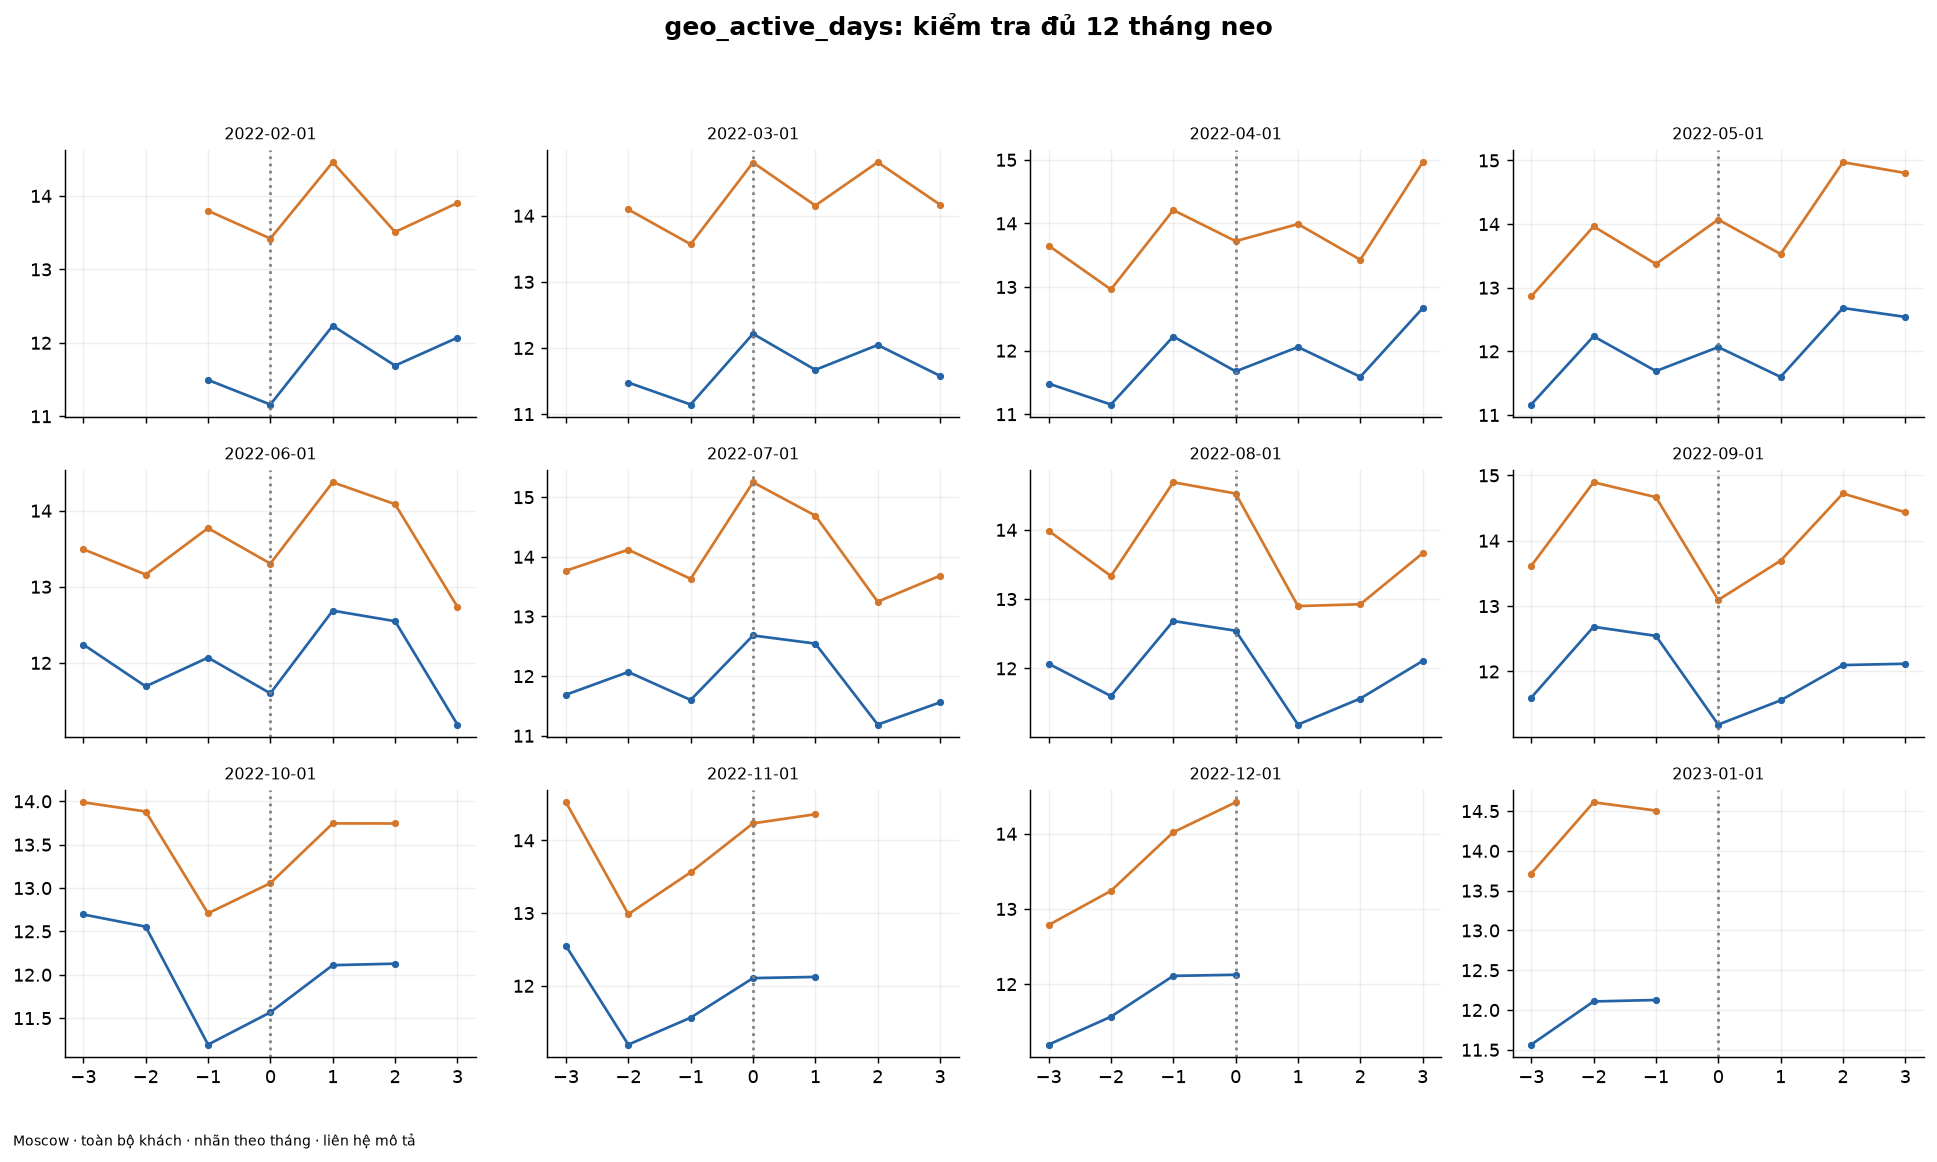

**outputs/eda_figures_moscow/event_geo_reactivation_30d.png**

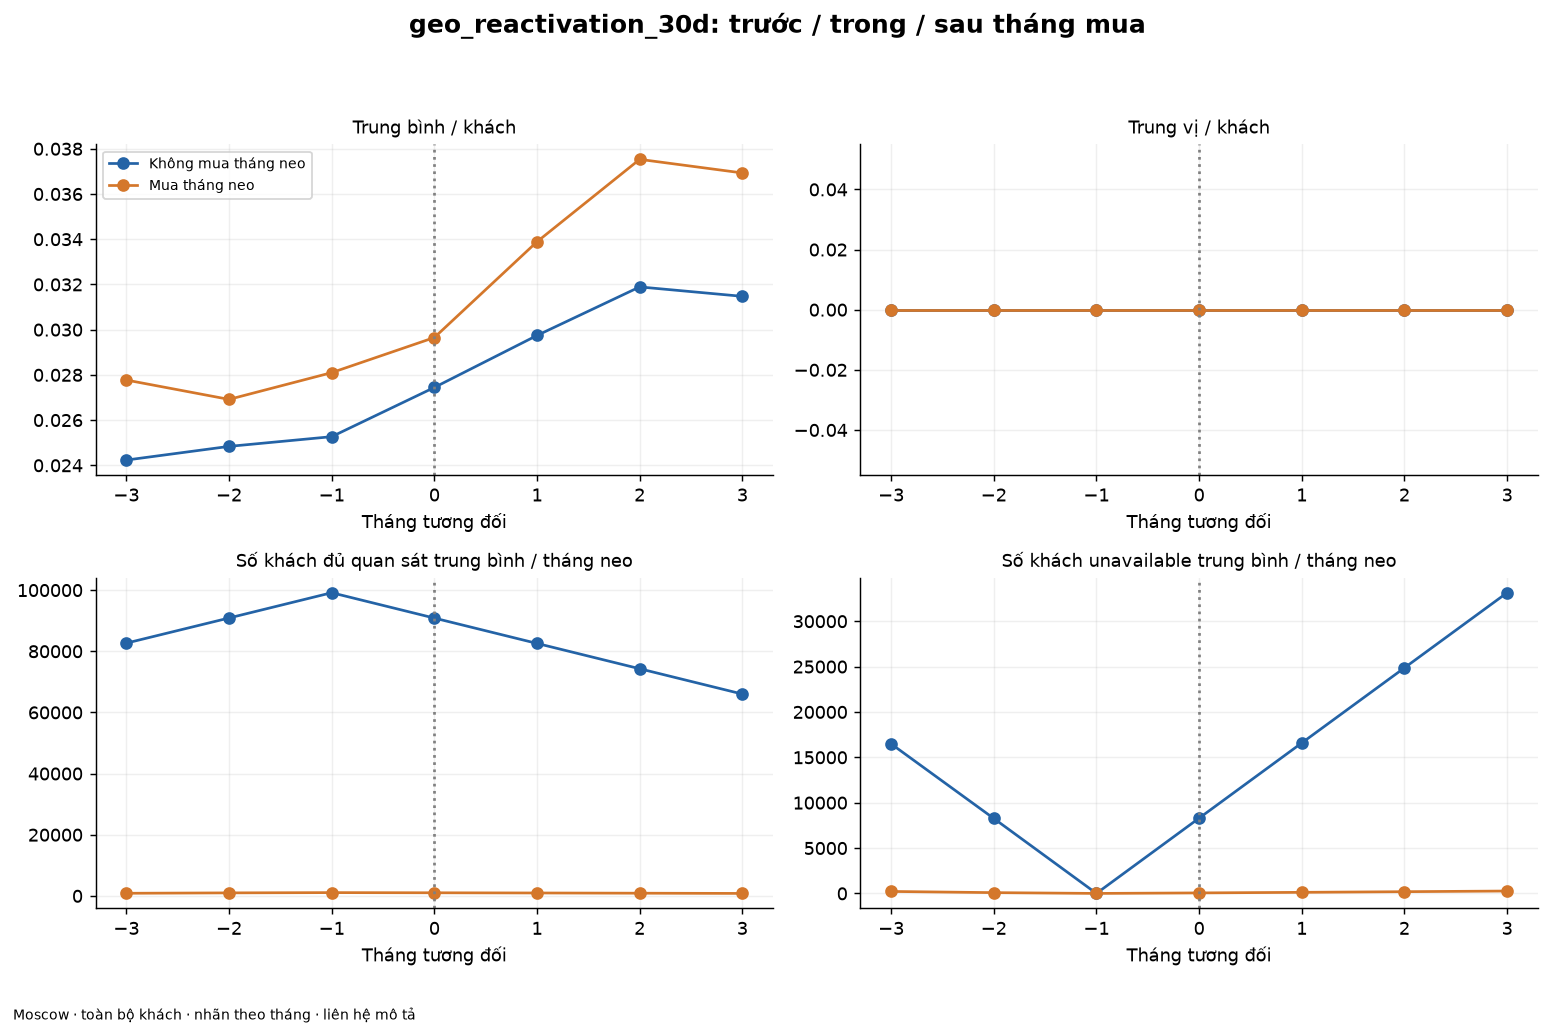

**outputs/eda_figures_moscow/event_geo_reactivation_30d_by_anchor.png**

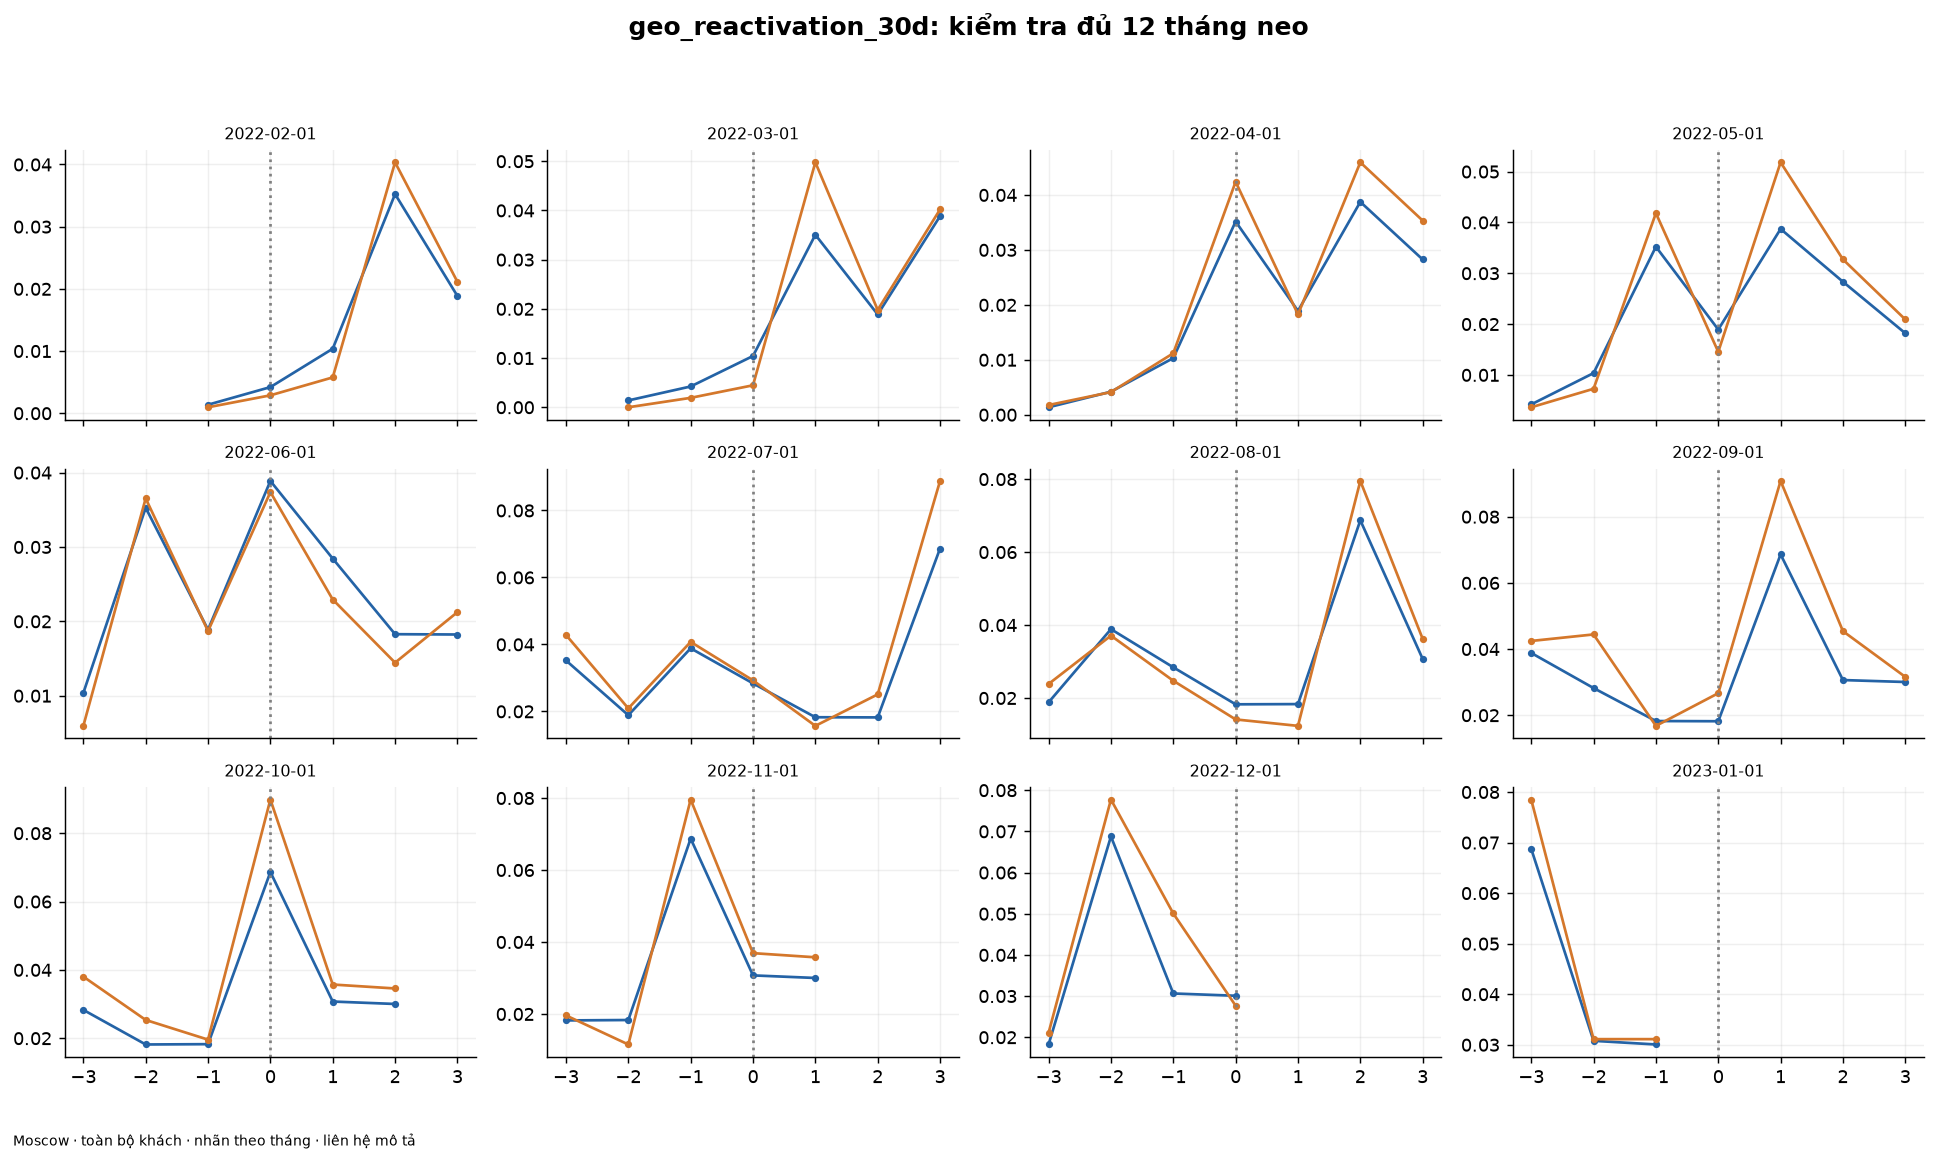

**outputs/eda_figures_moscow/event_geo_reactivation_60d.png**

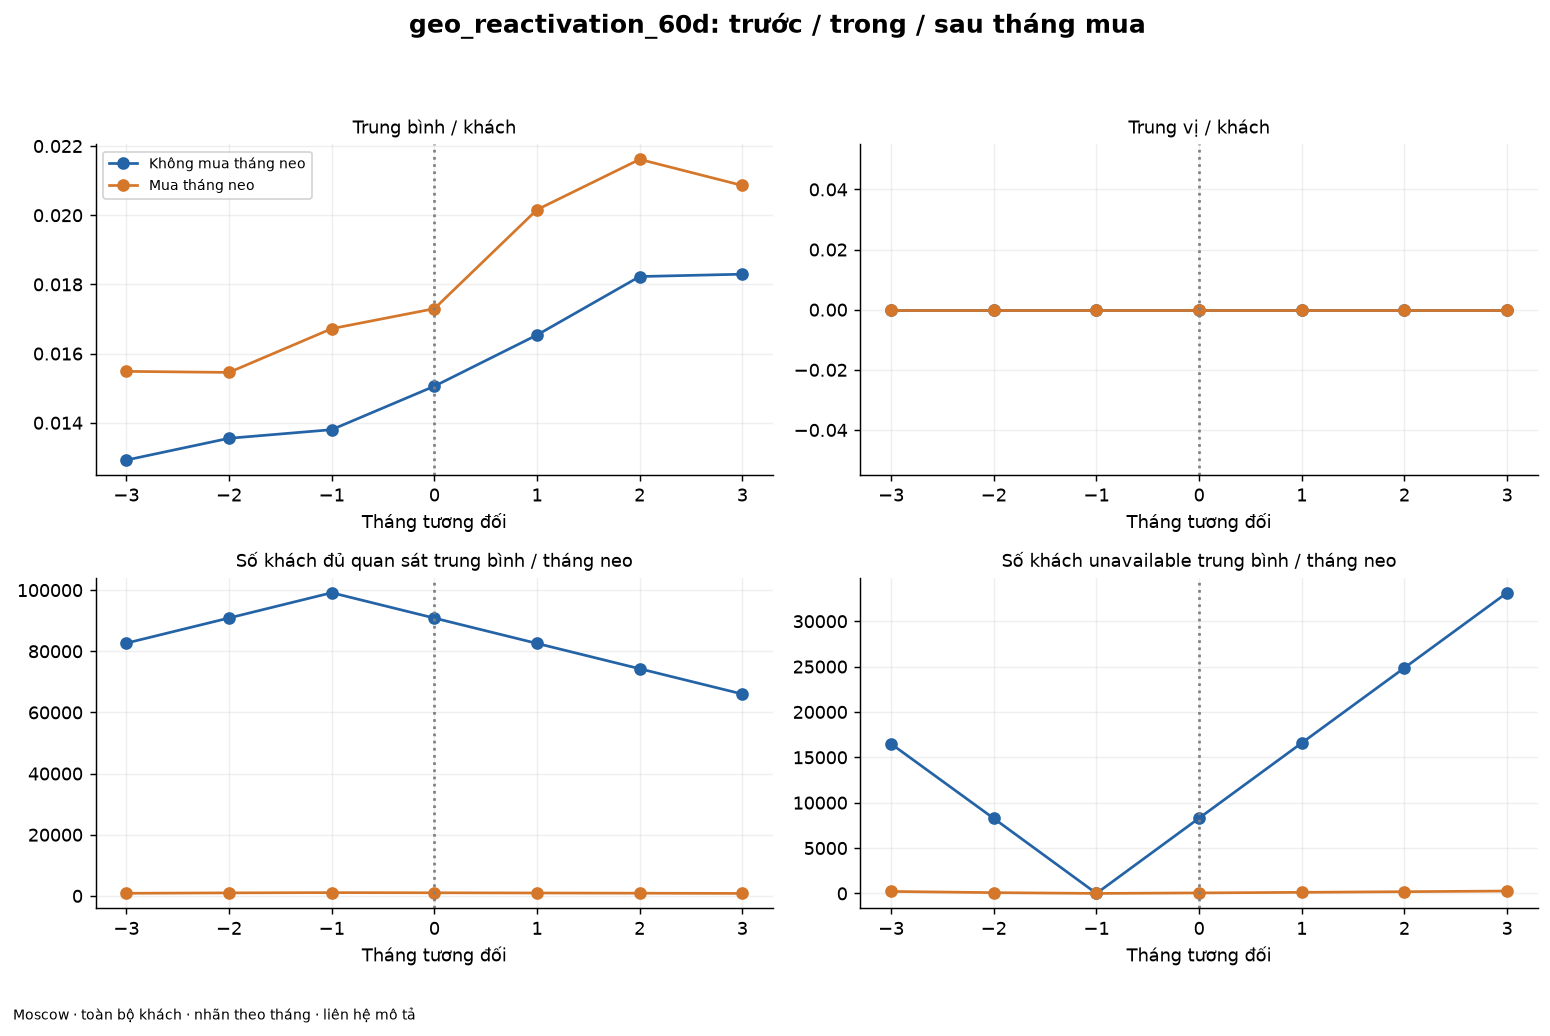

**outputs/eda_figures_moscow/event_geo_reactivation_60d_by_anchor.png**

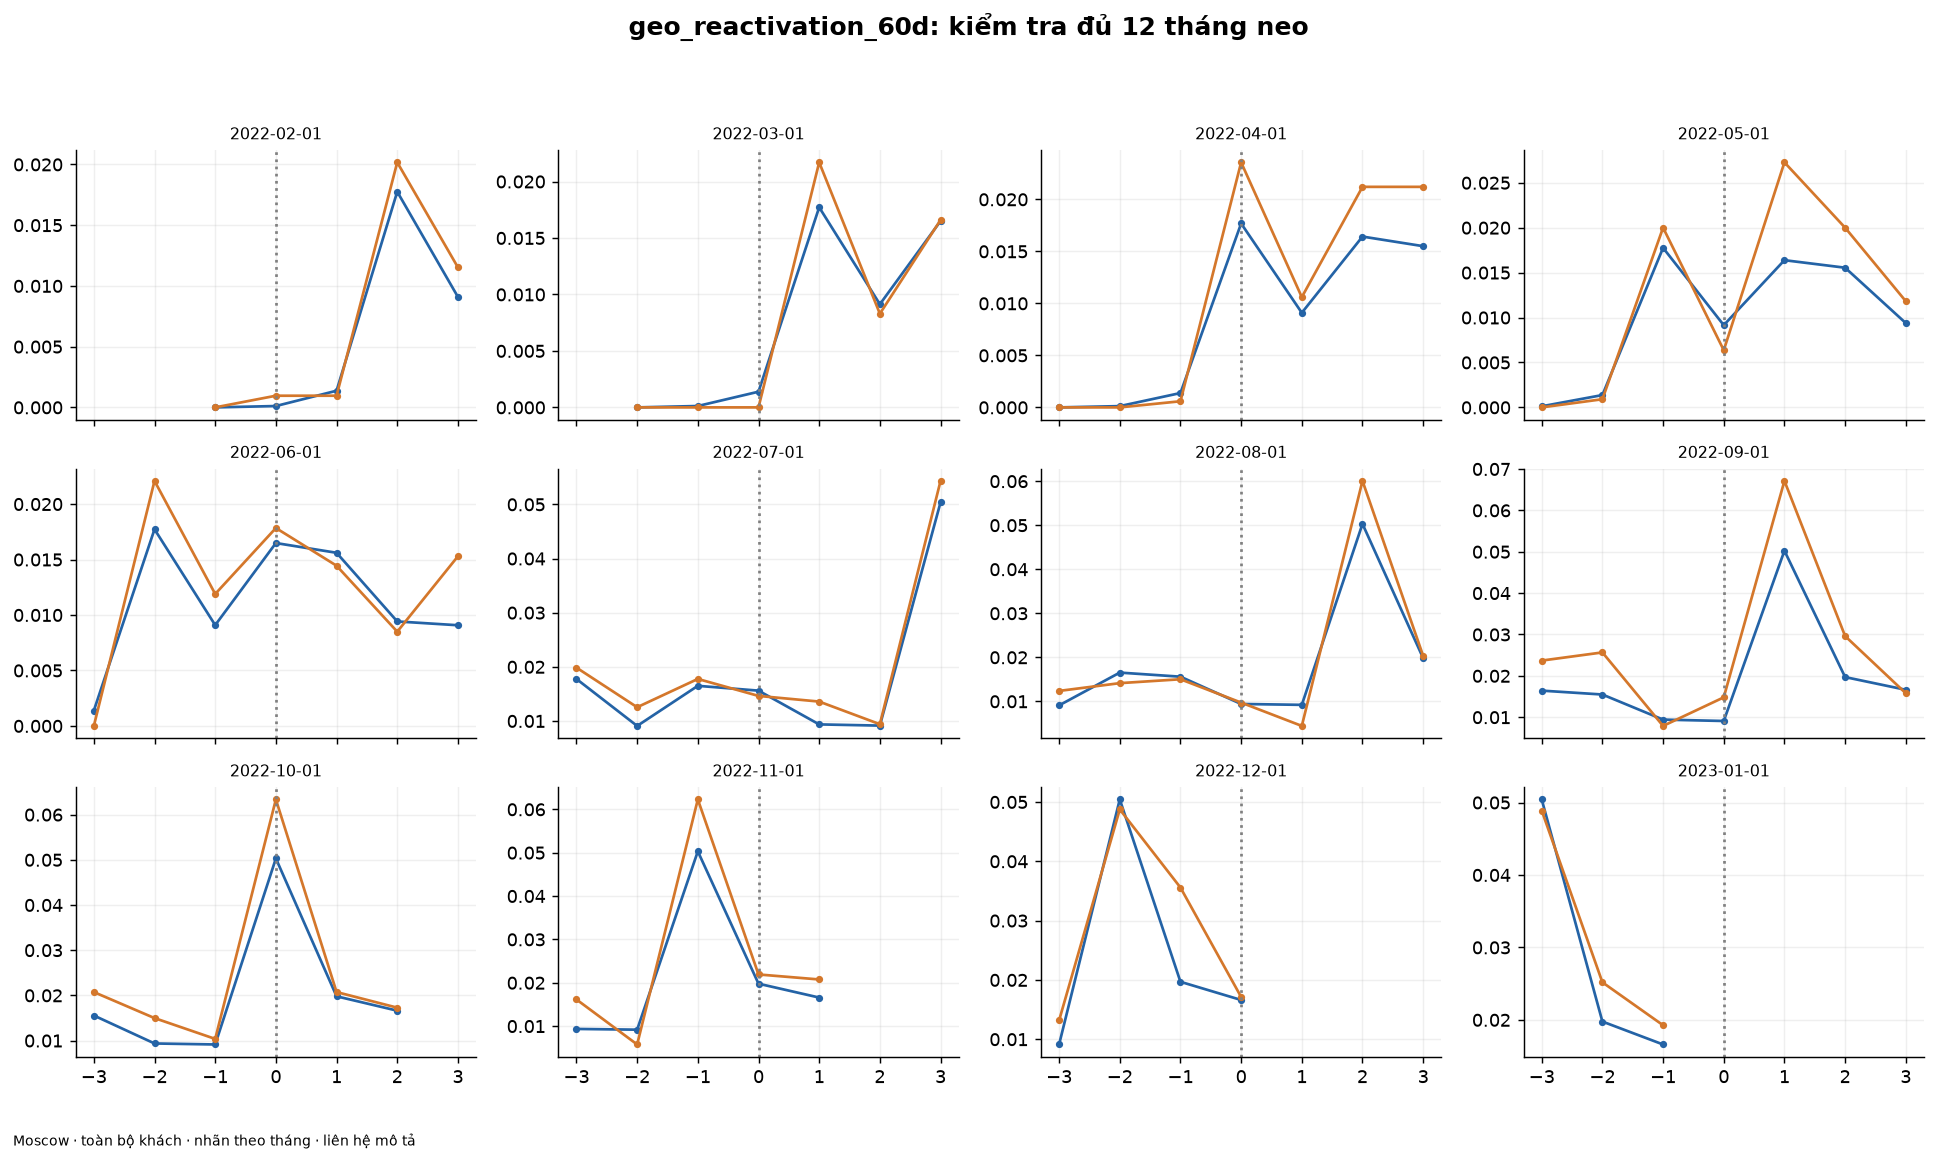

**outputs/eda_figures_moscow/event_geo_reactivation_90d.png**

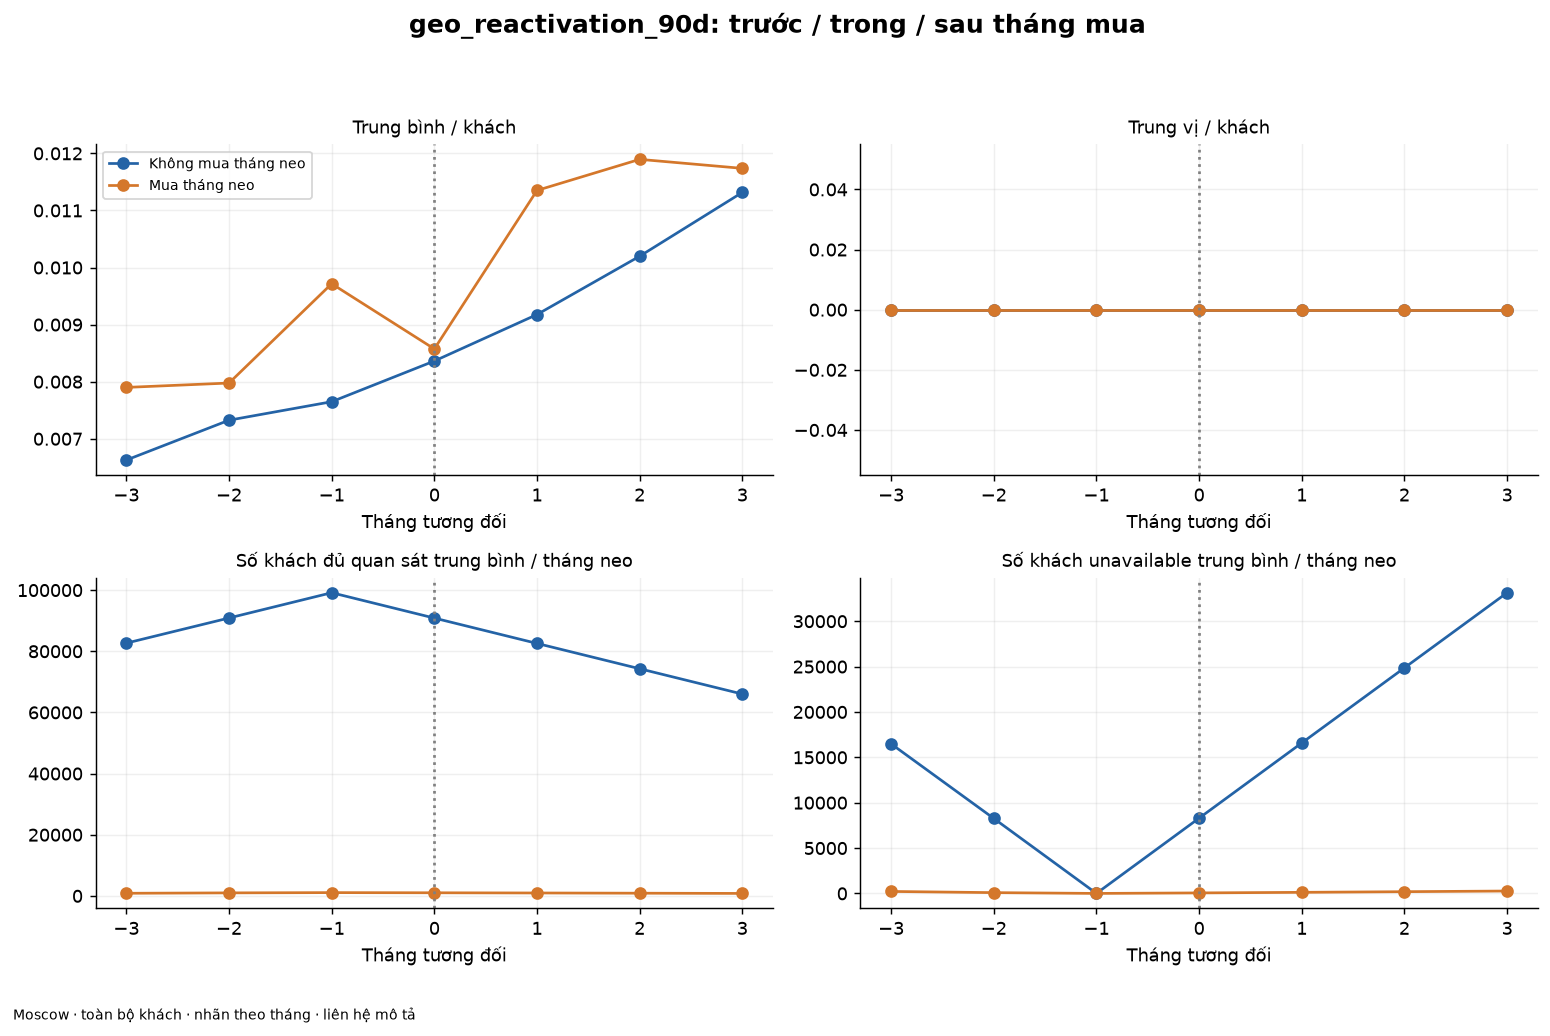

**outputs/eda_figures_moscow/event_geo_reactivation_90d_by_anchor.png**

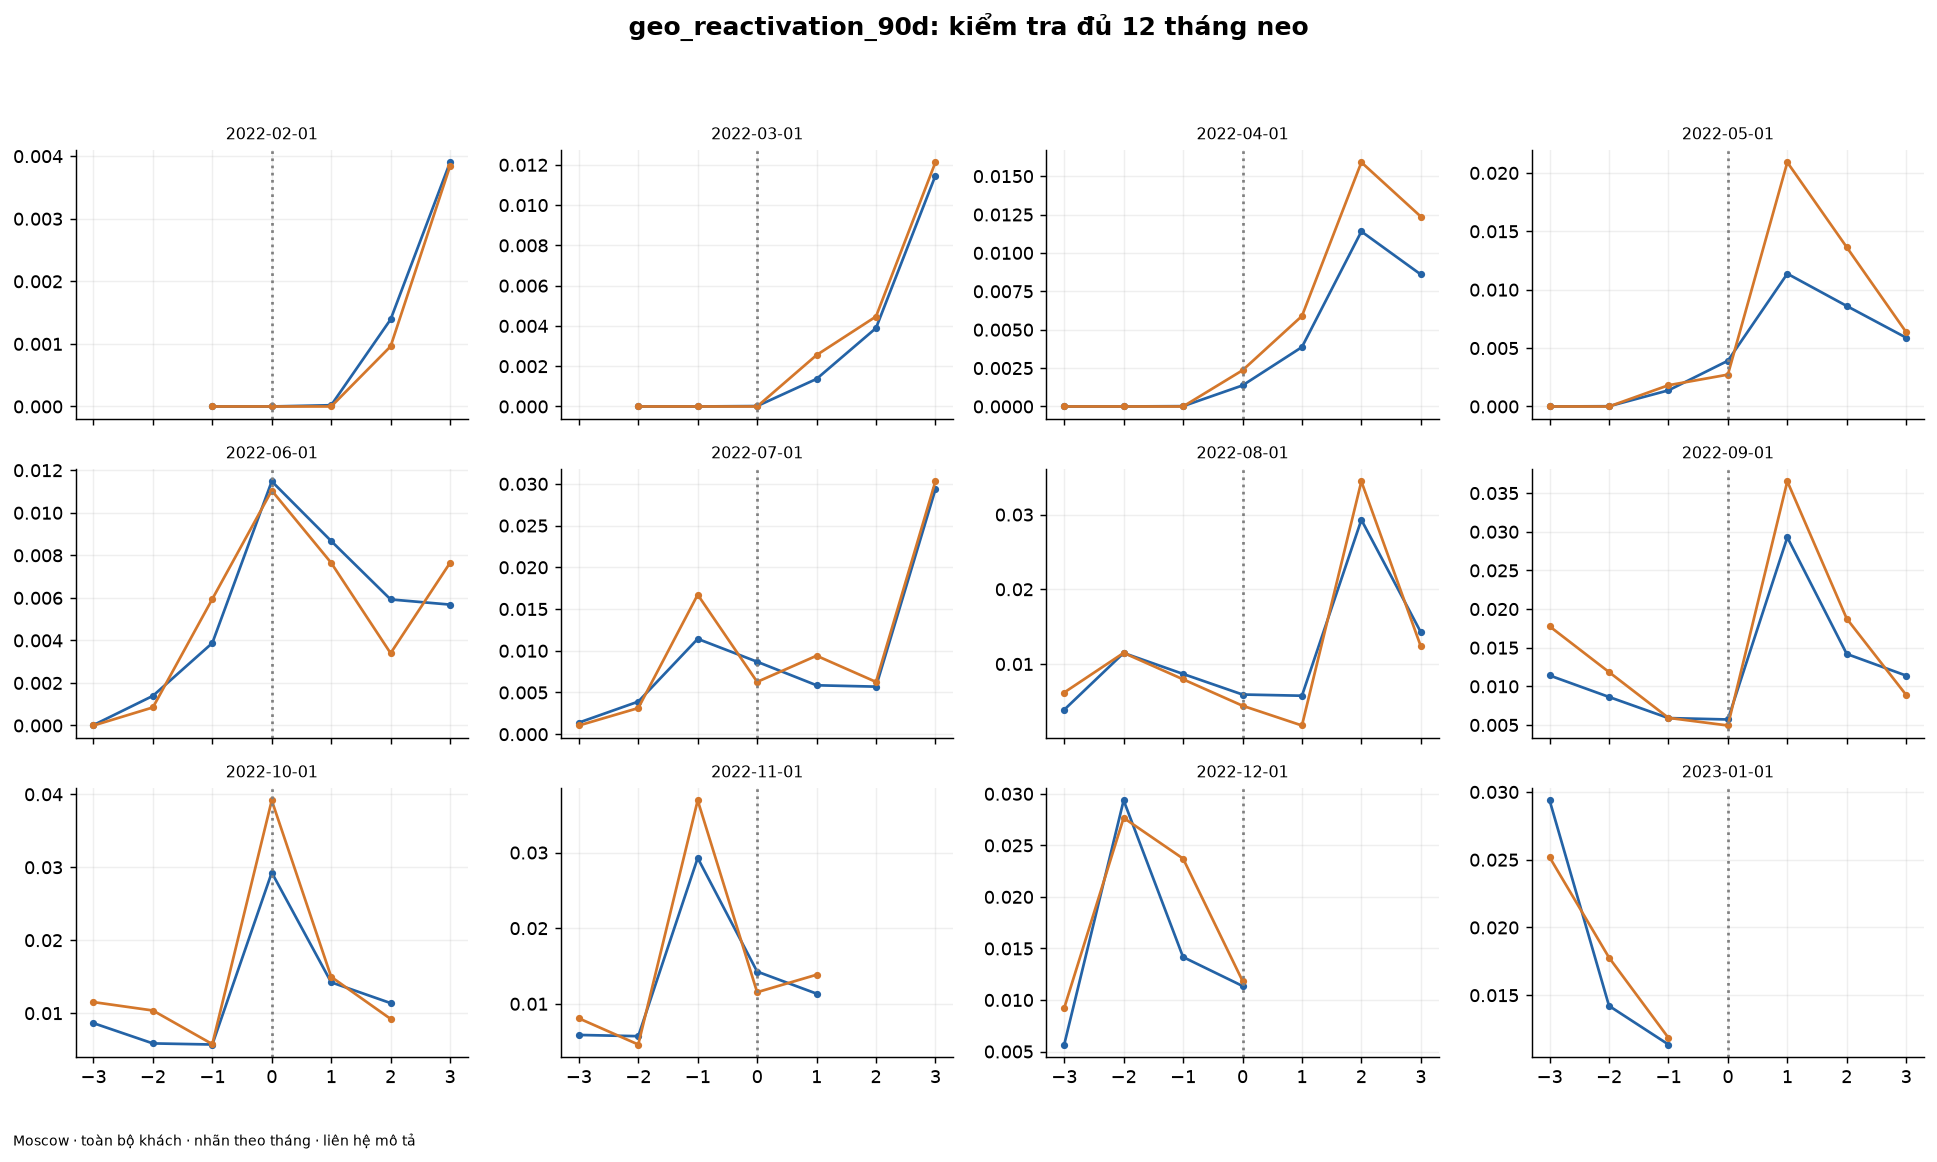

**outputs/eda_figures_moscow/event_trx_active_days.png**

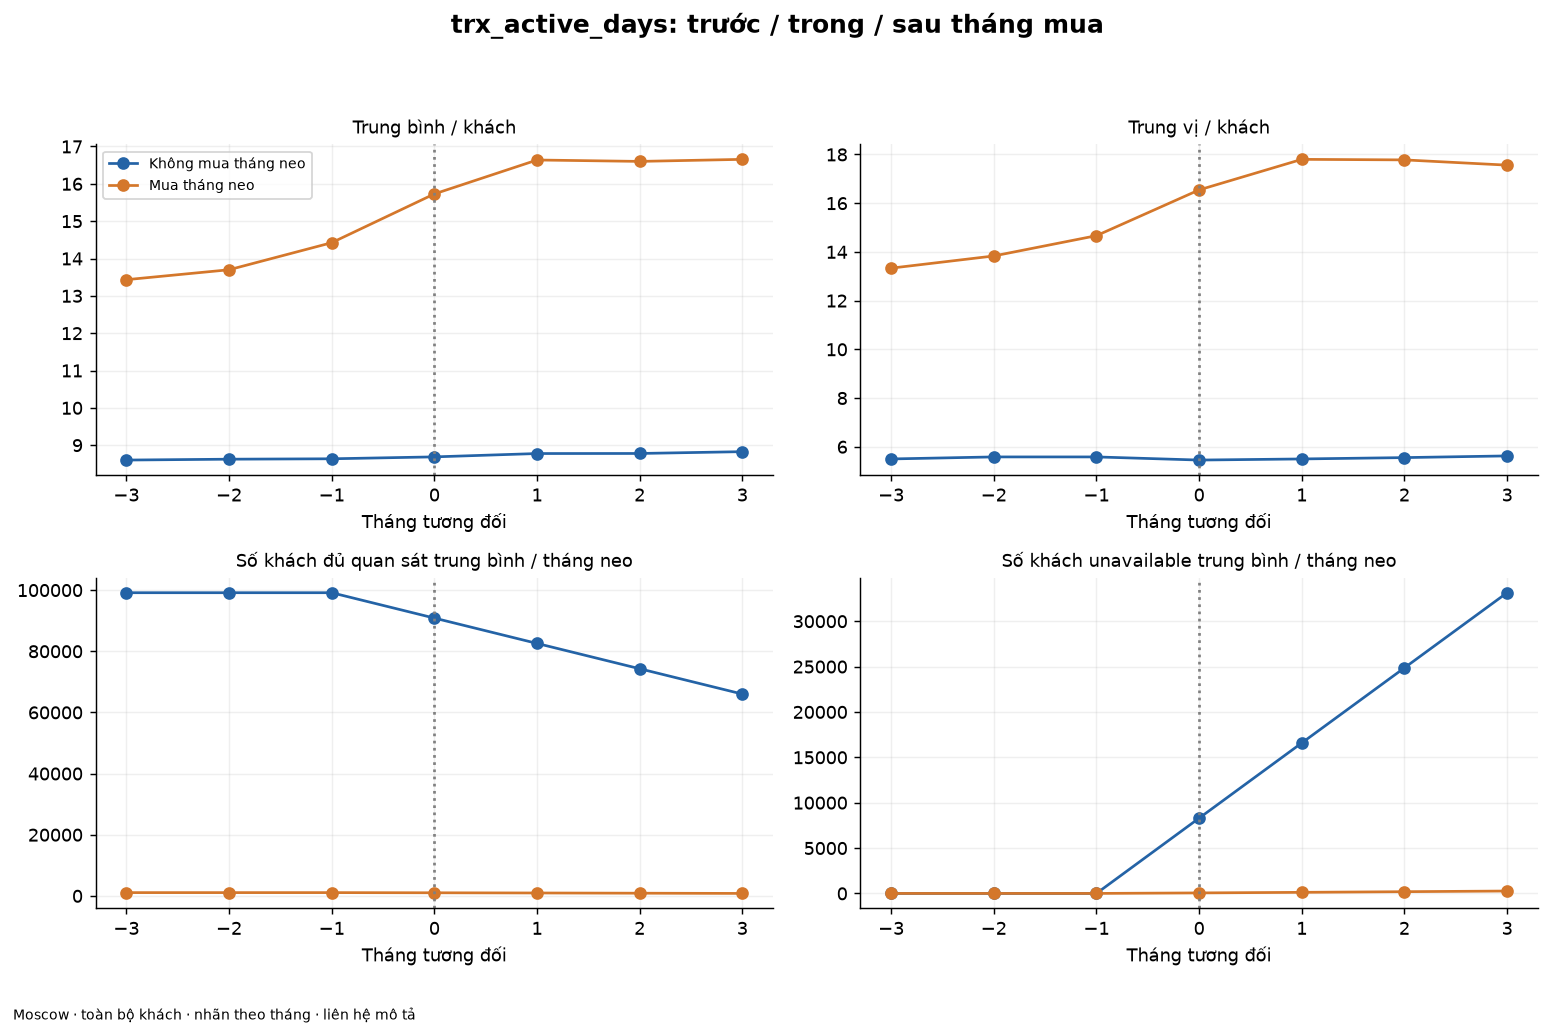

**outputs/eda_figures_moscow/event_trx_active_days_by_anchor.png**

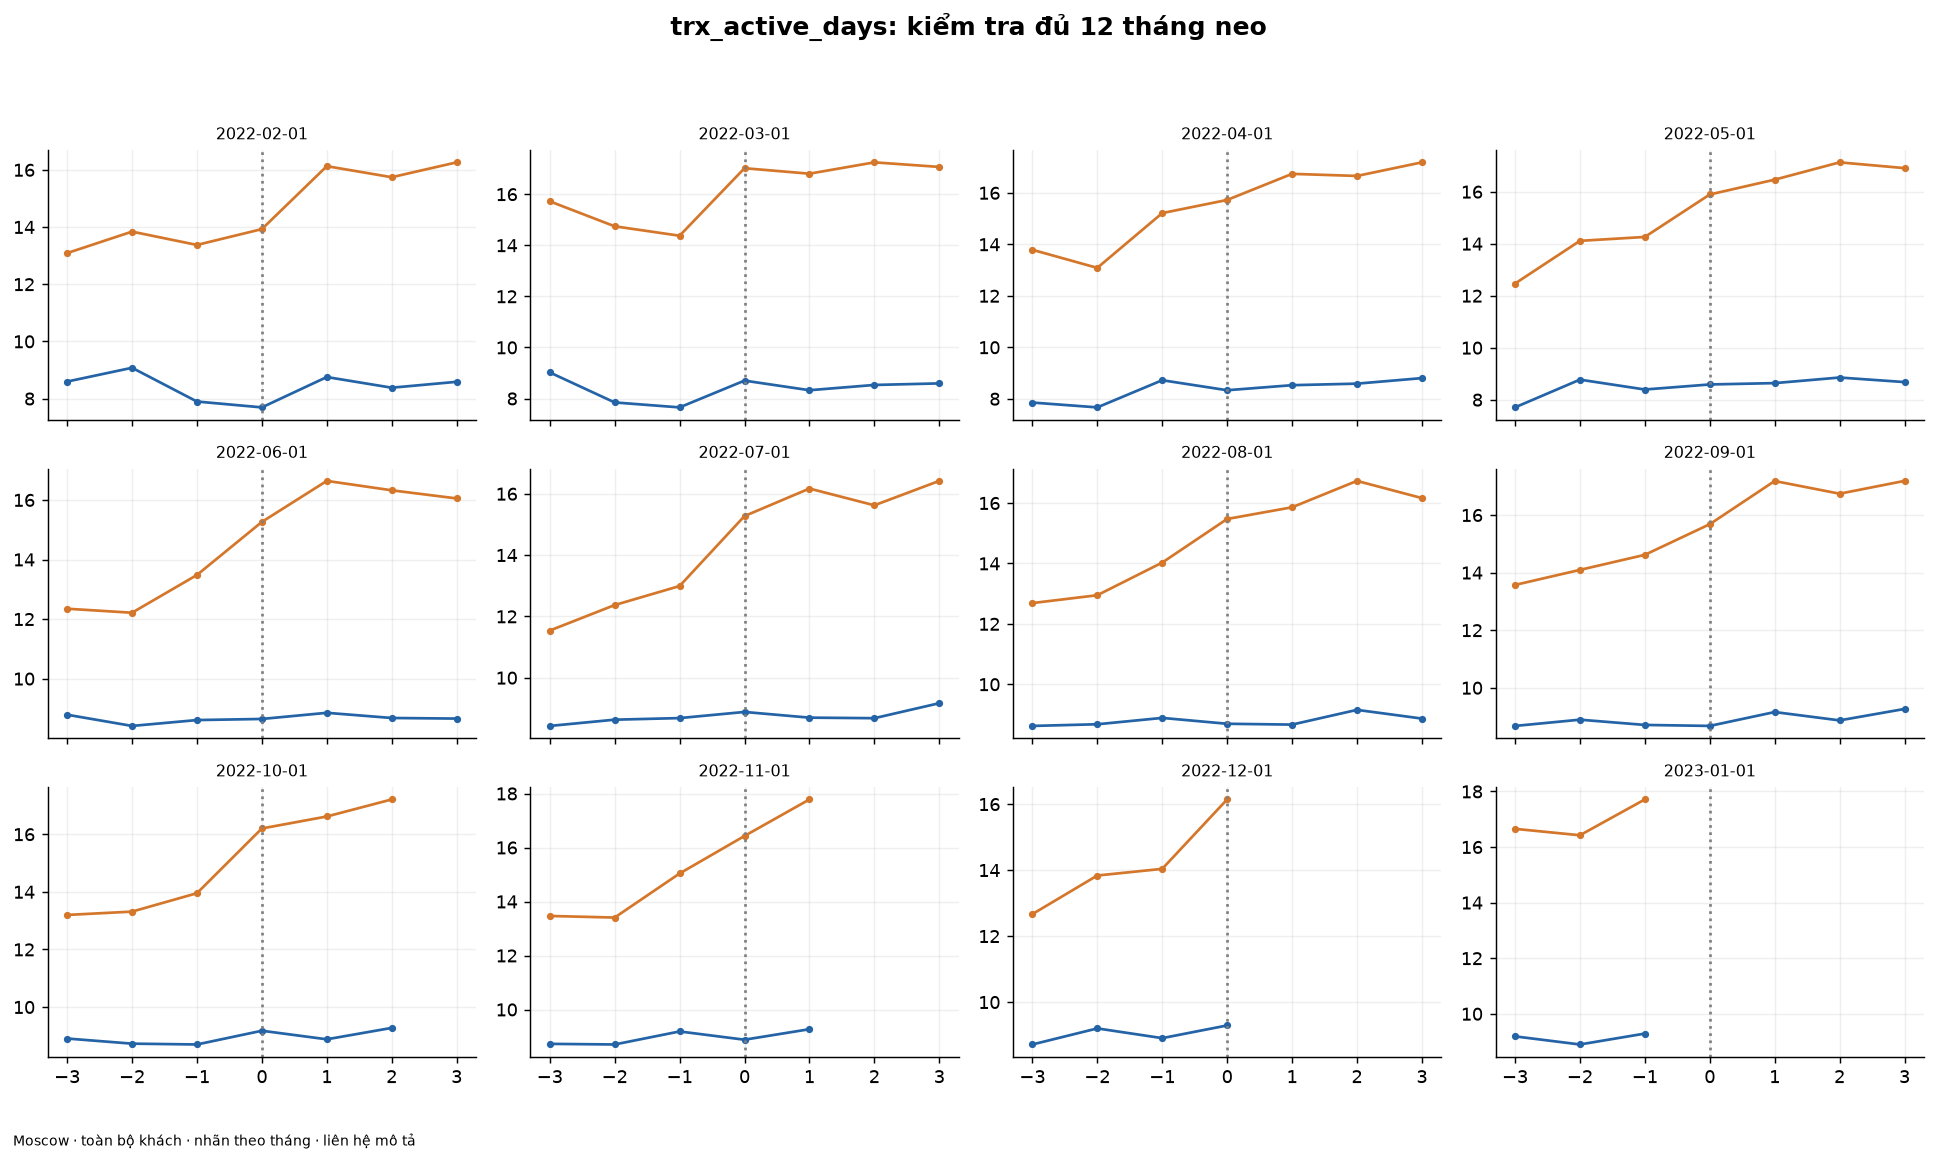

**outputs/eda_figures_moscow/event_trx_reactivation_30d.png**

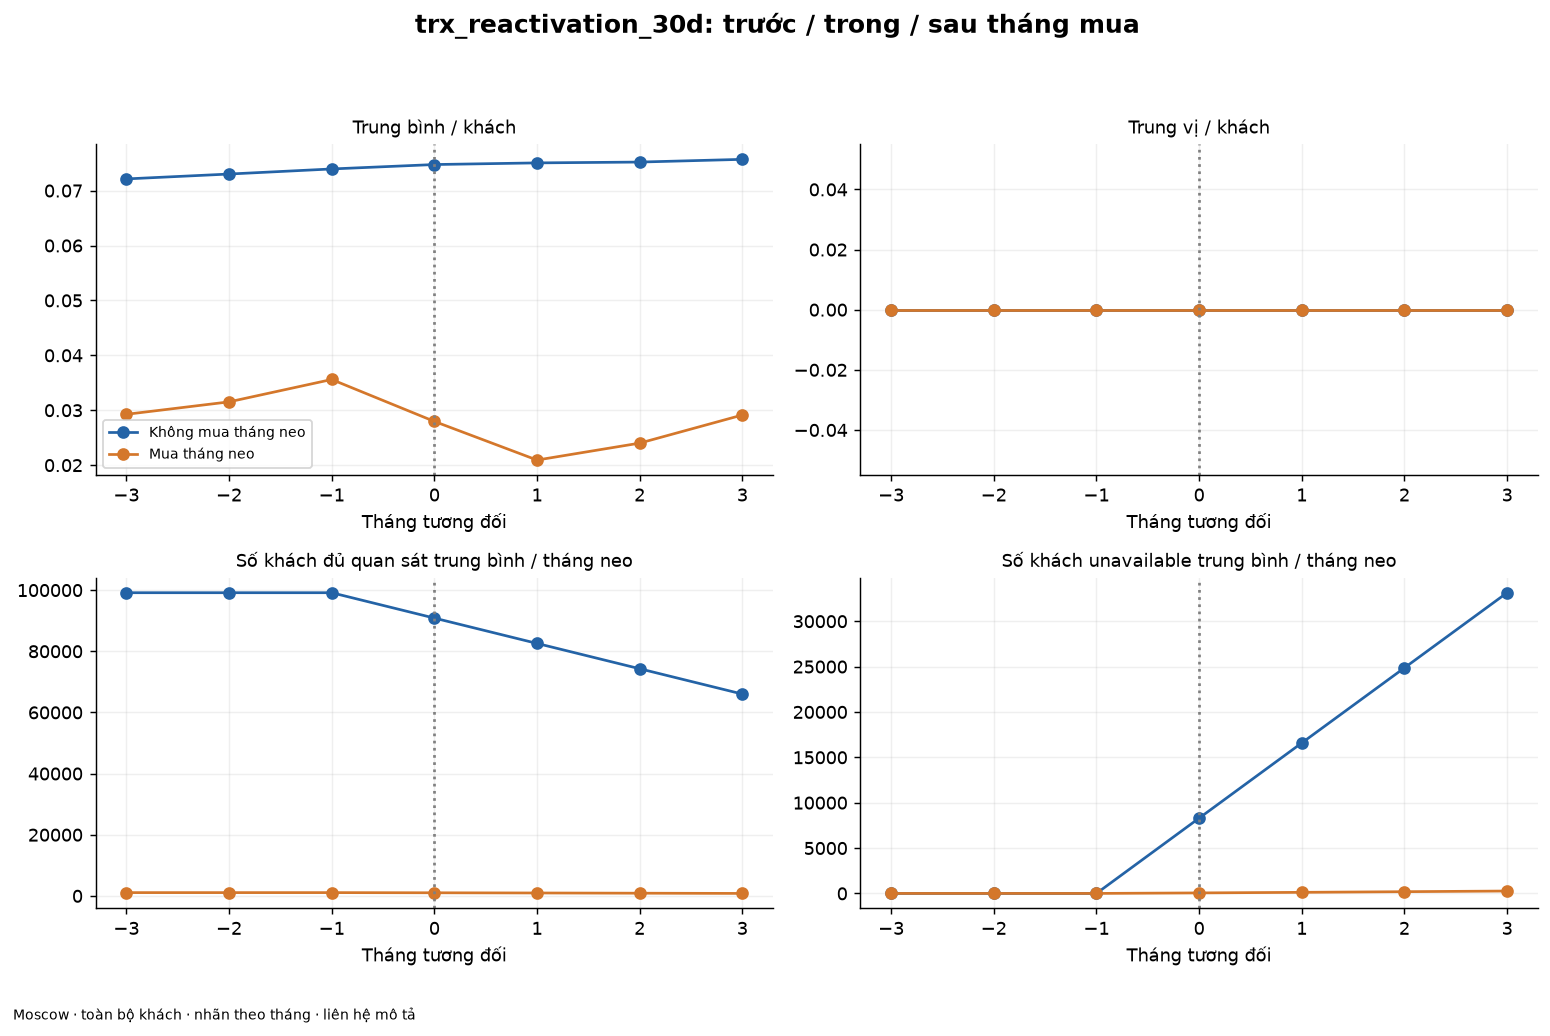

**outputs/eda_figures_moscow/event_trx_reactivation_30d_by_anchor.png**

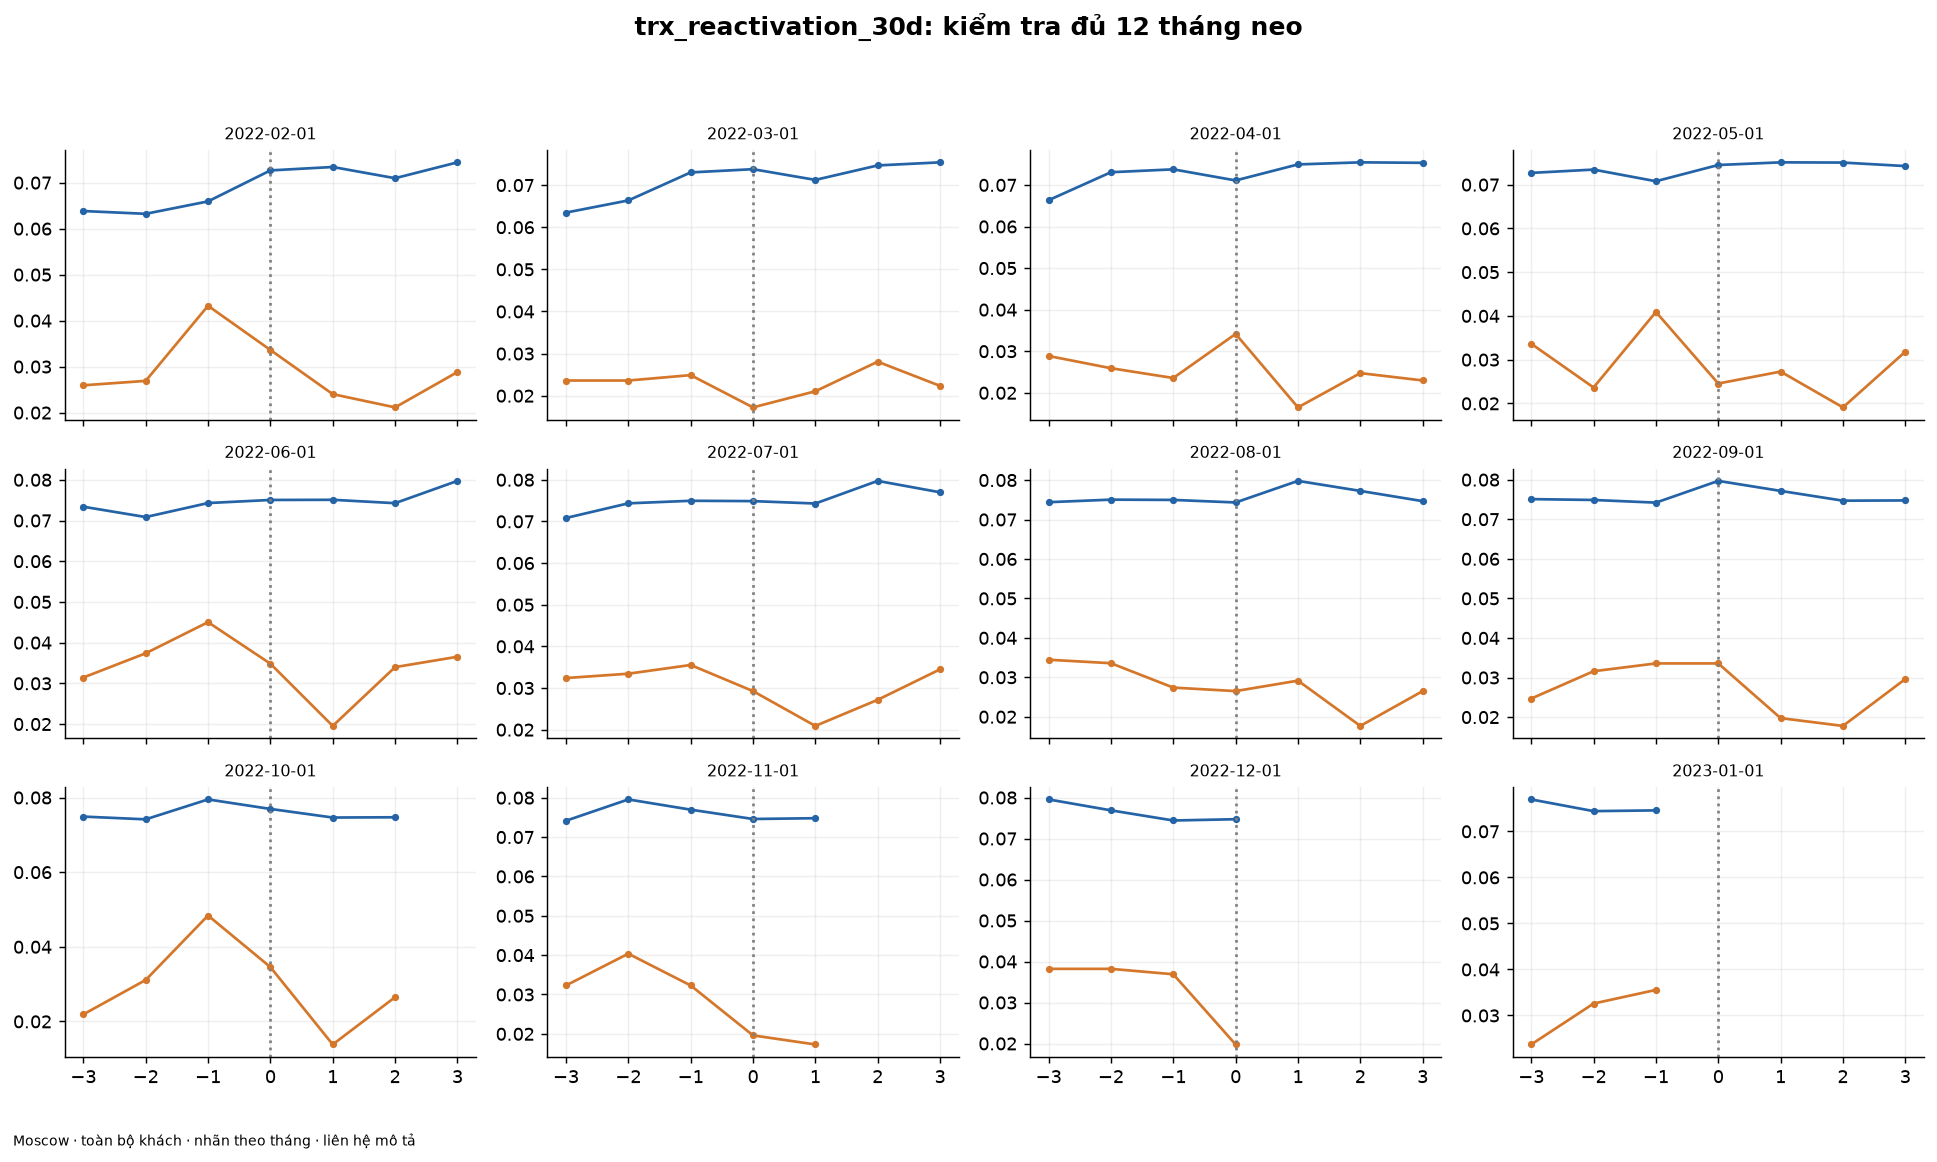

**outputs/eda_figures_moscow/event_trx_reactivation_60d.png**

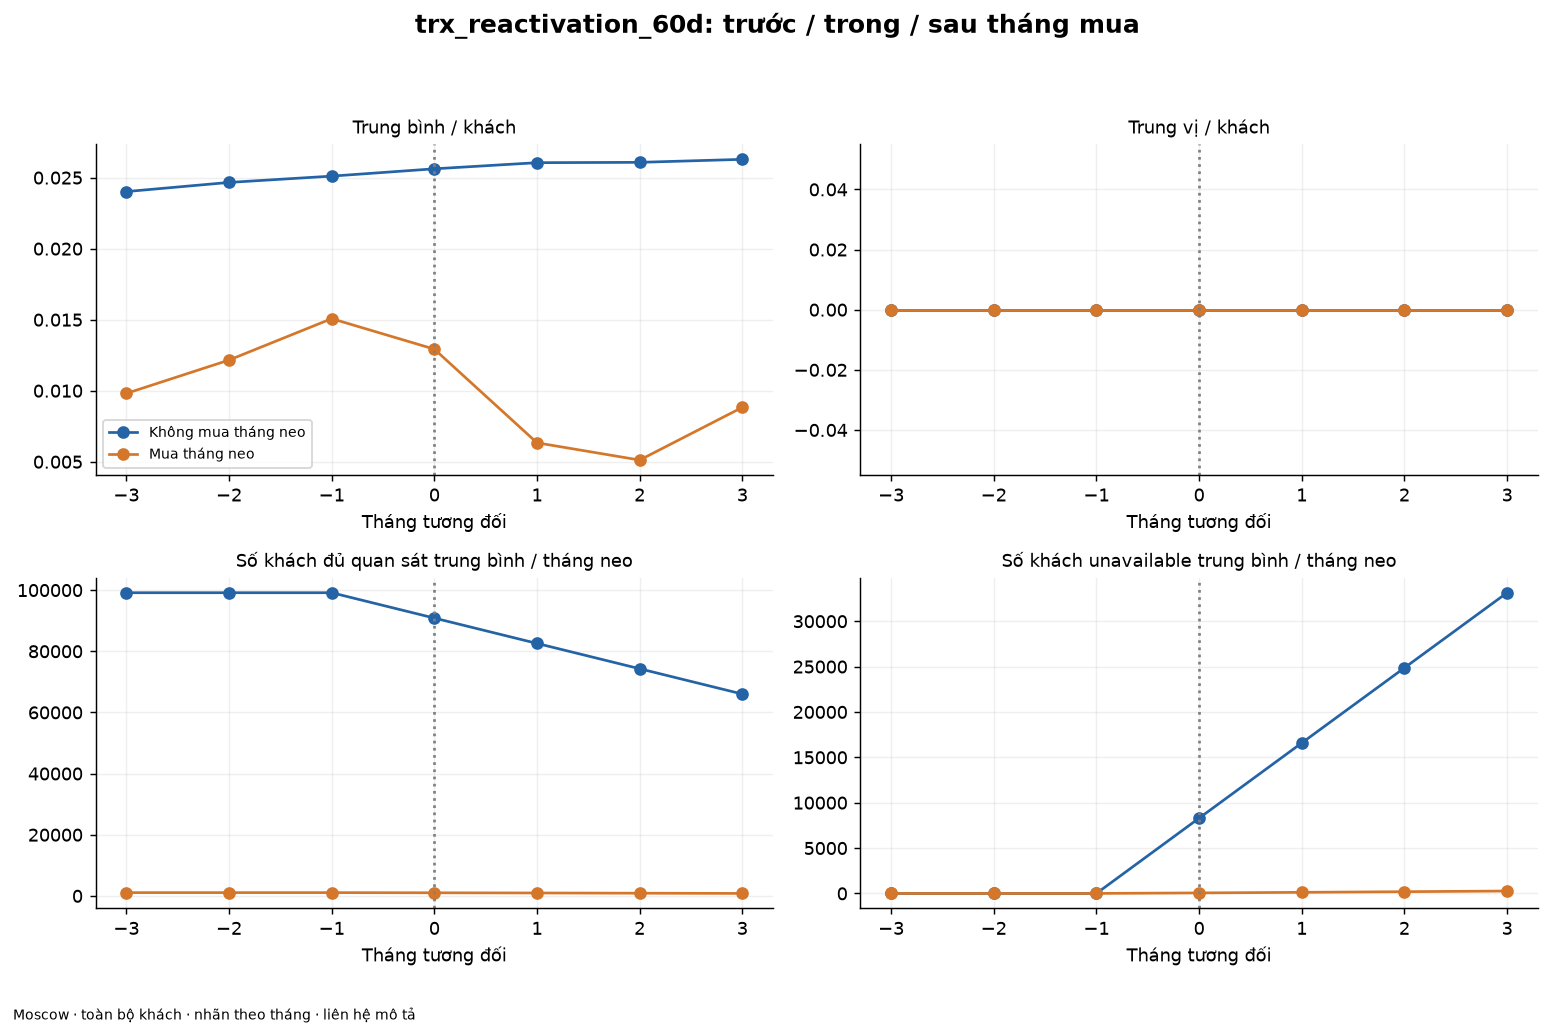

**outputs/eda_figures_moscow/event_trx_reactivation_60d_by_anchor.png**

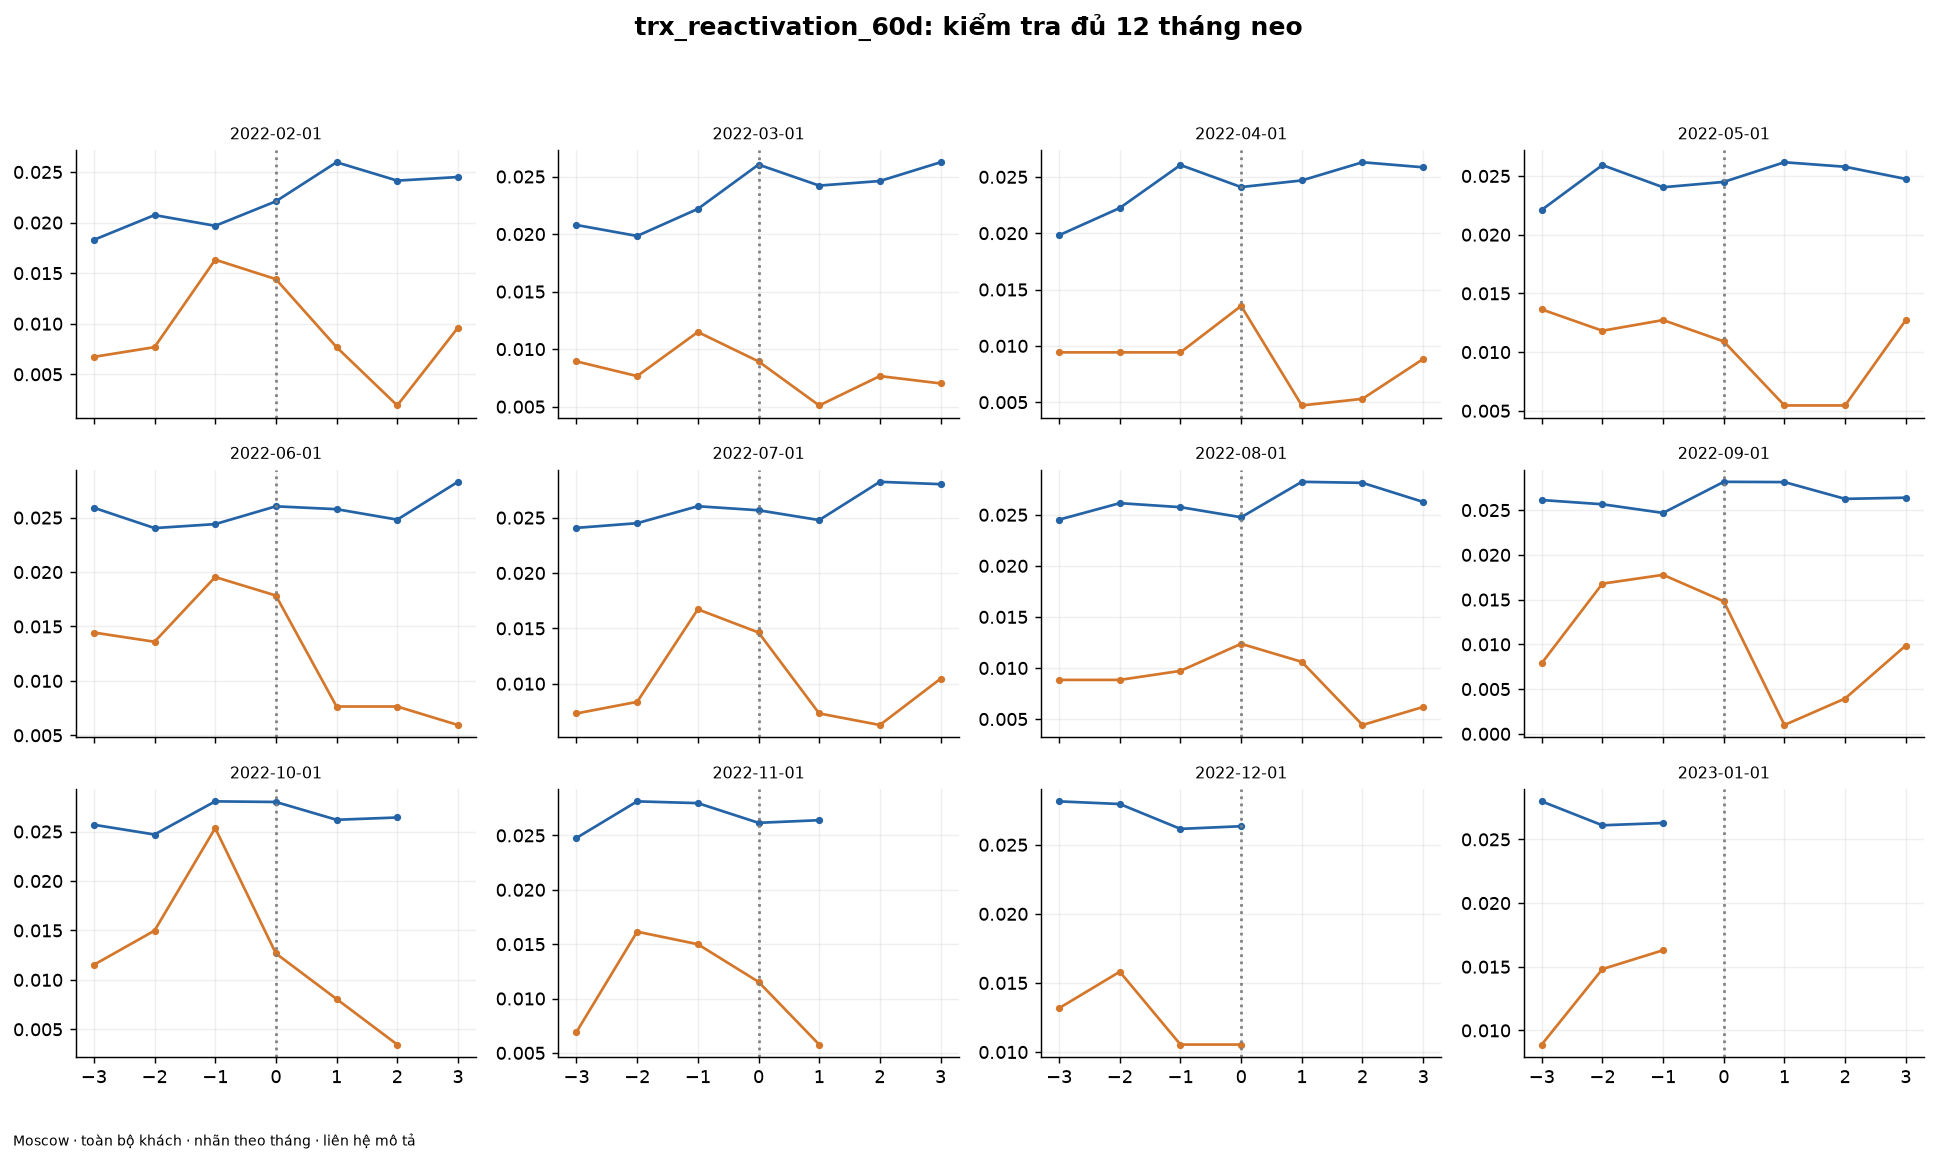

**outputs/eda_figures_moscow/event_trx_reactivation_90d.png**

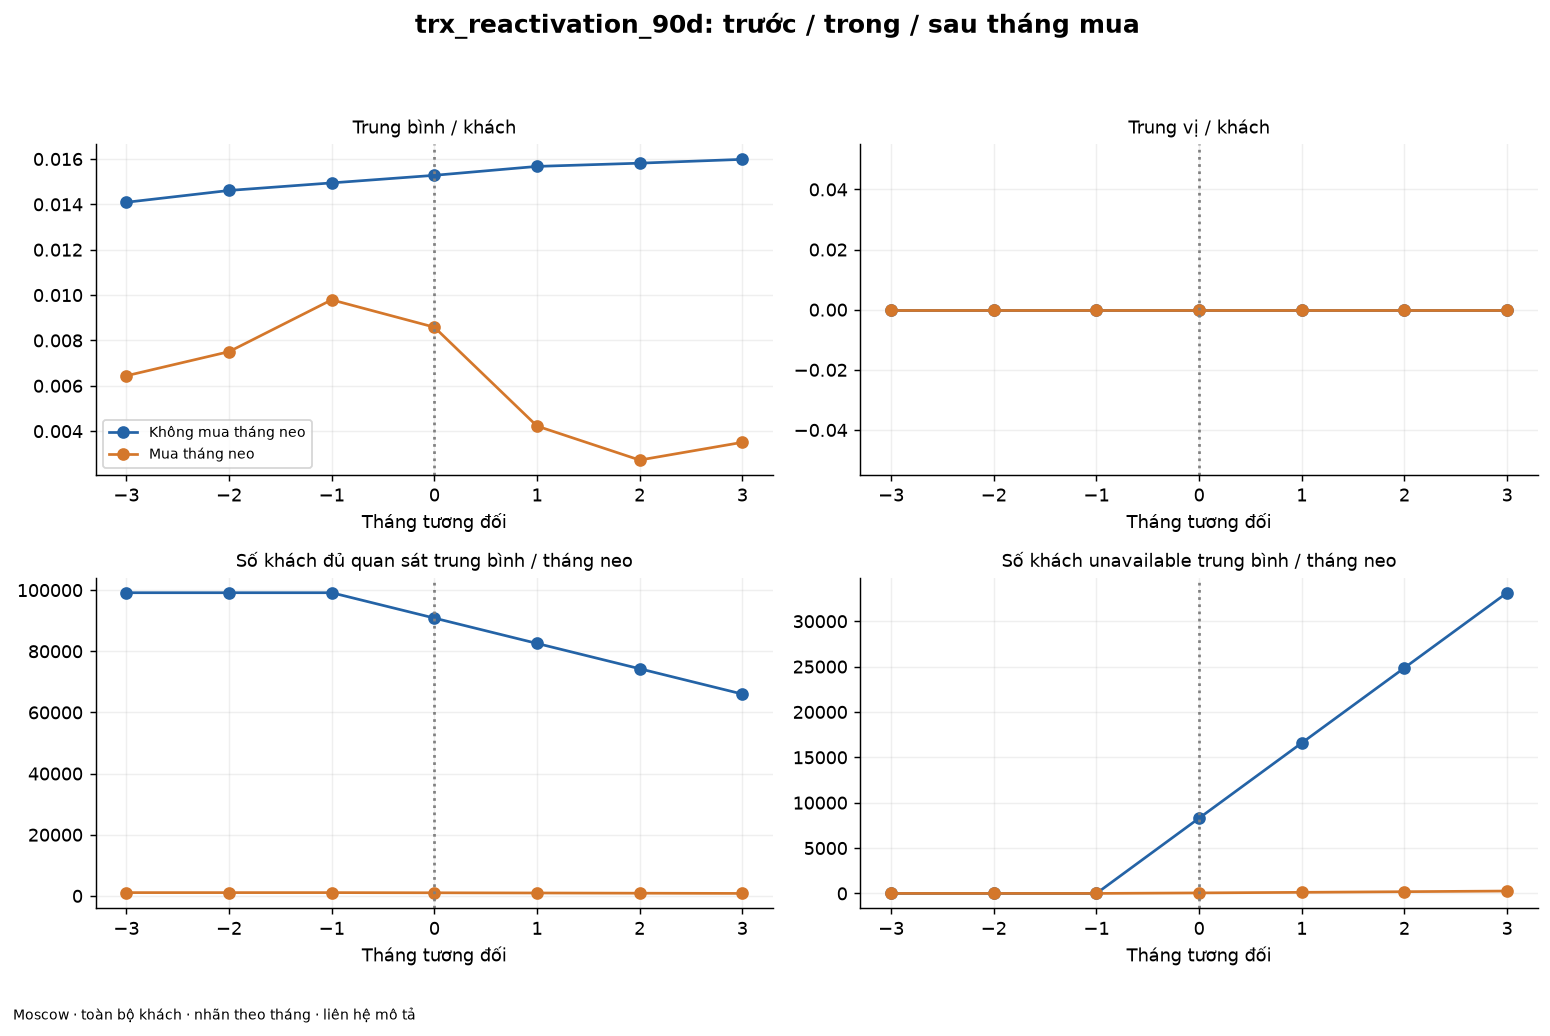

**outputs/eda_figures_moscow/event_trx_reactivation_90d_by_anchor.png**

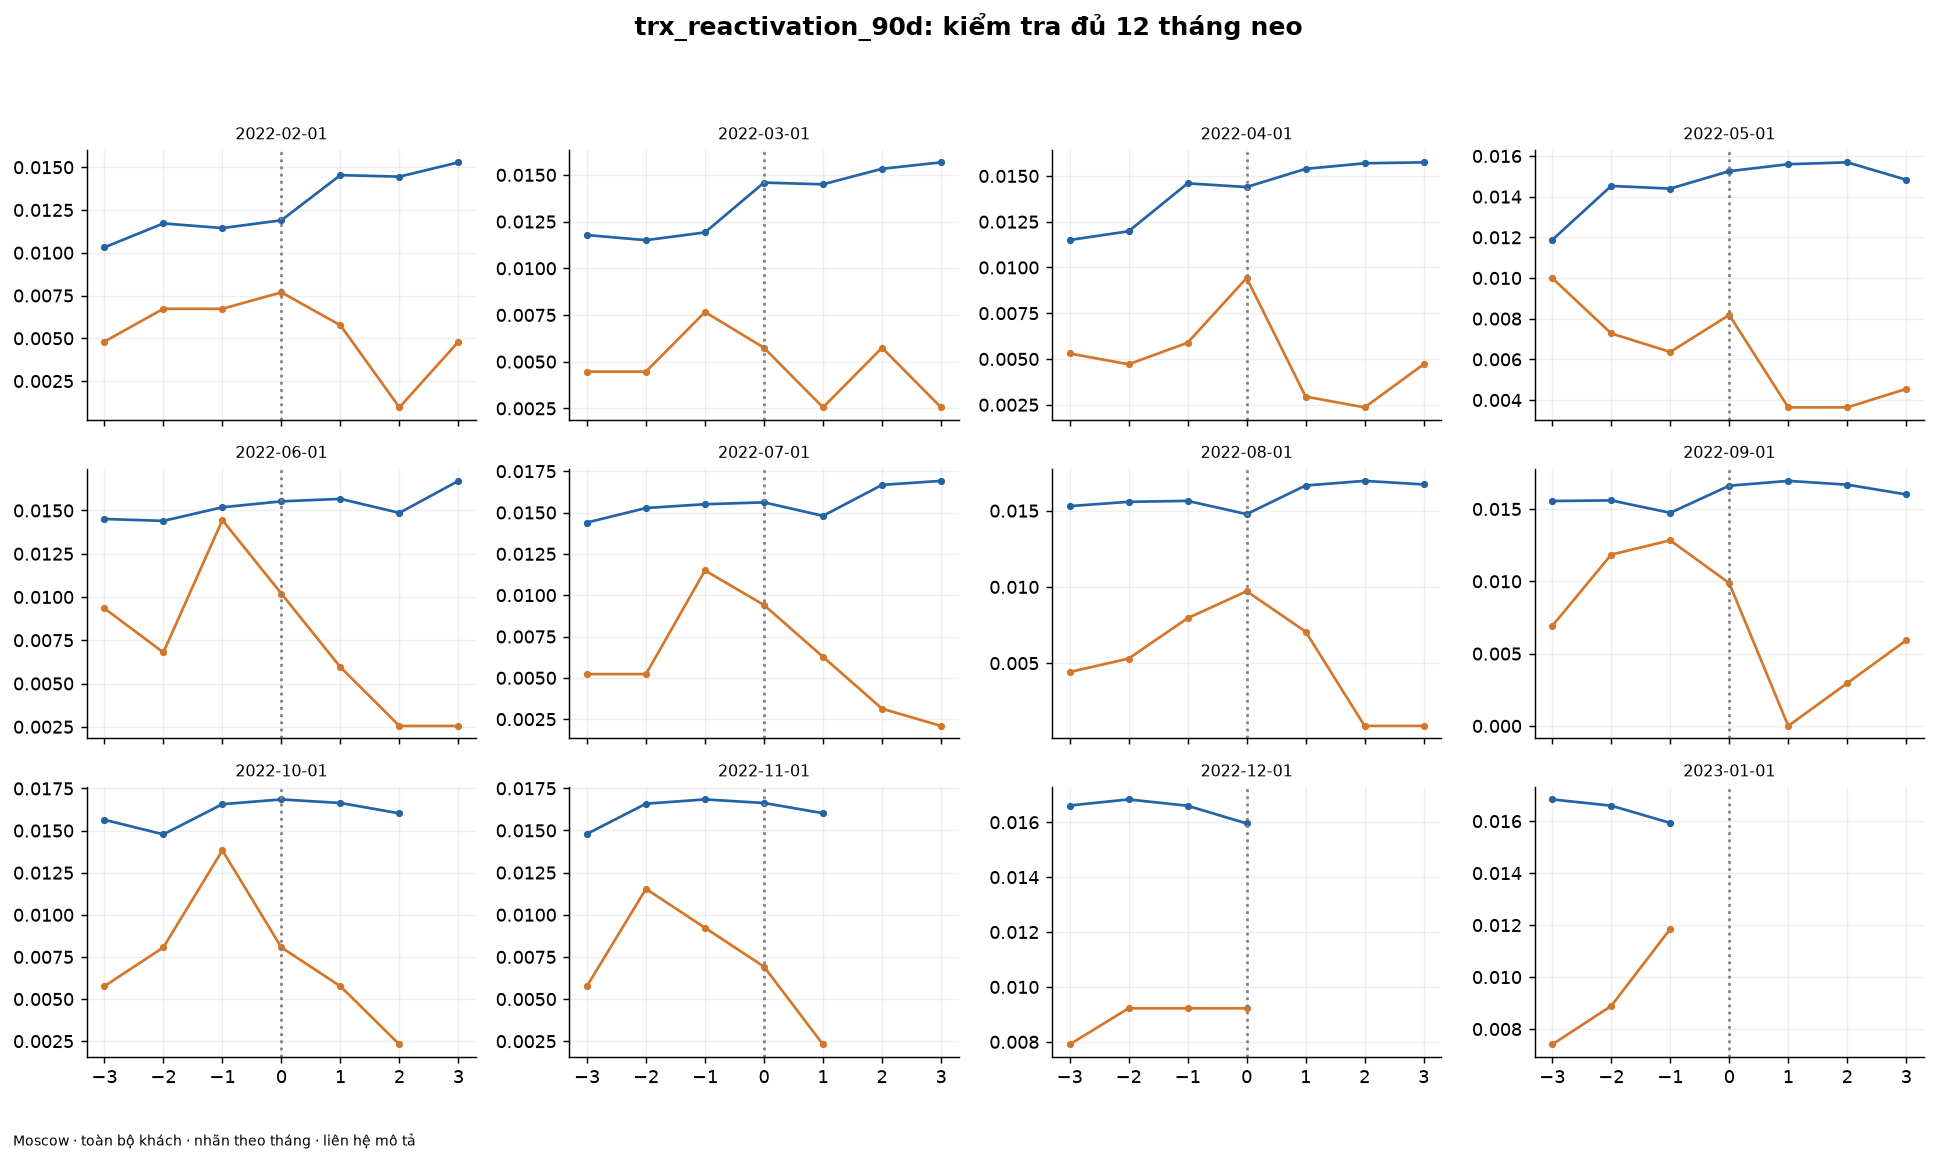

**outputs/eda_figures_moscow/reactivation_population_states.png**

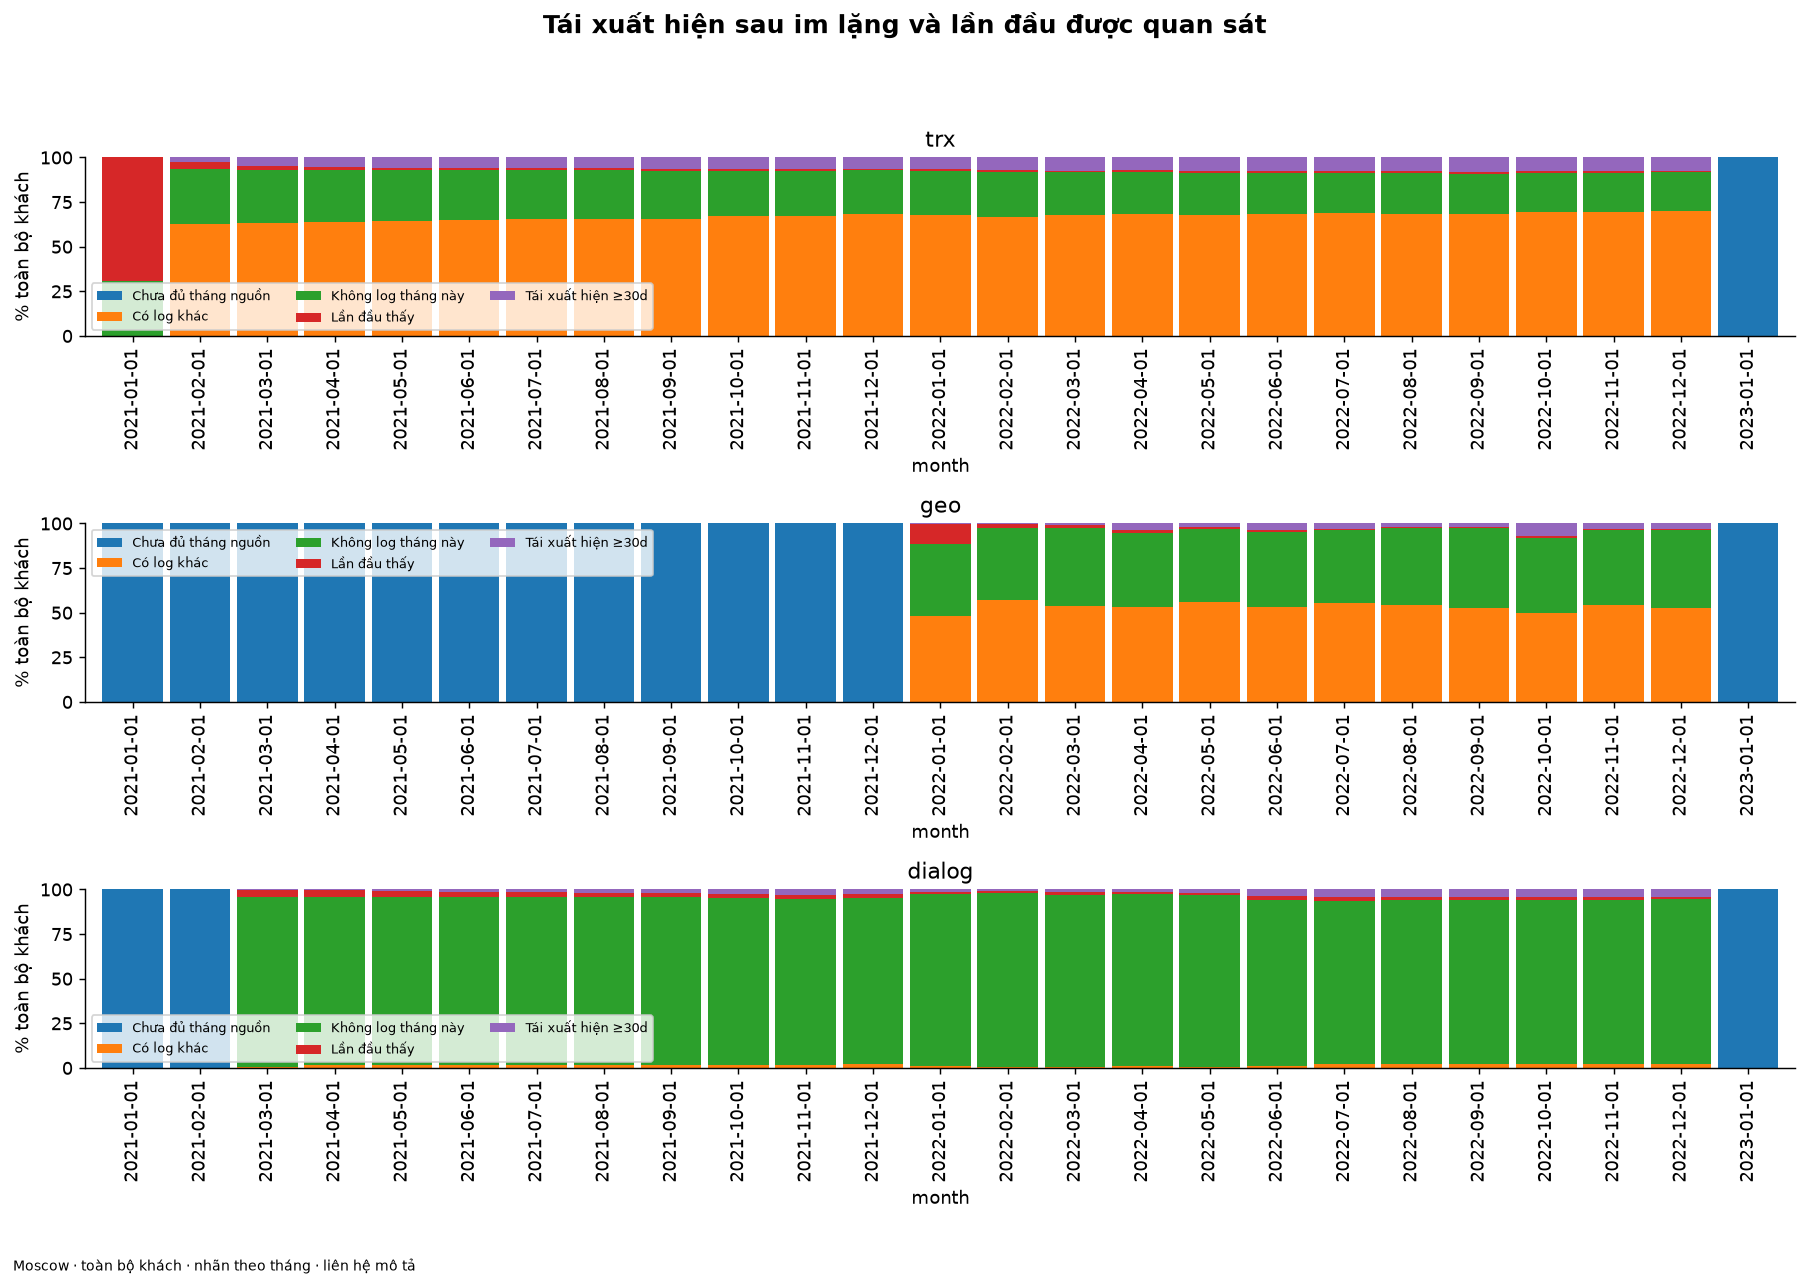

**outputs/eda_figures_moscow/baseline_dialog_active_days.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,dialog_active_days,2022-02-01,-3,0,99183,99183,0,0.115252,0.0,99183,0,75414,96820,0.094547,0.067421,0.015164,0.917415
1,dialog_active_days,2022-02-01,-3,1,1041,1041,0,0.315082,0.0,1041,0,562,968,0.256004,0.166186,0.031700,0.802113
2,dialog_active_days,2022-02-01,-2,0,99183,99183,0,0.114163,0.0,99183,0,75414,96820,0.093459,0.065747,0.016475,0.917778
3,dialog_active_days,2022-02-01,-2,1,1041,1041,0,0.326609,0.0,1041,0,562,968,0.267531,0.176753,0.047070,0.776177
4,dialog_active_days,2022-02-01,-1,0,99183,99183,0,0.047841,0.0,99183,0,75414,96820,0.027137,0.034038,0.020790,0.945172


**outputs/eda_figures_moscow/baseline_dialog_reactivation_30d.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,dialog_reactivation_30d,2022-02-01,-3,0,99183,99183,0,0.028876,0.0,99183,0,91124,99145,0.028679,0.028876,0.000333,0.970791
1,dialog_reactivation_30d,2022-02-01,-3,1,1041,1041,0,0.082613,0.0,1041,0,832,1039,0.081652,0.082613,0.001921,0.915466
2,dialog_reactivation_30d,2022-02-01,-2,0,99183,99183,0,0.026728,0.0,99183,0,91124,99145,0.026532,0.026728,0.000282,0.972989
3,dialog_reactivation_30d,2022-02-01,-2,1,1041,1041,0,0.075889,0.0,1041,0,832,1039,0.074928,0.075889,0.001921,0.922190
4,dialog_reactivation_30d,2022-02-01,-1,0,99183,99183,0,0.014367,0.0,99183,0,91124,99145,0.014171,0.014367,0.000353,0.985280


**outputs/eda_figures_moscow/baseline_dialog_reactivation_60d.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,dialog_reactivation_60d,2022-02-01,-3,0,99183,99183,0,0.019469,0.0,99183,0,93916,99183,0.019469,0.019469,0.0,0.980531
1,dialog_reactivation_60d,2022-02-01,-3,1,1041,1041,0,0.047070,0.0,1041,0,894,1041,0.047070,0.047070,0.0,0.952930
2,dialog_reactivation_60d,2022-02-01,-2,0,99183,99183,0,0.018239,0.0,99183,0,93916,99183,0.018239,0.018239,0.0,0.981761
3,dialog_reactivation_60d,2022-02-01,-2,1,1041,1041,0,0.052834,0.0,1041,0,894,1041,0.052834,0.052834,0.0,0.947166
4,dialog_reactivation_60d,2022-02-01,-1,0,99183,99183,0,0.009205,0.0,99183,0,93916,99183,0.009205,0.009205,0.0,0.990795


... (71 outputs left out)

,figure,title,data,explanation
0,all_history_recency_by_purchase_month,Recency toàn lịch sử trước đầu tháng mua,all_history_recency_by_purchase_month.csv,all_history_recency_by_purchase_month.md
1,baseline_amount11,amount11: thay đổi so với nền của chính khách,baseline_amount11.csv,baseline_amount11.md
2,baseline_dialog,dialog: thay đổi so với nền của chính khách,baseline_dialog.csv,baseline_dialog.md
3,baseline_event_type_new_cells,event_type_new_cells: thay đổi so với nền của ...,baseline_event_type_new_cells.csv,baseline_event_type_new_cells.md
4,baseline_event_type_unique_cells,event_type_unique_cells: thay đổi so với nền c...,baseline_event_type_unique_cells.csv,baseline_event_type_unique_cells.md


**outputs/eda_figures_moscow/reactivation_population_states.csv** — 5 dòng đầu

,source,month,state,customers
0,trx,2021-01-01,Lần đầu thấy,69205
1,trx,2021-01-01,Tái xuất hiện ≥30d,0
2,trx,2021-01-01,Có log khác,0
3,trx,2021-01-01,Không log tháng này,31019
4,trx,2021-02-01,Lần đầu thấy,3877


File kết quả khác: `outputs/eda_figures_moscow/baseline_dialog_active_days.md`, `outputs/eda_figures_moscow/baseline_dialog_reactivation_30d.md`, `outputs/eda_figures_moscow/baseline_dialog_reactivation_60d.md`, `outputs/eda_figures_moscow/baseline_dialog_reactivation_90d.md`, `outputs/eda_figures_moscow/baseline_geo_active_days.md`, `outputs/eda_figures_moscow/baseline_geo_reactivation_30d.md`, `outputs/eda_figures_moscow/baseline_geo_reactivation_60d.md`, `outputs/eda_figures_moscow/baseline_geo_reactivation_90d.md`, `outputs/eda_figures_moscow/baseline_trx_active_days.md`, `outputs/eda_figures_moscow/baseline_trx_reactivation_30d.md`, `outputs/eda_figures_moscow/baseline_trx_reactivation_60d.md`, `outputs/eda_figures_moscow/baseline_trx_reactivation_90d.md`, `outputs/eda_figures_moscow/cross_source_daily_synchrony.md`, `outputs/eda_figures_moscow/event_dialog_active_days.md`, `outputs/eda_figures_moscow/event_dialog_active_days_by_anchor.md`, `outputs/eda_figures_moscow/event_dialog_reactivation_30d.md`, `outputs/eda_figures_moscow/event_dialog_reactivation_30d_by_anchor.md`, `outputs/eda_figures_moscow/event_dialog_reactivation_60d.md`, `outputs/eda_figures_moscow/event_dialog_reactivation_60d_by_anchor.md`, `outputs/eda_figures_moscow/event_dialog_reactivation_90d.md`, `outputs/eda_figures_moscow/event_dialog_reactivation_90d_by_anchor.md`, `outputs/eda_figures_moscow/event_geo_active_days.md`, `outputs/eda_figures_moscow/event_geo_active_days_by_anchor.md`, `outputs/eda_figures_moscow/event_geo_reactivation_30d.md`, `outputs/eda_figures_moscow/event_geo_reactivation_30d_by_anchor.md`, `outputs/eda_figures_moscow/event_geo_reactivation_60d.md`, `outputs/eda_figures_moscow/event_geo_reactivation_60d_by_anchor.md`, `outputs/eda_figures_moscow/event_geo_reactivation_90d.md`, `outputs/eda_figures_moscow/event_geo_reactivation_90d_by_anchor.md`, `outputs/eda_figures_moscow/event_trx_active_days.md`, `outputs/eda_figures_moscow/event_trx_active_days_by_anchor.md`, `outputs/eda_figures_moscow/event_trx_reactivation_30d.md`, `outputs/eda_figures_moscow/event_trx_reactivation_30d_by_anchor.md`, `outputs/eda_figures_moscow/event_trx_reactivation_60d.md`, `outputs/eda_figures_moscow/event_trx_reactivation_60d_by_anchor.md`, `outputs/eda_figures_moscow/event_trx_reactivation_90d.md`, `outputs/eda_figures_moscow/event_trx_reactivation_90d_by_anchor.md`, `outputs/eda_figures_moscow/execution_status.json`, `outputs/eda_figures_moscow/reactivation_population_states.md`

In [12]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_daily_moscow.py')